In [1]:


import os
import sys

sys.path.append('../')
sys.path.append('../anmodel')
import matplotlib.pyplot as plt

import anmodel


import numpy as np
import pandas as pd


from typing import Dict, List, Optional, Tuple, Union, Any

In [2]:
# U_list =  [0.01, 0.02, 0.05, 0.1, 0.3, 0.5, 0.7]
fig_dir = "/home/gpu_data/data8/kinoshita_simulation/simu_fig/" 
os.makedirs(fig_dir, exist_ok=True)

U_list =  [0.05, 0.5]

NE = 64
NI = 16
net_seed = 0
p_ee, p_ei, p_ie, p_ii = 0.2, 0.4, 0.5, 0.5
allow_self = False

In [3]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
from __future__ import annotations

import os
import pickle
import traceback
from pathlib import Path
from typing import Any, Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from networks import SANVesicleNetwork, UProfile


# ============================================================
# output
# ============================================================

fig_dir = "figures"
Path(fig_dir).mkdir(parents=True, exist_ok=True)


# ============================================================
# pickle loading
# ============================================================

def load_pickle_objects(path: str):
    objs = []
    with open(path, "rb") as f:
        while True:
            try:
                objs.append(pickle.load(f))
            except EOFError:
                break
    return objs


def extract_hits(objs):
    """
    Supported formats:
        - [niter(int), param_df(pd.DataFrame)]
        - pd.DataFrame
        - dict containing hits_df / param_df / hits / params
        - list[dict]
    """
    for o in objs:
        if isinstance(o, pd.DataFrame):
            return o.copy().reset_index(drop=True)

    for o in objs:
        if isinstance(o, dict):
            for k in ["hits_df", "param_df", "hits", "params"]:
                if k in o:
                    v = o[k]
                    if isinstance(v, pd.DataFrame):
                        return v.reset_index(drop=True)
                    if isinstance(v, list):
                        return pd.DataFrame(v).reset_index(drop=True)
                    if isinstance(v, dict):
                        return pd.DataFrame([v]).reset_index(drop=True)

    for o in objs:
        if isinstance(o, list) and len(o) > 0 and isinstance(o[0], dict):
            return pd.DataFrame(o).reset_index(drop=True)

    raise RuntimeError("Could not convert pickle contents to a hit DataFrame.")


# ============================================================
# spike detection
# ============================================================

def detect_spikes_upcross(v, t_ms, thresh=-20.0):
    v = np.asarray(v, dtype=float)
    t_ms = np.asarray(t_ms, dtype=float)

    v0 = v[:-1]
    v1 = v[1:]

    idx = np.where((v0 < thresh) & (v1 >= thresh))[0] + 1
    return t_ms[idx]


# ============================================================
# parameter splitting
# ============================================================

def split_params(row_dict):
    """
    Split one hit row into intrinsic parameters and synaptic/network parameters.

    Analysis columns such as cv_u0p05, rate_u0p05, valid_u0p05 are ignored.
    """
    intrinsic_keys = {
        "g_leak",
        "g_kvhh",
        "g_cav",
        "g_kca",
        "g_nap",
        "t_ca",
    }

    syn_keys = {
        "g_ampar",
        "g_gabar",
        "tau_rec_e",
        "tau_rec_i",
        "tau_noise",
        "sigma_noise",

        # U-related keys
        "U",
        "U_E",
        "U_I",
        "U_I_fixed",
        "U0",
        "U1",
        "t0_ms",
        "t1_ms",

        "I_app",
        "seed",
        "p_ee",
        "p_ei",
        "p_ie",
        "p_ii",
        "allow_self",
        "NE",
        "NI",
    }

    intrinsic = {}
    syn = {}

    for k, v in row_dict.items():
        if v is None:
            continue

        if isinstance(v, float) and np.isnan(v):
            continue

        if k in intrinsic_keys:
            intrinsic[k] = float(v)
        elif k in syn_keys:
            syn[k] = v

    return intrinsic, syn


# ============================================================
# U_E-only setting
# ============================================================

def _scalar_float(x: Any, name: str = "value") -> float:
    if isinstance(x, (tuple, list, np.ndarray)):
        if len(x) != 1:
            raise ValueError(f"{name} must be scalar or one-element sequence, got {x}")
        x = x[0]
    return float(x)


def set_excitatory_U_only(net, U_E: float, U_I_fixed: float = 0.3):
    """
    Sweep only excitatory synaptic utilization U_E.
    Keep inhibitory synaptic utilization U_I fixed.

    Requires networks.SANVesicleNetwork to support set_U_E/set_U_I
    or set_U_pair.
    """
    U_E = _scalar_float(U_E, "U_E")
    U_I_fixed = _scalar_float(U_I_fixed, "U_I_fixed")

    if hasattr(net, "set_U_pair"):
        net.set_U_pair(U_E, U_I_fixed)

    elif hasattr(net, "set_U_E") and hasattr(net, "set_U_I"):
        net.set_U_E(U_E)
        net.set_U_I(U_I_fixed)

    else:
        raise RuntimeError(
            "SANVesicleNetwork does not support separate U_E and U_I. "
            "Patch networks.py first."
        )

    # backward-compatible attributes
    net.U_E = U_E
    net.U_I = U_I_fixed
    net.U = U_E

    if hasattr(net, "u_profile"):
        net.u_profile = UProfile(
            U0=U_E,
            U1=U_E,
            t0_ms=0.0,
            t1_ms=0.0,
        )


# ============================================================
# one-U simulation
# ============================================================

def run_and_raster_oneU(
    net,
    U,
    T_ms=20000.0,
    dt_ms=0.1,
    record_every=10,
    thr=-20.0,
    U_I_fixed: float = 0.3,
):
    """
    Run one simulation.
    U means excitatory synaptic utilization U_E.
    Inhibitory utilization U_I is fixed.
    """
    set_excitatory_U_only(net, U_E=U, U_I_fixed=U_I_fixed)

    t_ms, v_mat = net.run_fixed_step(
        T_ms=T_ms,
        dt_ms=dt_ms,
        record_every=record_every,
        reset=True,
    )

    spk_times = []
    for i in range(v_mat.shape[1]):
        spk_times.append(
            detect_spikes_upcross(v_mat[:, i], t_ms, thresh=thr)
        )

    return t_ms, v_mat, spk_times


# ============================================================
# spike and population metrics
# ============================================================

def flatten_spike_times(spk_times, t_start_ms=None, t_end_ms=None):
    arrs = []

    for ts in spk_times:
        ts = np.asarray(ts, dtype=float)

        if ts.size == 0:
            continue

        if t_start_ms is not None:
            ts = ts[ts >= t_start_ms]

        if t_end_ms is not None:
            ts = ts[ts < t_end_ms]

        if ts.size > 0:
            arrs.append(ts)

    if len(arrs) == 0:
        return np.empty(0, dtype=float)

    out = np.concatenate(arrs)
    out.sort()
    return out


def mean_firing_rate_hz(spk_times, N, t_start_ms, t_end_ms):
    dur_ms = float(t_end_ms) - float(t_start_ms)

    if N <= 0 or dur_ms <= 0:
        return np.nan

    total_spikes = 0
    for ts in spk_times:
        ts = np.asarray(ts, dtype=float)
        total_spikes += int(np.sum((ts >= t_start_ms) & (ts < t_end_ms)))

    return float(total_spikes / (float(N) * (dur_ms / 1000.0)))


def cv_of_series(x):
    x = np.asarray(x, dtype=float)

    if x.size == 0:
        return np.nan

    mu = np.mean(x)

    if mu <= 0:
        return np.nan

    return float(np.std(x, ddof=0) / mu)


def spike_times_to_binary(
    spike_times,
    T_ms=3000.0,
    dt_ms=0.1,
    dtype=np.uint8,
):
    Nn = len(spike_times)
    n_bins = int(np.floor(T_ms / dt_ms))

    out = np.zeros((Nn, n_bins), dtype=dtype)

    for i, times in enumerate(spike_times):
        if times is None or len(times) == 0:
            continue

        t = np.asarray(times, dtype=float)

        mask = (t >= 0.0) & (t < T_ms)
        if not np.any(mask):
            continue

        idx = np.rint(t[mask] / dt_ms).astype(int)
        idx = np.clip(idx, 0, n_bins - 1)
        idx = np.unique(idx)

        out[i, idx] = 1

    return out


def evaluate_population_cv_from_spts(
    spts: np.ndarray,
    *,
    N_sel: int,
    dt_ms: float,
    t_start_ms: float,
    t_end_ms: float,
    cv_w_ms: float,
    moving_ms: float,
) -> Tuple[float, float]:
    """
    Population spike-count CV and mean firing rate.

    CV is computed from total population spike counts in sliding windows.
    rate_hz is mean firing rate per neuron.
    """
    spts = np.asarray(spts)

    if spts.ndim != 2:
        raise ValueError("spts must be 2D (N,T)")

    if N_sel <= 0 or N_sel > spts.shape[0]:
        return np.nan, 0.0

    start = int(round(t_start_ms / dt_ms))
    end = int(round(t_end_ms / dt_ms))

    start = max(0, min(spts.shape[1], start))
    end = max(0, min(spts.shape[1], end))

    if end <= start:
        return np.nan, 0.0

    pop = spts[:N_sel, start:end].sum(axis=0).astype(np.float64)

    dur_s = (end - start) * dt_ms * 1e-3
    if dur_s <= 0.0:
        return np.nan, 0.0

    total_spikes = float(pop.sum())
    rate_hz = total_spikes / (dur_s * float(N_sel))

    win = int(round(cv_w_ms / dt_ms))
    step = int(round(moving_ms / dt_ms))

    if win <= 0 or step <= 0 or pop.size < win:
        return np.nan, rate_hz

    starts = np.arange(0, pop.size - win + 1, step, dtype=int)

    if starts.size < 2:
        return np.nan, rate_hz

    csum = np.concatenate(([0.0], np.cumsum(pop)))
    win_sums = csum[starts + win] - csum[starts]

    m = float(win_sums.mean())

    if m <= 0.0:
        cv = 0.0
    else:
        cv = float(win_sums.std(ddof=0) / m)

    return cv, float(rate_hz)


# ============================================================
# sync_corr
# ============================================================

def build_binned_spike_matrix(
    spk_times,
    neuron_indices,
    t_start_ms,
    t_end_ms,
    bin_ms=5.0,
    binary=True,
):
    """
    Convert spike times into neuron x time-bin matrix.
    """
    neuron_indices = np.asarray(neuron_indices, dtype=int)

    if t_end_ms <= t_start_ms or bin_ms <= 0:
        return np.empty((0, 0), dtype=float), np.empty(0), np.empty(0)

    edges = np.arange(t_start_ms, t_end_ms + bin_ms, bin_ms, dtype=float)

    if edges.size < 2:
        edges = np.array([t_start_ms, t_end_ms], dtype=float)

    if edges[-1] < t_end_ms:
        edges = np.append(edges, t_end_ms)

    nbins = len(edges) - 1
    X = np.zeros((len(neuron_indices), nbins), dtype=float)

    for r, idx in enumerate(neuron_indices):
        ts = np.asarray(spk_times[idx], dtype=float)

        if ts.size == 0:
            continue

        ts = ts[(ts >= t_start_ms) & (ts < t_end_ms)]

        if ts.size == 0:
            continue

        counts, _ = np.histogram(ts, bins=edges)

        if binary:
            X[r, :] = (counts > 0).astype(float)
        else:
            X[r, :] = counts.astype(float)

    centers = 0.5 * (edges[:-1] + edges[1:])
    return X, edges, centers


def mean_pairwise_zero_lag_corr(X):
    """
    Mean zero-lag Pearson correlation between neurons.
    """
    X = np.asarray(X, dtype=float)

    if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] < 2:
        return np.nan, 0

    keep = np.std(X, axis=1) > 0
    Xk = X[keep]

    if Xk.shape[0] < 2:
        return np.nan, int(Xk.shape[0])

    C = np.corrcoef(Xk)
    iu = np.triu_indices(C.shape[0], k=1)

    if len(iu[0]) == 0:
        return np.nan, int(Xk.shape[0])

    return float(np.nanmean(C[iu])), int(Xk.shape[0])


def compute_time_resolved_sync_corr(
    spike_times,
    neuron_indices,
    t_start_ms: float,
    t_end_ms: float,
    *,
    bin_ms: float = 5.0,
    window_ms: float = 200.0,
    step_ms: float = 50.0,
    binary: bool = True,
):
    """
    Compute time-resolved sync_corr using sliding windows over binned spikes.
    """
    X, edges, _ = build_binned_spike_matrix(
        spk_times=spike_times,
        neuron_indices=neuron_indices,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        bin_ms=bin_ms,
        binary=binary,
    )

    if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] < 2:
        return (
            np.empty(0, dtype=float),
            np.empty(0, dtype=float),
            np.empty(0, dtype=int),
        )

    win_bins = max(int(round(window_ms / bin_ms)), 1)
    step_bins = max(int(round(step_ms / bin_ms)), 1)

    nbins = X.shape[1]

    if nbins < win_bins:
        corr, n_valid = mean_pairwise_zero_lag_corr(X)
        t_mid = 0.5 * (t_start_ms + t_end_ms)

        return (
            np.asarray([t_mid], dtype=float),
            np.asarray([corr], dtype=float),
            np.asarray([n_valid], dtype=int),
        )

    t_centers = []
    corr_vals = []
    n_valid_vals = []

    for start_bin in range(0, nbins - win_bins + 1, step_bins):
        end_bin = start_bin + win_bins
        Xw = X[:, start_bin:end_bin]

        corr, n_valid = mean_pairwise_zero_lag_corr(Xw)

        t_center = 0.5 * (edges[start_bin] + edges[end_bin])

        t_centers.append(float(t_center))
        corr_vals.append(float(corr) if np.isfinite(corr) else np.nan)
        n_valid_vals.append(int(n_valid))

    return (
        np.asarray(t_centers, dtype=float),
        np.asarray(corr_vals, dtype=float),
        np.asarray(n_valid_vals, dtype=int),
    )


def mean_participation_fraction_per_active_bin(X):
    """
    Mean fraction of participating neurons among bins with at least one spike.
    """
    X = np.asarray(X, dtype=float)

    if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
        return np.nan

    active_counts = np.sum(X > 0, axis=0)
    active_mask = active_counts >= 1

    if not np.any(active_mask):
        return np.nan

    frac = active_counts[active_mask] / X.shape[0]
    return float(np.mean(frac))


# ============================================================
# burst and max rate
# ============================================================

def detect_bursts(
    spikes,
    dt_ms=0.1,
    window_ms=10.0,
    moving_ms=5.0,
    threshold=80,
    merge_adjacent=True,
    max_duration_ms=250.0,
):
    """
    Detect population bursts based on total spike count in a short moving window.
    """
    spikes = np.asarray(spikes, dtype=np.uint8)

    if spikes.ndim != 2:
        raise ValueError("spikes must be 2D (N,T).")

    _, Tn = spikes.shape

    win_bins = int(round(window_ms / dt_ms))
    step_bins = int(round(moving_ms / dt_ms))

    if win_bins <= 0 or step_bins <= 0:
        raise ValueError("window_ms and moving_ms must be > 0.")

    pop = spikes.sum(axis=0)

    raw = []
    for start in range(0, Tn - win_bins + 1, step_bins):
        end = start + win_bins

        if int(pop[start:end].sum()) > int(threshold):
            raw.append([start * dt_ms, end * dt_ms])

    if not raw:
        return []

    merged = [raw[0][:]]

    for s_ms, e_ms in raw[1:]:
        ps_ms, pe_ms = merged[-1]

        overlap = (s_ms <= pe_ms) if merge_adjacent else (s_ms < pe_ms)

        if overlap:
            merged[-1][1] = max(pe_ms, e_ms)
        else:
            merged.append([s_ms, e_ms])

    if max_duration_ms is not None:
        merged = [
            b for b in merged
            if (b[1] - b[0]) <= max_duration_ms
        ]

    return merged


def filter_bursts_by_window(
    bursts,
    t_start_ms: float,
    t_end_ms: float,
    mode: str = "center",
):
    if bursts is None or len(bursts) == 0:
        return []

    selected = []

    for b in bursts:
        s_ms, e_ms = float(b[0]), float(b[1])

        if mode == "center":
            c_ms = 0.5 * (s_ms + e_ms)
            if (c_ms >= t_start_ms) and (c_ms < t_end_ms):
                selected.append([s_ms, e_ms])

        elif mode == "overlap":
            if (e_ms > t_start_ms) and (s_ms < t_end_ms):
                selected.append([s_ms, e_ms])

        else:
            raise ValueError("mode must be 'center' or 'overlap'.")

    return selected


def burst_rate_frequency(
    bursts,
    t_start_ms: float,
    t_end_ms: float,
):
    dur_s = (float(t_end_ms) - float(t_start_ms)) * 1e-3

    if dur_s <= 0.0:
        return 0.0

    if bursts is None:
        return 0.0

    return float(len(bursts) / dur_s)


def mean_burst_duration_from_bursts(bursts):
    if bursts is None or len(bursts) == 0:
        return 0.0

    durs = []

    for b in bursts:
        s_ms, e_ms = float(b[0]), float(b[1])

        if e_ms > s_ms:
            durs.append(e_ms - s_ms)

    if len(durs) == 0:
        return 0.0

    return float(np.mean(durs))


def burst_dur_freq(
    bursts,
    spts,
    dt_ms,
):
    """
    Returns:
        mean burst duration [ms]
        mean internal firing rate during bursts [Hz/active neuron]
    """
    if bursts is None or len(bursts) == 0:
        return 0.0, 0.0

    spts = np.asarray(spts)

    burst_durs = []
    burst_internal_rates = []

    for burst in bursts:
        start_ms, end_ms = float(burst[0]), float(burst[1])

        start = int(round(start_ms / dt_ms))
        end = int(round(end_ms / dt_ms))

        if end <= start:
            continue

        dur_ms = end_ms - start_ms
        dur_s = dur_ms * 1e-3

        if dur_s <= 0:
            continue

        burst_durs.append(dur_ms)

        burst_sps = np.sum(spts[:, start:end], axis=1)
        burst_N_active = int(np.sum(burst_sps > 0))

        if burst_N_active > 0:
            burst_internal_rates.append(
                float(np.sum(burst_sps) / dur_s / burst_N_active)
            )

    if len(burst_durs) == 0:
        return 0.0, 0.0

    mean_burst_duration = float(np.mean(burst_durs))

    if len(burst_internal_rates) == 0:
        mean_burst_internal_rate = 0.0
    else:
        mean_burst_internal_rate = float(np.mean(burst_internal_rates))

    return mean_burst_duration, mean_burst_internal_rate


def _as_neuron_time(spts, Nn):
    spts = np.asarray(spts)

    if spts.ndim != 2:
        raise ValueError(f"spts must be 2D. got shape={spts.shape}")

    if spts.shape[0] == Nn:
        return spts

    if spts.shape[1] == Nn:
        return spts.T

    raise ValueError(f"spts shape {spts.shape} does not match N={Nn}.")


def pop_total_rate_and_max(
    spts,
    dt_ms,
    Nn,
    window_ms=100.0,
    step_ms=1.0,
    t_start_ms=0.0,
    t_end_ms=None,
):
    spts = _as_neuron_time(spts, Nn)
    _, Tn = spts.shape

    start_idx = int(round(t_start_ms / dt_ms))
    end_idx = int(round(t_end_ms / dt_ms)) if t_end_ms is not None else Tn

    start_idx = max(0, min(Tn, start_idx))
    end_idx = max(0, min(Tn, end_idx))

    if end_idx <= start_idx:
        raise ValueError("t_end_ms must be > t_start_ms.")

    w = int(round(window_ms / dt_ms))
    step = int(round(step_ms / dt_ms))

    if w <= 0 or step <= 0:
        raise ValueError("window_ms/step_ms too small.")

    pop_spikes = spts[:, start_idx:end_idx].sum(axis=0).astype(np.int64)

    L = pop_spikes.size

    if L < w:
        raise ValueError(f"segment too short: L={L}, window={w}")

    cs = np.concatenate(([0], np.cumsum(pop_spikes, dtype=np.int64)))

    counts = cs[w:] - cs[:-w]
    counts = counts[::step]

    t_center_ms = (
        start_idx
        + np.arange(counts.size) * step
        + 0.5 * w
    ) * dt_ms

    rate_total = counts / (window_ms * 1e-3)

    i_peak = int(np.argmax(rate_total))

    max_total = float(rate_total[i_peak])
    t_peak_ms = float(t_center_ms[i_peak])

    return t_center_ms, rate_total, max_total, t_peak_ms, Nn


def max_mean_rate_100ms_from_spts(
    spts,
    *,
    dt_ms: float,
    N_neurons: int,
    t_start_ms: float,
    t_end_ms: float,
    window_ms: float = 100.0,
    step_ms: float = 1.0,
):
    _, _, max_population_rate, _, _ = pop_total_rate_and_max(
        spts,
        dt_ms=dt_ms,
        Nn=N_neurons,
        window_ms=window_ms,
        step_ms=step_ms,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
    )

    if N_neurons <= 0:
        return np.nan

    return float(max_population_rate / float(N_neurons))


# ============================================================
# network build
# ============================================================

def build_san_network_from_hit(hit_row):
    row_dict = dict(hit_row)

    intrinsic, syn = split_params(row_dict)

    NE = int(syn.get("NE", 64))
    NI = int(syn.get("NI", 16))
    seed = int(syn.get("seed", 0))

    p_ee = float(syn.get("p_ee", 0.2))
    p_ei = float(syn.get("p_ei", 0.4))
    p_ie = float(syn.get("p_ie", 0.5))
    p_ii = float(syn.get("p_ii", 0.5))

    allow_self = bool(syn.get("allow_self", False))

    net = SANVesicleNetwork(
        NE=NE,
        NI=NI,
        seed=seed,
        p_ee=p_ee,
        p_ei=p_ei,
        p_ie=p_ie,
        p_ii=p_ii,
        allow_self=allow_self,
    )

    net.set_intrinsic_params(intrinsic)
    net.set_network_params(syn)

    return net, intrinsic, syn


# ============================================================
# tracked synapses
# ============================================================

def format_synapse_label(syn: Dict[str, Any]) -> str:
    kind = syn["kind"]
    pre_global = syn["pre_global"]
    post = syn["post"]

    return f"{kind}{pre_global}->{post}"


def choose_tracked_synapses(
    net,
    n_track: int = 3,
    seed: int = 0,
    synapse_population: str = "ALL",
) -> List[Dict[str, Any]]:
    """
    Pick fixed synapses for R(t) tracking.

    synapse_population:
        ALL, E, or I
    """
    synapse_population = synapse_population.upper()

    candidates: List[Dict[str, Any]] = []

    if synapse_population in ("ALL", "E"):
        rows, cols = np.where(net.W_E > 0)

        for pre_local, post in zip(rows.tolist(), cols.tolist()):
            candidates.append(
                {
                    "kind": "E",
                    "pre_local": int(pre_local),
                    "pre_global": int(pre_local),
                    "post": int(post),
                }
            )

    if synapse_population in ("ALL", "I"):
        rows, cols = np.where(net.W_I > 0)

        for pre_local, post in zip(rows.tolist(), cols.tolist()):
            candidates.append(
                {
                    "kind": "I",
                    "pre_local": int(pre_local),
                    "pre_global": int(net.NE + pre_local),
                    "post": int(post),
                }
            )

    if len(candidates) == 0:
        raise RuntimeError("No connected synapses found.")

    n_pick = min(int(n_track), len(candidates))

    rng = np.random.default_rng(seed)
    picked_idx = rng.choice(len(candidates), size=n_pick, replace=False)

    tracked_synapses = [candidates[int(i)] for i in picked_idx]

    tracked_synapses = sorted(
        tracked_synapses,
        key=lambda s: (s["kind"], s["pre_global"], s["post"]),
    )

    print("Tracked synapses:")
    for i, syn in enumerate(tracked_synapses):
        print(f"  [{i}] {format_synapse_label(syn)}")

    return tracked_synapses


# ============================================================
# fixed-step simulation with R tracking
# ============================================================

def run_fixed_step_with_tracking(
    net,
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    reset: bool = True,
    tracked_synapses: Optional[List[Dict[str, Any]]] = None,
):
    if reset:
        net.reset_state()

    do_track = tracked_synapses is not None and len(tracked_synapses) > 0

    nstep = int(np.round(T_ms / dt_ms))

    t_rec = []
    v_rec = []

    if do_track:
        r_rec = [[] for _ in range(len(tracked_synapses))]
    else:
        r_rec = None

    for k in range(nstep):
        t = (k + 1) * dt_ms

        net.step(t_ms=t, dt_ms=dt_ms)

        if (k % record_every) == 0:
            t_rec.append(t)
            v_rec.append(net.v.copy())

            if do_track:
                for si, syn in enumerate(tracked_synapses):
                    post = int(syn["post"])
                    pre_local = int(syn["pre_local"])

                    if syn["kind"] == "E":
                        r_val = float(net.R_E[pre_local, post])
                    elif syn["kind"] == "I":
                        r_val = float(net.R_I[pre_local, post])
                    else:
                        raise ValueError(f"unknown synapse kind: {syn['kind']}")

                    r_rec[si].append(r_val)

    t_rec = np.asarray(t_rec, dtype=float)
    v_rec = np.vstack(v_rec)

    if do_track:
        r_rec = np.asarray(r_rec, dtype=float)

    return t_rec, v_rec, r_rec


def run_and_raster_oneU_with_tracking(
    net,
    U,
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    thr: float = -20.0,
    tracked_synapses: Optional[List[Dict[str, Any]]] = None,
    U_I_fixed: float = 0.3,
):
    """
    Run one simulation with tracking.
    U is interpreted as U_E.
    """
    set_excitatory_U_only(net, U_E=U, U_I_fixed=U_I_fixed)

    t_ms, v_mat, r_trace = run_fixed_step_with_tracking(
        net,
        T_ms=T_ms,
        dt_ms=dt_ms,
        record_every=record_every,
        reset=True,
        tracked_synapses=tracked_synapses,
    )

    spk_times = []

    for i in range(v_mat.shape[1]):
        spk_times.append(
            detect_spikes_upcross(v_mat[:, i], t_ms, thresh=thr)
        )

    return t_ms, v_mat, spk_times, r_trace


# ============================================================
# population firing-rate time series
# ============================================================

def population_rate_series_binned(
    spike_times,
    N: int,
    t_start_ms: float,
    t_end_ms: float,
    bin_ms: float = 50.0,
    normalize_by_neuron: bool = True,
):
    all_ts = flatten_spike_times(
        spike_times,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
    )

    if t_end_ms <= t_start_ms:
        return np.empty(0), np.empty(0)

    edges = np.arange(t_start_ms, t_end_ms + bin_ms, bin_ms, dtype=float)

    if edges.size < 2:
        edges = np.array([t_start_ms, t_end_ms], dtype=float)

    counts, _ = np.histogram(all_ts, bins=edges)
    centers = 0.5 * (edges[:-1] + edges[1:])

    rate = counts.astype(float) / (bin_ms * 1e-3)

    if normalize_by_neuron:
        if N <= 0:
            rate[:] = np.nan
        else:
            rate = rate / float(N)

    return centers, rate.astype(float)


# ============================================================
# per-U analysis
# ============================================================

def analyze_one_U(
    net,
    U: float,
    tracked_synapses: List[Dict[str, Any]],
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    thr: float = -20.0,
    eval_window_ms: Tuple[float, float] = (1500.0, 11500.0),
    cv_w_ms: float = 50.0,
    moving_ms: float = 5.0,
    sync_bin_ms: float = 5.0,
    sync_binary: bool = True,
    sync_on_population: str = "ALL",
    sync_time_window_ms: float = 200.0,
    sync_time_step_ms: float = 50.0,
    burst_threshold: int = 80,
    burst_filter_mode: str = "center",
    U_I_fixed: float = 0.3,
):
    """
    Simulate and compute metrics for one U_E value.
    """
    t_ms, v_mat, spike_times, r_trace = run_and_raster_oneU_with_tracking(
        net,
        U=U,
        T_ms=T_ms,
        dt_ms=dt_ms,
        record_every=record_every,
        thr=thr,
        tracked_synapses=tracked_synapses,
        U_I_fixed=U_I_fixed,
    )

    N = v_mat.shape[1]

    t_start_ms = max(0.0, float(eval_window_ms[0]))
    t_end_ms = min(float(T_ms), float(eval_window_ms[1]))

    if t_end_ms <= t_start_ms:
        raise ValueError("eval_window_ms must satisfy end > start.")

    spts_dt_ms = float(dt_ms) * int(record_every)

    spts = spike_times_to_binary(
        spike_times,
        T_ms=T_ms,
        dt_ms=spts_dt_ms,
    ).astype(np.uint8)

    cv_pop, rate_hz = evaluate_population_cv_from_spts(
        spts,
        N_sel=N,
        dt_ms=spts_dt_ms,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        cv_w_ms=cv_w_ms,
        moving_ms=moving_ms,
    )

    if sync_on_population.upper() == "E":
        sync_neuron_indices = np.arange(net.NE, dtype=int)
        sync_population = "E"
    elif sync_on_population.upper() == "ALL":
        sync_neuron_indices = np.arange(N, dtype=int)
        sync_population = "ALL"
    else:
        raise ValueError("sync_on_population must be 'E' or 'ALL'")

    Xsync, _, _ = build_binned_spike_matrix(
        spk_times=spike_times,
        neuron_indices=sync_neuron_indices,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        bin_ms=sync_bin_ms,
        binary=sync_binary,
    )

    sync_corr, n_valid_sync = mean_pairwise_zero_lag_corr(Xsync)

    sync_time_ms, sync_corr_time, sync_n_valid_time = compute_time_resolved_sync_corr(
        spike_times=spike_times,
        neuron_indices=sync_neuron_indices,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        bin_ms=sync_bin_ms,
        window_ms=sync_time_window_ms,
        step_ms=sync_time_step_ms,
        binary=sync_binary,
    )

    bursts_all = detect_bursts(
        spts,
        dt_ms=spts_dt_ms,
        window_ms=10.0,
        moving_ms=5.0,
        threshold=burst_threshold,
    )

    bursts_eval = filter_bursts_by_window(
        bursts_all,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        mode=burst_filter_mode,
    )

    mean_burst_duration = mean_burst_duration_from_bursts(bursts_eval)

    _, burst_internal_firing_rate = burst_dur_freq(
        bursts_eval,
        spts,
        spts_dt_ms,
    )

    mean_burst_frequency = burst_rate_frequency(
        bursts_eval,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
    )

    max_frequency = max_mean_rate_100ms_from_spts(
        spts,
        dt_ms=spts_dt_ms,
        N_neurons=N,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        window_ms=100.0,
        step_ms=1.0,
    )

    return {
        "U": float(U),
        "U_E": float(U),
        "U_I": float(U_I_fixed),

        "N": int(N),
        "NE": int(net.NE),
        "NI": int(net.NI),

        "mean_burst_duration": float(mean_burst_duration),
        "mean_burst_frequency": float(mean_burst_frequency),
        "max_frequency": float(max_frequency),
        "burst_internal_firing_rate": float(burst_internal_firing_rate),

        "CV": float(cv_pop) if np.isfinite(cv_pop) else np.nan,
        "sync_corr": float(sync_corr) if np.isfinite(sync_corr) else np.nan,
        "mean_firing_rate": float(rate_hz),
        "sync_n_valid": int(n_valid_sync),
        "sync_population": sync_population,

        "n_bursts": int(len(bursts_eval)),

        "spike_times": spike_times,
        "spts": spts,

        "r_times": np.asarray(t_ms, dtype=float),
        "r_trace": (
            np.asarray(r_trace, dtype=float)
            if r_trace is not None
            else np.empty((0, 0), dtype=float)
        ),
        "tracked_synapses": [dict(s) for s in tracked_synapses],

        "sync_time_ms": np.asarray(sync_time_ms, dtype=float),
        "sync_corr_time": np.asarray(sync_corr_time, dtype=float),
        "sync_n_valid_time": np.asarray(sync_n_valid_time, dtype=int),

        "bursts": bursts_eval,
        "bursts_all": bursts_all,
    }


def analyze_hit_for_U_list(
    hit_row,
    U_list,
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    thr: float = -20.0,
    eval_window_ms: Tuple[float, float] = (1500.0, 11500.0),
    cv_w_ms: float = 50.0,
    moving_ms: float = 5.0,
    sync_bin_ms: float = 5.0,
    sync_binary: bool = True,
    sync_on_population: str = "ALL",
    sync_time_window_ms: float = 200.0,
    sync_time_step_ms: float = 50.0,
    burst_threshold: int = 80,
    n_track_synapses: int = 3,
    synapse_seed: int = 0,
    synapse_population: str = "ALL",
    U_I_fixed: float = 0.3,
):
    net, intrinsic, syn = build_san_network_from_hit(hit_row)

    tracked_synapses = choose_tracked_synapses(
        net,
        n_track=n_track_synapses,
        seed=synapse_seed,
        synapse_population=synapse_population,
    )

    results_by_U = []
    metrics_rows = []

    for U in U_list:
        res = analyze_one_U(
            net=net,
            U=float(U),
            tracked_synapses=tracked_synapses,
            T_ms=T_ms,
            dt_ms=dt_ms,
            record_every=record_every,
            thr=thr,
            eval_window_ms=eval_window_ms,
            cv_w_ms=cv_w_ms,
            moving_ms=moving_ms,
            sync_bin_ms=sync_bin_ms,
            sync_binary=sync_binary,
            sync_on_population=sync_on_population,
            sync_time_window_ms=sync_time_window_ms,
            sync_time_step_ms=sync_time_step_ms,
            burst_threshold=burst_threshold,
            U_I_fixed=U_I_fixed,
        )

        results_by_U.append(res)

        metrics_rows.append(
            {
                "U": res["U"],
                "U_E": res["U_E"],
                "U_I": res["U_I"],

                "mean_burst_duration": res["mean_burst_duration"],
                "mean_burst_frequency": res["mean_burst_frequency"],
                "max_frequency": res["max_frequency"],
                "burst_internal_firing_rate": res["burst_internal_firing_rate"],

                "CV": res["CV"],
                "mean_firing_rate": res["mean_firing_rate"],
                "sync_corr": res["sync_corr"],
                "n_bursts": res["n_bursts"],
                "sync_n_valid": res["sync_n_valid"],
                "sync_population": res["sync_population"],
            }
        )

    metrics_df = pd.DataFrame(metrics_rows).sort_values("U_E").reset_index(drop=True)

    return results_by_U, metrics_df, tracked_synapses


# ============================================================
# plotting
# ============================================================

def plot_metrics_vs_U(df: pd.DataFrame, title: Optional[str] = None, name: Optional[str] = None):
    df = df.sort_values("U_E").reset_index(drop=True)

    fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True)
    axes = axes.ravel()

    metrics = [
        ("mean_burst_duration", "mean burst duration (ms)"),
        ("mean_burst_frequency", "burst occurrence frequency (Hz)"),
        ("max_frequency", "max firing rate in 100 ms window (Hz/neuron)"),
        ("CV", "CV"),
        ("mean_firing_rate", "mean firing rate (Hz/neuron)"),
        ("sync_corr", "sync_corr"),
    ]

    for ax, (col, ylabel) in zip(axes, metrics):
        ax.plot(df["U_E"], df[col], marker="o")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)

    axes[-2].set_xlabel("excitatory synaptic utilization U_E")
    axes[-1].set_xlabel("excitatory synaptic utilization U_E")

    if title is not None:
        fig.suptitle(title, y=0.995)

    fig.tight_layout()

    if name is not None:
        out_path = Path(fig_dir) / f"{name}.SVG"
        plt.savefig(out_path)
        print(f"saved: {out_path}")

    plt.show()


def plot_raster_sync_and_tracked_r_by_U(
    results_by_U: List[Dict[str, Any]],
    tracked_synapses: List[Dict[str, Any]],
    raster_tlim_ms: Tuple[float, float] = (5000.0, 5500.0),
    combined_tlim_ms: Optional[Tuple[float, float]] = None,
    rate_bin_ms: float = 50.0,
    rate_normalize_by_neuron: bool = True,
    name: Optional[str] = None,
):
    """
    For each U_E:
        left: raster
        right: binned population firing rate + tracked synapse R(t)
    """
    if len(results_by_U) == 0:
        raise ValueError("results_by_U is empty.")

    nU = len(results_by_U)

    if combined_tlim_ms is None:
        t_min = (
            float(np.min(results_by_U[0]["r_times"]))
            if len(results_by_U[0]["r_times"])
            else 0.0
        )
        t_max = (
            float(np.max(results_by_U[0]["r_times"]))
            if len(results_by_U[0]["r_times"])
            else 0.0
        )
        combined_tlim_ms = (t_min, t_max)

    synapse_labels = [format_synapse_label(s) for s in tracked_synapses]

    fig = plt.figure(figsize=(16, 4.8 * nU))

    outer = gridspec.GridSpec(
        nU,
        2,
        width_ratios=[1.0, 1.0],
        wspace=0.30,
        hspace=0.42,
    )

    for i, res in enumerate(results_by_U):
        U_E = float(res.get("U_E", res["U"]))
        U_I = float(res.get("U_I", np.nan))

        spike_times = res["spike_times"]

        N = int(res["N"])
        NE = int(res["NE"])

        t_ms_r = np.asarray(res["r_times"], dtype=float)
        r_trace = np.asarray(res["r_trace"], dtype=float)

        # ----------------------------------------------------
        # left: raster
        # ----------------------------------------------------
        ax_raster = fig.add_subplot(outer[i, 0])

        t0_ras, t1_ras = raster_tlim_ms

        for n_idx in range(len(spike_times)):
            st = np.asarray(spike_times[n_idx], dtype=float)

            if st.size == 0:
                continue

            st = st[(st >= t0_ras) & (st <= t1_ras)]

            if st.size > 0:
                ax_raster.vlines(
                    st,
                    n_idx,
                    n_idx + 0.8,
                    lw=0.5,
                    rasterized=True,
                )

        ax_raster.axhline(NE - 0.5, ls="--", lw=0.8, alpha=0.5)

        ax_raster.set_xlim(t0_ras, t1_ras)
        ax_raster.set_ylim(0, N)
        ax_raster.set_ylabel("neuron")
        ax_raster.set_xlabel("time (ms)")
        ax_raster.set_title(f"U_E={U_E:.3f}, U_I={U_I:.3f} raster", pad=10)
        ax_raster.grid(True, alpha=0.2)

        # ----------------------------------------------------
        # right: firing rate + R(t)
        # ----------------------------------------------------
        ax_rate = fig.add_subplot(outer[i, 1])
        ax_r = ax_rate.twinx()

        t0_c, t1_c = combined_tlim_ms

        t_rate, y_rate = population_rate_series_binned(
            spike_times=spike_times,
            N=N,
            t_start_ms=t0_c,
            t_end_ms=t1_c,
            bin_ms=rate_bin_ms,
            normalize_by_neuron=rate_normalize_by_neuron,
        )

        if y_rate.size > 0:
            ax_rate.step(
                t_rate,
                y_rate,
                where="mid",
                lw=1.4,
                label=(
                    f"pop mean rate ({rate_bin_ms:.0f} ms bin)"
                    if rate_normalize_by_neuron
                    else f"pop total rate ({rate_bin_ms:.0f} ms bin)"
                ),
            )

        if r_trace.size > 0 and t_ms_r.size > 0:
            mask_r = (t_ms_r >= t0_c) & (t_ms_r <= t1_c)
            t_plot_r = t_ms_r[mask_r]

            for k in range(r_trace.shape[0]):
                if k > 0:
                    continue

                y_plot_r = r_trace[k, mask_r]

                ax_r.plot(
                    t_plot_r,
                    y_plot_r,
                    lw=1.0,
                    c="tab:orange",
                    label=synapse_labels[k],
                )

        ax_rate.set_xlim(t0_c, t1_c)
        ax_rate.set_xlabel("time (ms)")

        if rate_normalize_by_neuron:
            ax_rate.set_ylabel(
                f"population mean rate (Hz/neuron, {rate_bin_ms:.0f} ms bin)"
            )
        else:
            ax_rate.set_ylabel(
                f"population total rate (spikes/s, {rate_bin_ms:.0f} ms bin)"
            )

        ax_r.set_ylabel("R(t)")
        ax_r.set_ylim(-0.02, 1.02)

#         ax_rate.set_ylim(-10, 260)
        
        ax_rate.set_ylim(-10, 260)

        ax_rate.set_title(
            f"U_E={U_E:.3f}, U_I={U_I:.3f}: "
            f"{rate_bin_ms:.0f} ms-binned firing rate + tracked R(t)",
            pad=10,
        )

    fig.suptitle(
        f"Raster / {rate_bin_ms:.0f} ms-binned firing rate / tracked synapse resource R(t)",
        y=0.995,
    )

    fig.tight_layout(rect=[0, 0, 1, 0.985])

    if name is not None:
        out_path = Path(fig_dir) / f"{name}.SVG"
        plt.savefig(out_path)
        print(f"saved: {out_path}")

    plt.show()
    

def pop_count_series_binned(all_ts, t_start_ms, t_end_ms, bin_ms=50.0):
    """
    固定binごとの population spike count
    """
    all_ts = np.asarray(all_ts, dtype=float)
    if t_end_ms <= t_start_ms:
        return np.empty(0), np.empty(0)

    edges = np.arange(t_start_ms, t_end_ms + bin_ms, bin_ms, dtype=float)
    if edges.size < 2:
        edges = np.array([t_start_ms, t_end_ms], dtype=float)

    counts, _ = np.histogram(all_ts, bins=edges)
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, counts.astype(float)


def pop_count_series_moving_50ms(all_ts, t_start_ms, t_end_ms, win_ms=50.0, step_ms=1.0):
    """
    moving window ごとの population spike count
    窓 [c-win/2, c+win/2) に入る全スパイク数を数える
    """
    all_ts = np.asarray(all_ts, dtype=float)
    if all_ts.size > 0:
        all_ts = np.sort(all_ts)

    if t_end_ms <= t_start_ms or win_ms <= 0 or step_ms <= 0:
        return np.empty(0), np.empty(0)

    half = win_ms / 2.0
    c_start = t_start_ms + half
    c_end = t_end_ms - half

    if c_end < c_start:
        return np.empty(0), np.empty(0)

    centers = np.arange(c_start, c_end + 1e-9, step_ms, dtype=float)
    lefts = centers - half
    rights = centers + half

    if all_ts.size == 0:
        counts = np.zeros_like(centers, dtype=float)
        return centers, counts

    li = np.searchsorted(all_ts, lefts, side="left")
    ri = np.searchsorted(all_ts, rights, side="left")
    counts = (ri - li).astype(float)
    return centers, counts

    
def plot_raster_for_U_list(
    hit_row,
    U_list,
    T_ms=20000.0,
    dt_ms=0.1,
    record_every=10,
    thr=-20.0,

    eval_window_ms=(1500, 6500),
    cv_bin_ms=50.0,
    cv_mode="moving",
    cv_step_ms=1.0,

    # 同期指標用
    sync_bin_ms=5.0,
    sync_binary=True,
    sync_on_population="ALL",   # "E" or "ALL"

    # 膜電位表示用
    n_vm_neurons=5,
    vm_seed=0,
    vm_lw=0.8,

    raster_height=4.2,
    vm_height=4.2,
    figsize_width=14,
):
    row_dict = dict(hit_row)
    intrinsic, syn = split_params(row_dict)

    NE = int(syn.get("NE", 64))
    NI = int(syn.get("NI", 16))
    seed = int(syn.get("seed", 0))
    p_ee = float(syn.get("p_ee", 0.2))
    p_ei = float(syn.get("p_ei", 0.4))
    p_ie = float(syn.get("p_ie", 0.5))
    p_ii = float(syn.get("p_ii", 0.5))
    allow_self = bool(syn.get("allow_self", False))

    net = SANVesicleNetwork(
        NE=NE, NI=NI, seed=seed,
        p_ee=p_ee, p_ei=p_ei, p_ie=p_ie, p_ii=p_ii,
        allow_self=allow_self,
    )
    net.set_intrinsic_params(intrinsic)
    net.set_network_params(syn)

    n_vm_pick = min(int(n_vm_neurons), int(NE))
    rng = np.random.default_rng(vm_seed)
    vm_neuron_idx = np.sort(rng.choice(np.arange(NE), size=n_vm_pick, replace=False))

    print("Selected excitatory neurons for Vm plot:", vm_neuron_idx.tolist())

    n_panels_per_U = 1 + n_vm_pick
    total_rows = len(U_list) * n_panels_per_U

    height_ratios_oneU = [raster_height] + [vm_height] * n_vm_pick
    height_ratios = height_ratios_oneU * len(U_list)

    figsize = (figsize_width, sum(height_ratios) * 1.4)

    fig, axes = plt.subplots(
        total_rows, 1,
        sharex=False,
        figsize=figsize,
        gridspec_kw={"height_ratios": height_ratios}
    )

    if total_rows == 1:
        axes = [axes]
    else:
        axes = np.asarray(axes)

    t0_eval, t1_eval = float(eval_window_ms[0]), float(eval_window_ms[1])
    t0_eval = max(0.0, t0_eval)
    t1_eval = min(float(T_ms), t1_eval)

    metrics_rows = []

    for u_i, U in enumerate(U_list):
        base = u_i * n_panels_per_U
        ax_raster = axes[base]
        ax_vms = [axes[base + 1 + k] for k in range(n_vm_pick)]

        t_ms, v_mat, spk_times = run_and_raster_oneU(
            net, U, T_ms=T_ms, dt_ms=dt_ms, record_every=record_every, thr=thr
        )

        N = v_mat.shape[1]
        NE_local = net.NE

        for i in range(N):
            ts = np.asarray(spk_times[i], dtype=float)
            if ts.size == 0:
                continue
            if i < NE_local:
                ax_raster.scatter(ts, np.full_like(ts, i), s=1)
            else:
                ax_raster.scatter(ts, np.full_like(ts, i), s=1, marker="x")

        ax_raster.set_ylabel("neuron")
        ax_raster.set_ylim(-1, N)

        # ---- 全ニューロン基準の MFR / CV ----
        mfr_hz = mean_firing_rate_hz(
            spk_times, N=N, t_start_ms=t0_eval, t_end_ms=t1_eval
        )

        all_ts = flatten_spike_times(
            spk_times, t_start_ms=t0_eval, t_end_ms=t1_eval
        )

        if cv_mode == "moving":
            _, counts = pop_count_series_moving_50ms(
                all_ts,
                t_start_ms=t0_eval,
                t_end_ms=t1_eval,
                win_ms=cv_bin_ms,
                step_ms=cv_step_ms
            )
            cv_pop = cv_of_series(counts)
            cv_label = f"CV(moving {cv_bin_ms:.0f}ms, step {cv_step_ms:.0f}ms)"
        elif cv_mode == "binned":
            _, counts = pop_count_series_binned(
                all_ts,
                t_start_ms=t0_eval,
                t_end_ms=t1_eval,
                bin_ms=cv_bin_ms
            )
            cv_pop = cv_of_series(counts)
            cv_label = f"CV(binned {cv_bin_ms:.0f}ms)"
        else:
            raise ValueError("cv_mode must be 'moving' or 'binned'")

        # ---- sync_corr ----
        if sync_on_population.upper() == "E":
            sync_neurons = np.arange(NE_local)
            sync_name = "E"
        elif sync_on_population.upper() == "ALL":
            sync_neurons = np.arange(N)
            sync_name = "ALL"
        else:
            raise ValueError("sync_on_population must be 'E' or 'ALL'")

        Xsync, _, _ = build_binned_spike_matrix(
            spk_times=spk_times,
            neuron_indices=sync_neurons,
            t_start_ms=t0_eval,
            t_end_ms=t1_eval,
            bin_ms=sync_bin_ms,
            binary=sync_binary,
        )

        sync_corr, n_valid_sync = mean_pairwise_zero_lag_corr(Xsync)
        mean_participation = mean_participation_fraction_per_active_bin(Xsync)

        ax_raster.set_title(
            f"Raster (U={U:.2f}) | "
            f"MFR={mfr_hz:.3f} Hz | "
            f"{cv_label}={cv_pop:.3f} | "
            f"{sync_name}-sync-corr({sync_bin_ms:.1f}ms)={sync_corr:.3f} | "
            f"{sync_name}-mean-participation={mean_participation:.3f} | "
            f"eval=[{t0_eval:.0f},{t1_eval:.0f}]ms"
        )
        ax_raster.axvspan(t0_eval, t1_eval, color="k", alpha=0.04, lw=0)

        for k, (ax_vm, idx) in enumerate(zip(ax_vms, vm_neuron_idx)):
            ax_vm.plot(t_ms, v_mat[:, idx], lw=vm_lw)
#             ax_vm.axhline(thr, ls="--", lw=0.8, alpha=0.7)
            ax_vm.axvspan(t0_eval, t1_eval, color="k", alpha=0.04, lw=0)

            ax_vm.set_ylabel(f"E{idx}\nVm")
        
            ax_vm.set_ylim(-85, 40)
            ax_vm.set_xlim(eval_window_ms[0], eval_window_ms[1])
            
            if k == 0:
                ax_vm.set_title(
                    f"Membrane potentials of fixed excitatory neurons "
                    f"(same indices across U: {vm_neuron_idx.tolist()})"
                )

        ax_vms[-1].set_xlabel("time (ms)")

        metrics_rows.append({
            "U": float(U),
            "MFR_Hz": float(mfr_hz) if np.isfinite(mfr_hz) else np.nan,
            "CV_pop": float(cv_pop) if np.isfinite(cv_pop) else np.nan,
            "sync_corr": float(sync_corr) if np.isfinite(sync_corr) else np.nan,
            "mean_participation": float(mean_participation) if np.isfinite(mean_participation) else np.nan,
            "sync_population": sync_name,
            "sync_bin_ms": float(sync_bin_ms),
            "n_valid_sync_neurons": int(n_valid_sync),
        })

    plt.tight_layout()
    plt.savefig(fig_dir + "/SAN_by_U_MP.SVG")
    plt.show()

    metrics_df = pd.DataFrame(metrics_rows)
    print(metrics_df)

    return vm_neuron_idx, metrics_df


# ============================================================
# main example
# ============================================================

# if __name__ == "__main__":
#     pnums = np.arange(0, 15, 1)

#     U_list = [0.01, 0.02, 0.05, 0.1, 0.3, 0.5, 0.7]

#     # Important:
#     # U_list is interpreted as excitatory synaptic utilization U_E.
#     U_I_fixed = 0.3

#     pickle_path_b = "results/U_TRANS_params/2026_3_10_NET_SAN_STP_ULIST_2_10_SAN_SAN_example_CV0_18_13_all/"

#     name1 = "metrics_sweep_by_UE_only"
#     name2 = "raster_sweep_by_UE_only"

#     for pnum in pnums:
#         # Example: only core 4
#         if pnum != 4:
#             continue

#         try:
#             pickle_path = pickle_path_b + f"U_TRANS_2026_3_10_core{pnum}.pickle"

#             objs = load_pickle_objects(pickle_path)
#             hits_df = extract_hits(objs)

#             print("pickle_num:", pnum)
#             print("hits:", len(hits_df))
#             print("columns:", list(hits_df.columns))

#             if len(hits_df) == 0:
#                 print(" -> no hits, skip")
#                 continue

#             print(hits_df)

#             for hit_idx in range(len(hits_df)):
#                 # Example: only first hit
#                 if hit_idx != 0:
#                     continue

#                 print("==== hit_idx =", hit_idx, "====")

#                 results_by_U, metrics_df, tracked_synapses = analyze_hit_for_U_list(
#                     hits_df.iloc[hit_idx],
#                     U_list=U_list,
#                     T_ms=11500.0,
#                     dt_ms=0.1,
#                     record_every=1,
#                     thr=-20.0,
#                     eval_window_ms=(1500.0, 6500.0),
#                     cv_w_ms=50.0,
#                     moving_ms=5.0,
#                     sync_bin_ms=5.0,
#                     sync_binary=True,
#                     sync_on_population="ALL",
#                     sync_time_window_ms=200.0,
#                     sync_time_step_ms=50.0,
#                     burst_threshold=80,
#                     n_track_synapses=1,
#                     synapse_seed=0,
#                     synapse_population="ALL",

#                     # Critical setting:
#                     # Sweep only U_E and keep U_I fixed.
#                     U_I_fixed=U_I_fixed,
#                 )

#                 print(metrics_df)

#                 plot_metrics_vs_U(
#                     metrics_df,
#                     title=(
#                         f"U_E sweep metrics "
#                         f"(U_I fixed at {U_I_fixed}, pnum={pnum}, hit_idx={hit_idx})"
#                     ),
#                     name=name1,
#                 )

#                 plot_raster_sync_and_tracked_r_by_U(
#                     results_by_U,
#                     tracked_synapses,
#                     raster_tlim_ms=(1500.0, 6500.0),
#                     combined_tlim_ms=(1500.0, 6500.0),
#                     rate_bin_ms=10.0,
#                     rate_normalize_by_neuron=True,
#                     name=name2,
#                 )

#         except Exception:
#             traceback.print_exc()

In [6]:
#repre param check
import traceback
import pickle

pnums = np.arange(0, 15, 1)
U_list = [0.01, 0.02, 0.05, 0.1,0.3,0.5,0.7]
pickle_path_b = "results/U_TRANS_params/2026_3_10_NET_SAN_STP_ULIST_2_10_SAN_SAN_example_CV0_18_13_all/"
name1 = "metrics_sweep_byU2"
name2 = "raster_sweep_byU2"
for pnum in pnums:
    if pnum != 4:
        continue
#     try:
    pickle_path = pickle_path_b + f"U_TRANS_2026_3_10_core{pnum}.pickle"
    objs = load_pickle_objects(pickle_path)
    hits_df = extract_hits(objs)

    print("pickle_num:", pnum)
    print("hits:", len(hits_df))
    print("columns:", list(hits_df.columns))

    if len(hits_df) == 0:
        print(" -> no hits, skip")
        continue

    print(hits_df)

    for hit_idx in range(len(hits_df)):
        if hit_idx != 0:
            continue
        hit_row = hits_df.iloc[hit_idx]
#             print("==== hit_idx =", hit_idx, "====")

pickle_num: 4
hits: 2
columns: ['g_leak', 'g_kvhh', 'g_cav', 'g_kca', 'g_nap', 't_ca', 'g_ampar', 'g_gabar', 'tau_rec_e', 'tau_rec_i', 'tau_noise', 'sigma_noise', 'intrinsic_id', 'core', 'start_idx', 'end_idx', 'drop', 'max_cv', 'min_cv', 'U_start', 'U_end', 'cv_u0p05', 'rate_u0p05', 'cv0_u0p05', 'cv_hi_thr_u0p05', 'cv_lo_thr_u0p05', 'hi_hit_u0p05', 'lo_hit_u0p05', 'valid_u0p05', 'cv_u0p1', 'rate_u0p1', 'cv0_u0p1', 'cv_hi_thr_u0p1', 'cv_lo_thr_u0p1', 'hi_hit_u0p1', 'lo_hit_u0p1', 'valid_u0p1', 'cv_u0p3', 'rate_u0p3', 'cv0_u0p3', 'cv_hi_thr_u0p3', 'cv_lo_thr_u0p3', 'hi_hit_u0p3', 'lo_hit_u0p3', 'valid_u0p3', 'cv_u0p5', 'rate_u0p5', 'cv0_u0p5', 'cv_hi_thr_u0p5', 'cv_lo_thr_u0p5', 'hi_hit_u0p5', 'lo_hit_u0p5', 'valid_u0p5', 'cv_u0p7', 'rate_u0p7', 'cv0_u0p7', 'cv_hi_thr_u0p7', 'cv_lo_thr_u0p7', 'hi_hit_u0p7', 'lo_hit_u0p7', 'valid_u0p7', 'cv_u0p9', 'rate_u0p9', 'cv0_u0p9', 'cv_hi_thr_u0p9', 'cv_lo_thr_u0p9', 'hi_hit_u0p9', 'lo_hit_u0p9', 'valid_u0p9']
     g_leak    g_kvhh     g_cav     g

In [9]:
hit_row.iloc[0:30]

g_leak               0.079413
g_kvhh               3.350132
g_cav                1.214361
g_kca                0.059717
g_nap                0.665347
t_ca               106.973915
g_ampar              0.875368
g_gabar              0.280453
tau_rec_e               800.0
tau_rec_i               400.0
tau_noise            7.297599
sigma_noise          0.007446
intrinsic_id               74
core                        4
start_idx                   0
end_idx                     2
drop                 0.967521
max_cv               0.995845
min_cv               0.028324
U_start                  0.05
U_end                     0.3
cv_u0p05             0.995845
rate_u0p05          51.389514
cv0_u0p05            0.077981
cv_hi_thr_u0p05      0.140365
cv_lo_thr_u0p05      0.101375
hi_hit_u0p05             True
lo_hit_u0p05            False
valid_u0p05              True
cv_u0p1              0.925373
Name: 0, dtype: object

pickle_num: 4
hits: 2
columns: ['g_leak', 'g_kvhh', 'g_cav', 'g_kca', 'g_nap', 't_ca', 'g_ampar', 'g_gabar', 'tau_rec_e', 'tau_rec_i', 'tau_noise', 'sigma_noise', 'intrinsic_id', 'core', 'start_idx', 'end_idx', 'drop', 'max_cv', 'min_cv', 'U_start', 'U_end', 'cv_u0p05', 'rate_u0p05', 'cv0_u0p05', 'cv_hi_thr_u0p05', 'cv_lo_thr_u0p05', 'hi_hit_u0p05', 'lo_hit_u0p05', 'valid_u0p05', 'cv_u0p1', 'rate_u0p1', 'cv0_u0p1', 'cv_hi_thr_u0p1', 'cv_lo_thr_u0p1', 'hi_hit_u0p1', 'lo_hit_u0p1', 'valid_u0p1', 'cv_u0p3', 'rate_u0p3', 'cv0_u0p3', 'cv_hi_thr_u0p3', 'cv_lo_thr_u0p3', 'hi_hit_u0p3', 'lo_hit_u0p3', 'valid_u0p3', 'cv_u0p5', 'rate_u0p5', 'cv0_u0p5', 'cv_hi_thr_u0p5', 'cv_lo_thr_u0p5', 'hi_hit_u0p5', 'lo_hit_u0p5', 'valid_u0p5', 'cv_u0p7', 'rate_u0p7', 'cv0_u0p7', 'cv_hi_thr_u0p7', 'cv_lo_thr_u0p7', 'hi_hit_u0p7', 'lo_hit_u0p7', 'valid_u0p7', 'cv_u0p9', 'rate_u0p9', 'cv0_u0p9', 'cv_hi_thr_u0p9', 'cv_lo_thr_u0p9', 'hi_hit_u0p9', 'lo_hit_u0p9', 'valid_u0p9']
     g_leak    g_kvhh     g_cav     g

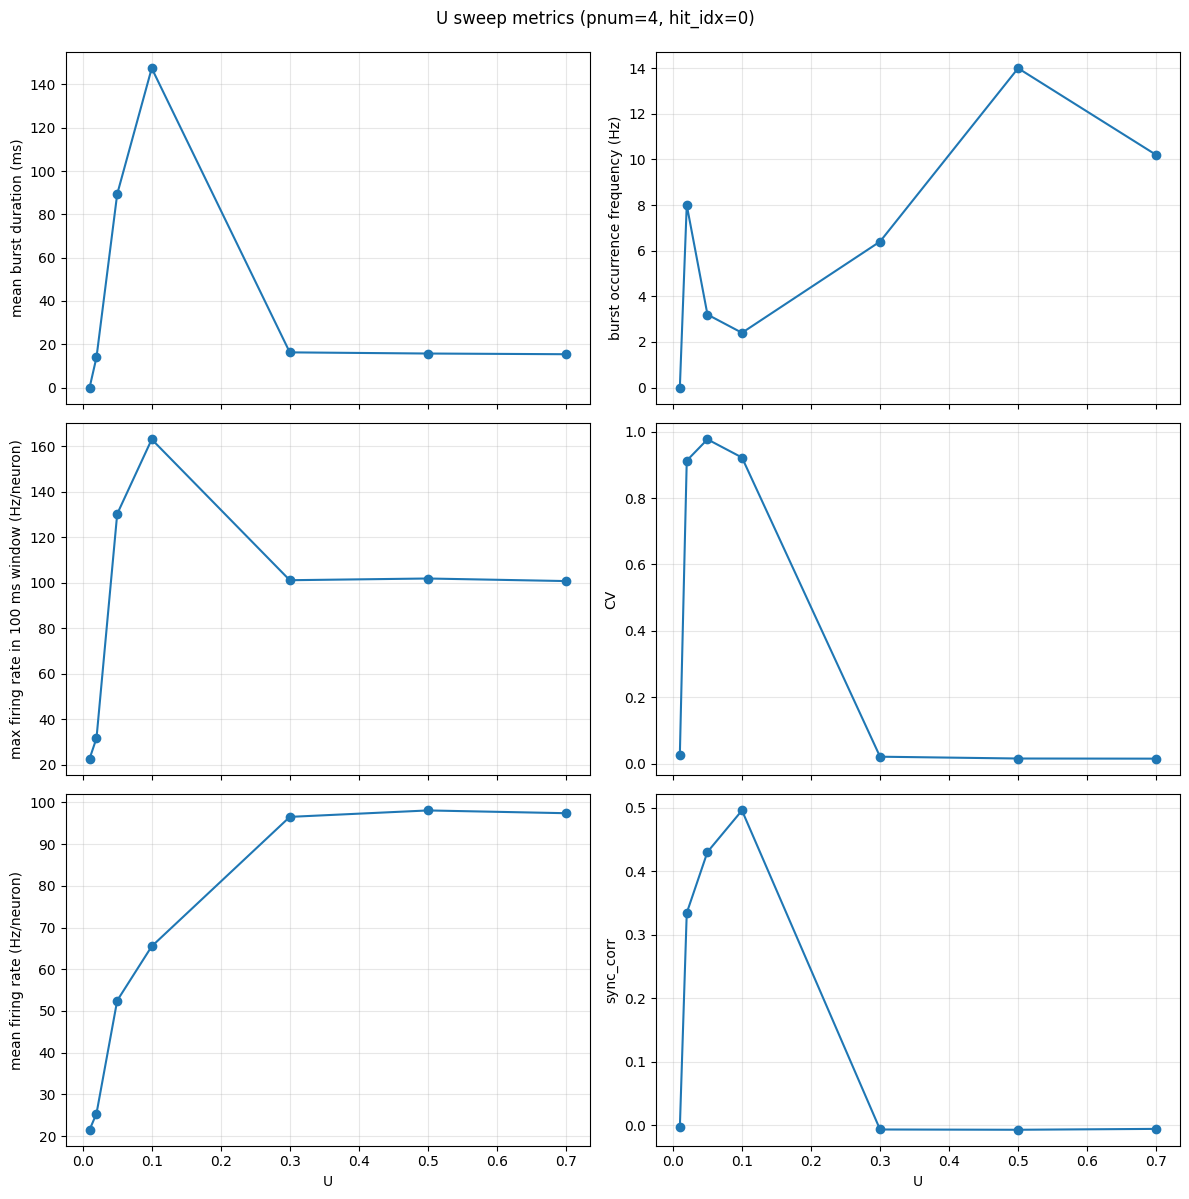

saved: figures/raster_sweep_byU2.SVG


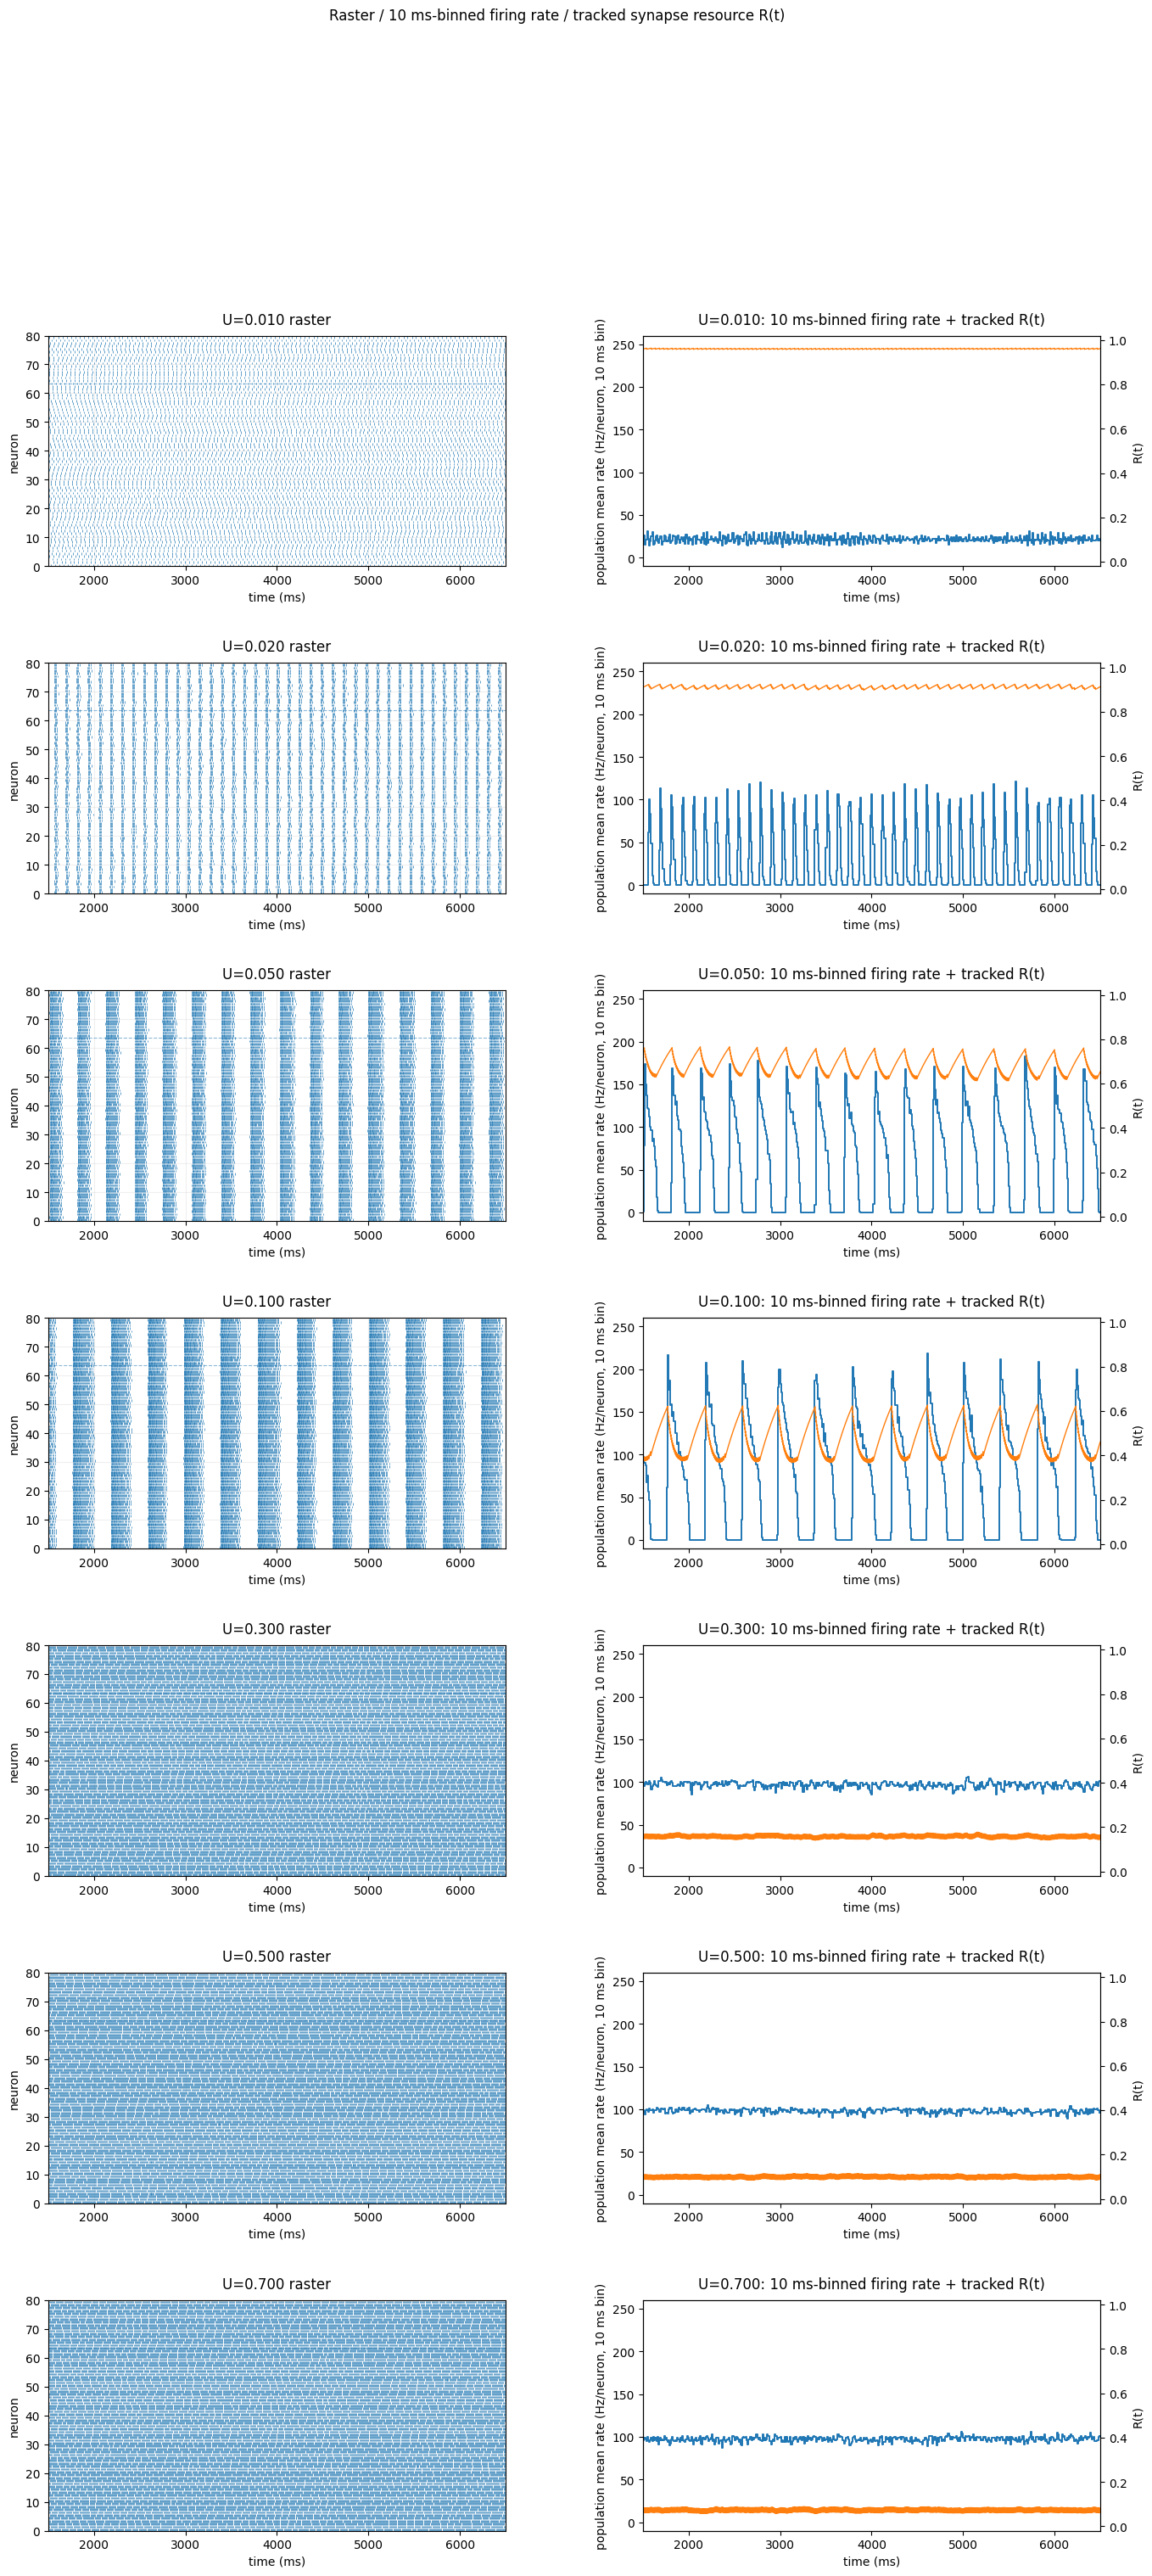

In [4]:
#close up   metrics by U

import traceback
import pickle

pnums = np.arange(0, 15, 1)
U_list = [0.01, 0.02, 0.05, 0.1,0.3,0.5,0.7]
pickle_path_b = "results/U_TRANS_params/2026_3_10_NET_SAN_STP_ULIST_2_10_SAN_SAN_example_CV0_18_13_all/"
name1 = "metrics_sweep_byU2"
name2 = "raster_sweep_byU2"
for pnum in pnums:
    if pnum != 4:
        continue
    try:
        pickle_path = pickle_path_b + f"U_TRANS_2026_3_10_core{pnum}.pickle"
        objs = load_pickle_objects(pickle_path)
        hits_df = extract_hits(objs)

        print("pickle_num:", pnum)
        print("hits:", len(hits_df))
        print("columns:", list(hits_df.columns))

        if len(hits_df) == 0:
            print(" -> no hits, skip")
            continue

        print(hits_df)

        for hit_idx in range(len(hits_df)):
            if hit_idx != 0:
                continue
            hit_row = hits_df.iloc[hit_idx]
            print("==== hit_idx =", hit_idx, "====")
            
#             vm_idx, metrics_df = plot_raster_for_U_list_cl(
#                 [5000, 5500],
#                 hits_df.iloc[hit_idx],
#                 U_list=U_list,
#                 T_ms=11500.0,
#                 dt_ms=0.1,
#                 record_every=10,
#                 thr=-20.0,

#                 eval_window_ms=(1500.0, 11500.0),
#                 cv_bin_ms=50.0,
#                 cv_mode="moving",
#                 cv_step_ms=5.0,

#                 sync_bin_ms=5.0,
#                 sync_binary=True,
#                 sync_on_population="E",

#                 n_vm_neurons=5,
#                 vm_seed=0,
#             )

#             plot_raster_for_U_list(
#                 hits_df.iloc[hit_idx],
#                 U_list=U_list,
#                 T_ms=11500.0,
#                 dt_ms=0.1,
#                 record_every=10,
#                 thr=-20.0,
#                 eval_window_ms=(1500.0, 11500.0),
                
#                 cv_bin_ms=50.0,
#                 cv_mode="moving",
#                 cv_step_ms=5.0,
#                 n_vm_neurons=2,
#                 vm_seed=0,   # 固定すると毎回同じ候補が選ばれる
#                )
            
            # 追加解析
            results_by_U, metrics_df, tracked_synapses = analyze_hit_for_U_list(
                hits_df.iloc[hit_idx],
                U_list=U_list,
                T_ms=11500.0,
                dt_ms=0.1,
                record_every=1,
                thr=-20.0,
                eval_window_ms=(1500.0, 6500.0),
                cv_w_ms=50.0,
                moving_ms=5.0,
                sync_bin_ms=5.0,
                sync_binary=True,
                sync_on_population="ALL",
                sync_time_window_ms=200.0,
                sync_time_step_ms=50.0,
                burst_threshold=80,      # 必要なら調整
                n_track_synapses=1,
                synapse_seed=0,          # Uが変わっても同じ3本になる
                synapse_population="ALL" # "E" にすると興奮性シナプスのみ
            )

            print(metrics_df)

            # U依存指標
            plot_metrics_vs_U(
                metrics_df,
                title=f"U sweep metrics (pnum={pnum}, hit_idx={hit_idx})",
                name = name1
            )

            # raster + time-resolved sync_corr + tracked R(t)
#             plot_raster_sync_and_tracked_r_by_U(
#                 results_by_U,
#                 tracked_synapses,
#                 raster_tlim_ms=(1500.0, 11500.0),
#                 r_tlim_ms=(1500.0, 11500.0),
#                 sync_tlim_ms=(1500.0, 11500.0),
                
                
#             )
            plot_raster_sync_and_tracked_r_by_U(
            results_by_U,
            tracked_synapses,
            raster_tlim_ms=(1500.0, 6500.0),
            combined_tlim_ms=(1500.0, 6500.0),  # 右図も同じ時間範囲で見る場合
            rate_bin_ms=10.0,
            rate_normalize_by_neuron=True,
                name = name2
        )

    except Exception:
        traceback.print_exc()

pickle_num: 4
hits: 2
columns: ['g_leak', 'g_kvhh', 'g_cav', 'g_kca', 'g_nap', 't_ca', 'g_ampar', 'g_gabar', 'tau_rec_e', 'tau_rec_i', 'tau_noise', 'sigma_noise', 'intrinsic_id', 'core', 'start_idx', 'end_idx', 'drop', 'max_cv', 'min_cv', 'U_start', 'U_end', 'cv_u0p05', 'rate_u0p05', 'cv0_u0p05', 'cv_hi_thr_u0p05', 'cv_lo_thr_u0p05', 'hi_hit_u0p05', 'lo_hit_u0p05', 'valid_u0p05', 'cv_u0p1', 'rate_u0p1', 'cv0_u0p1', 'cv_hi_thr_u0p1', 'cv_lo_thr_u0p1', 'hi_hit_u0p1', 'lo_hit_u0p1', 'valid_u0p1', 'cv_u0p3', 'rate_u0p3', 'cv0_u0p3', 'cv_hi_thr_u0p3', 'cv_lo_thr_u0p3', 'hi_hit_u0p3', 'lo_hit_u0p3', 'valid_u0p3', 'cv_u0p5', 'rate_u0p5', 'cv0_u0p5', 'cv_hi_thr_u0p5', 'cv_lo_thr_u0p5', 'hi_hit_u0p5', 'lo_hit_u0p5', 'valid_u0p5', 'cv_u0p7', 'rate_u0p7', 'cv0_u0p7', 'cv_hi_thr_u0p7', 'cv_lo_thr_u0p7', 'hi_hit_u0p7', 'lo_hit_u0p7', 'valid_u0p7', 'cv_u0p9', 'rate_u0p9', 'cv0_u0p9', 'cv_hi_thr_u0p9', 'cv_lo_thr_u0p9', 'hi_hit_u0p9', 'lo_hit_u0p9', 'valid_u0p9']
==== hit_idx = 0 ====
g_leak         

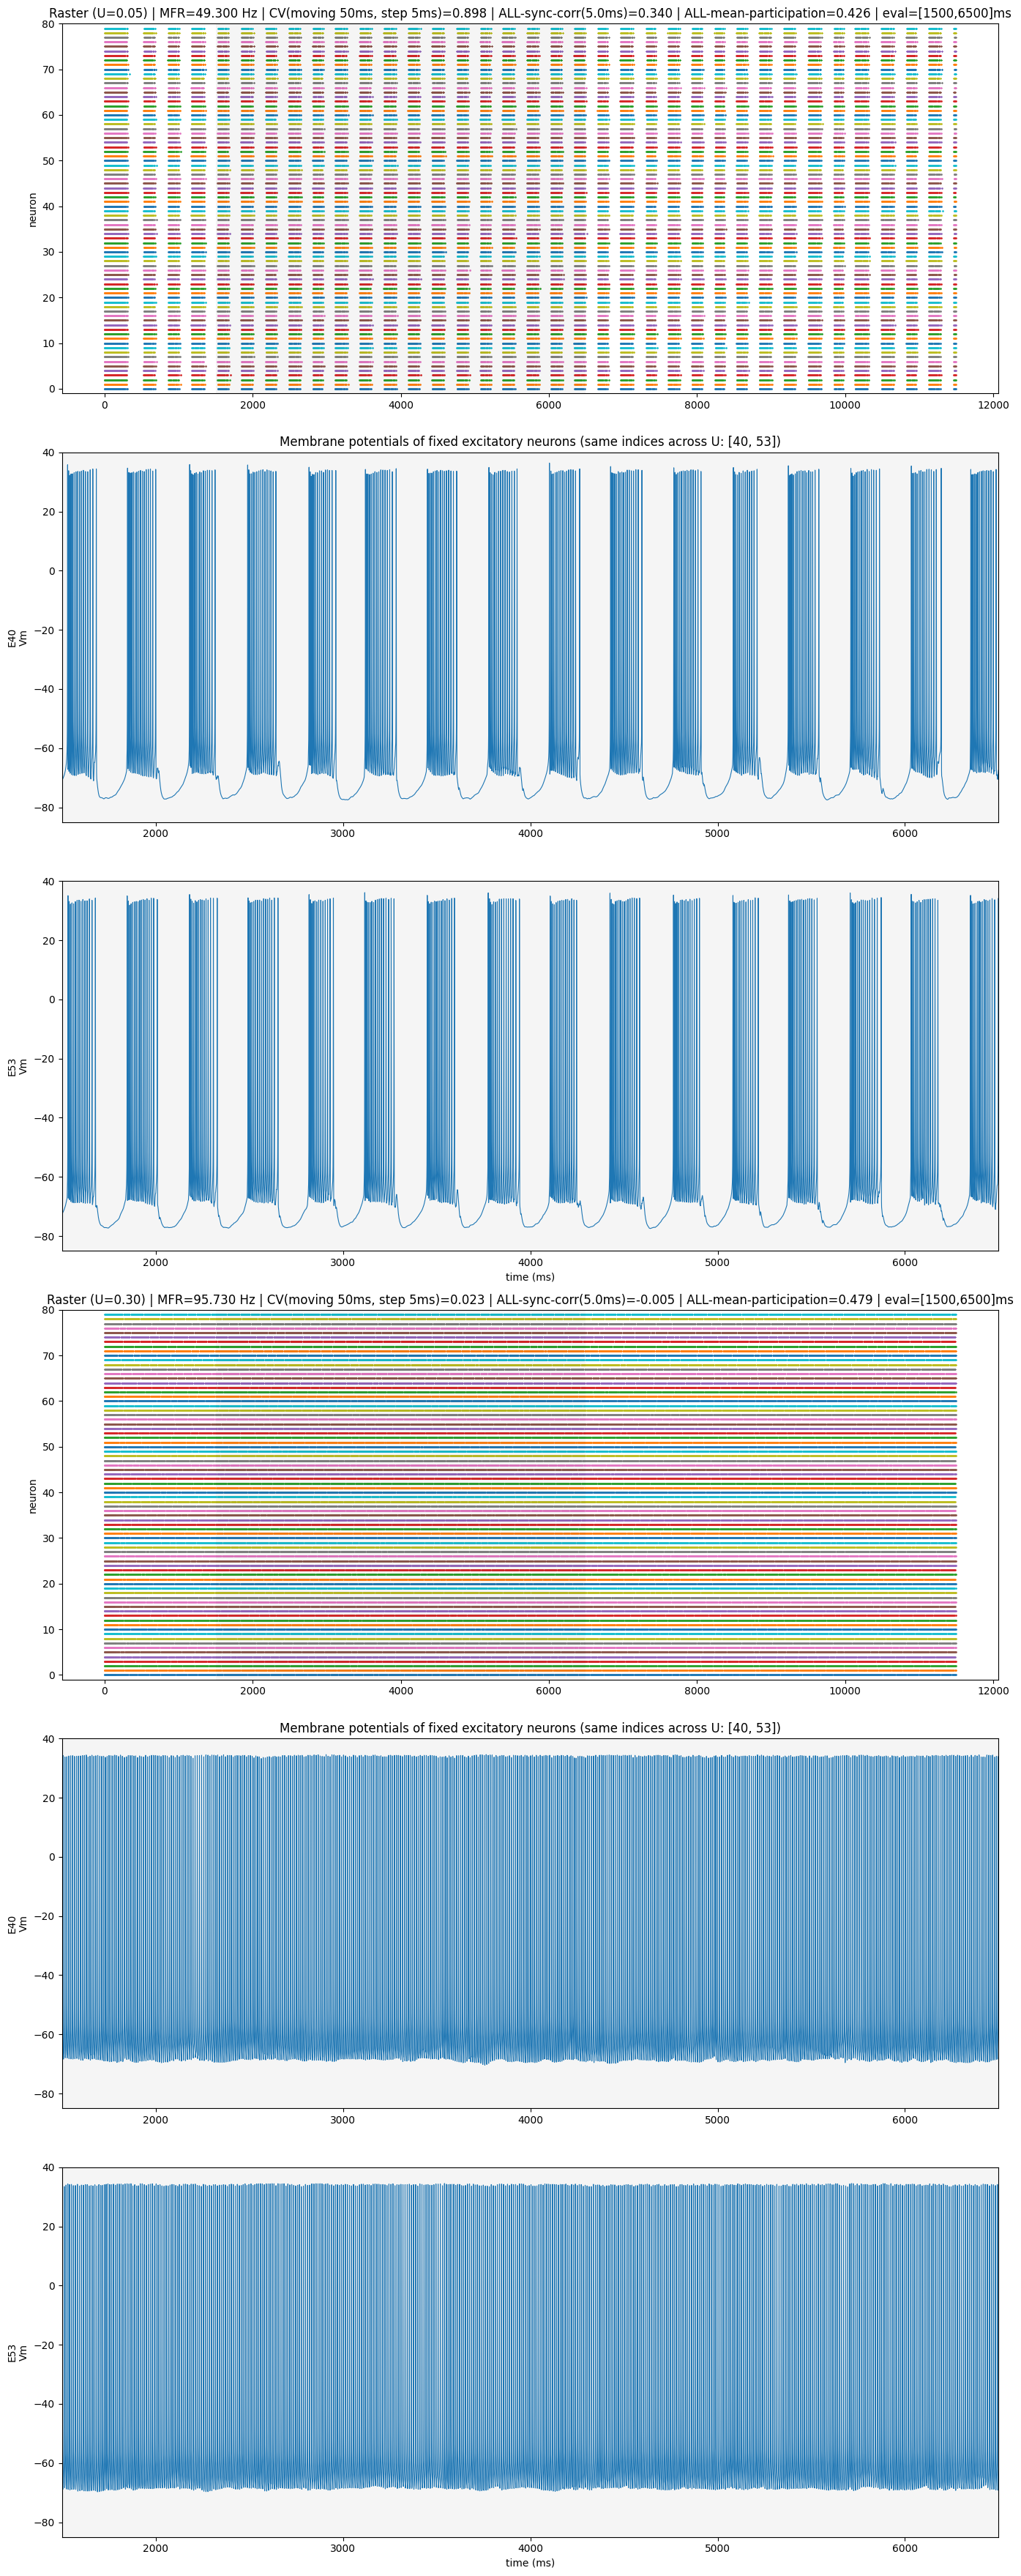

      U  MFR_Hz    CV_pop  sync_corr  mean_participation sync_population  \
0  0.05   49.30  0.898129   0.339559            0.425734             ALL   
1  0.30   95.73  0.022733  -0.005198            0.478650             ALL   

   sync_bin_ms  n_valid_sync_neurons  
0          5.0                    80  
1          5.0                    80  
Tracked synapses:
  [0] I73->7
saved: figures/repre_metrics_by_UE_only.SVG


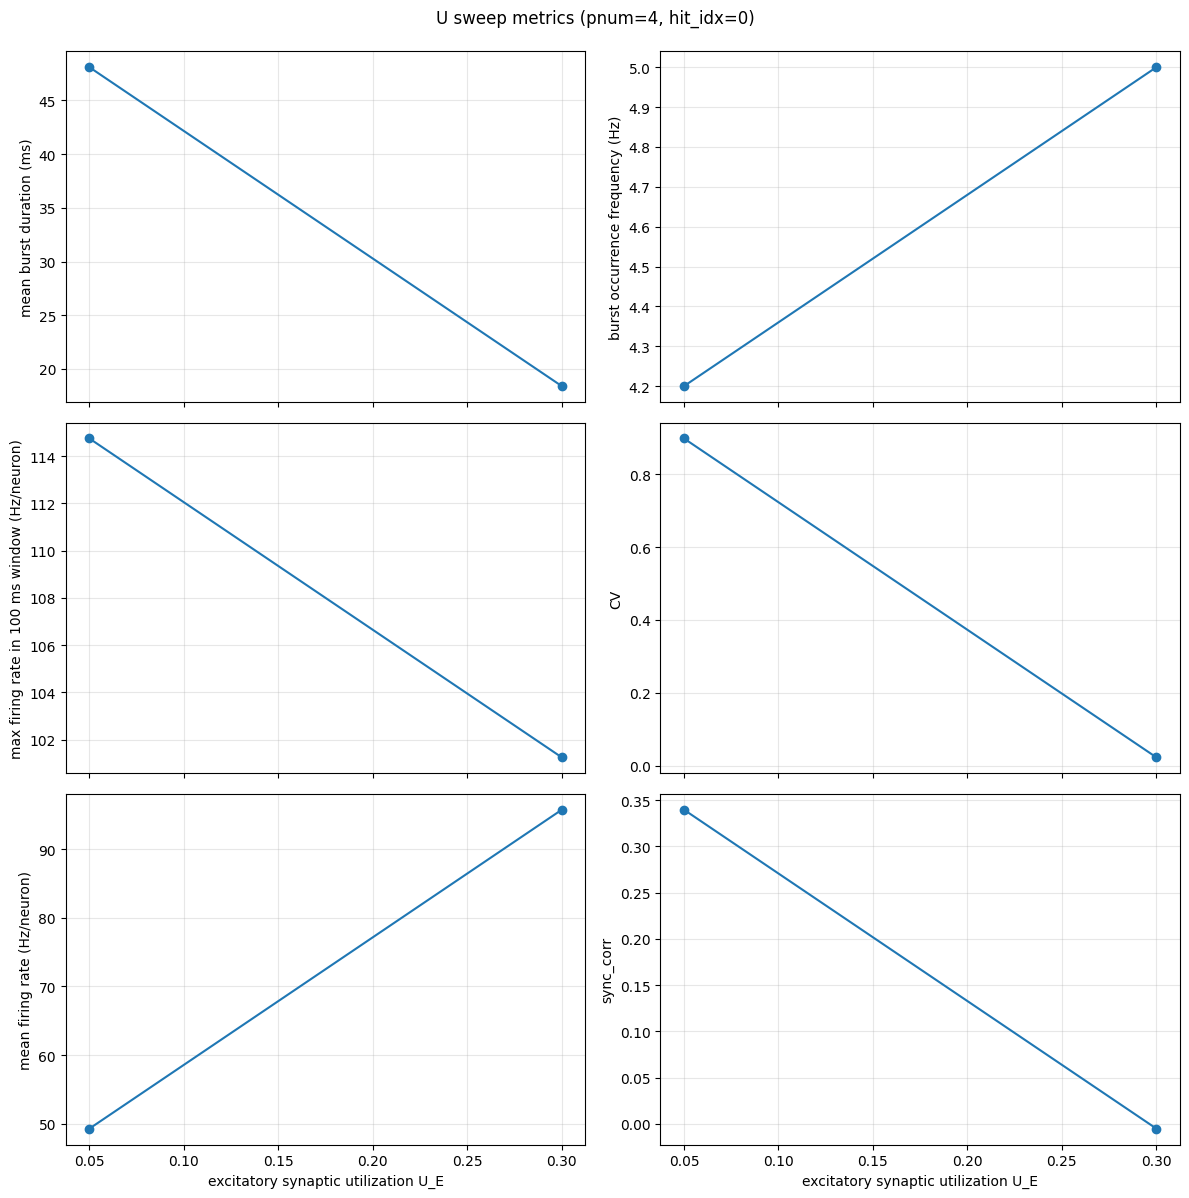

saved: figures/repre_raster_by_UE_only.SVG


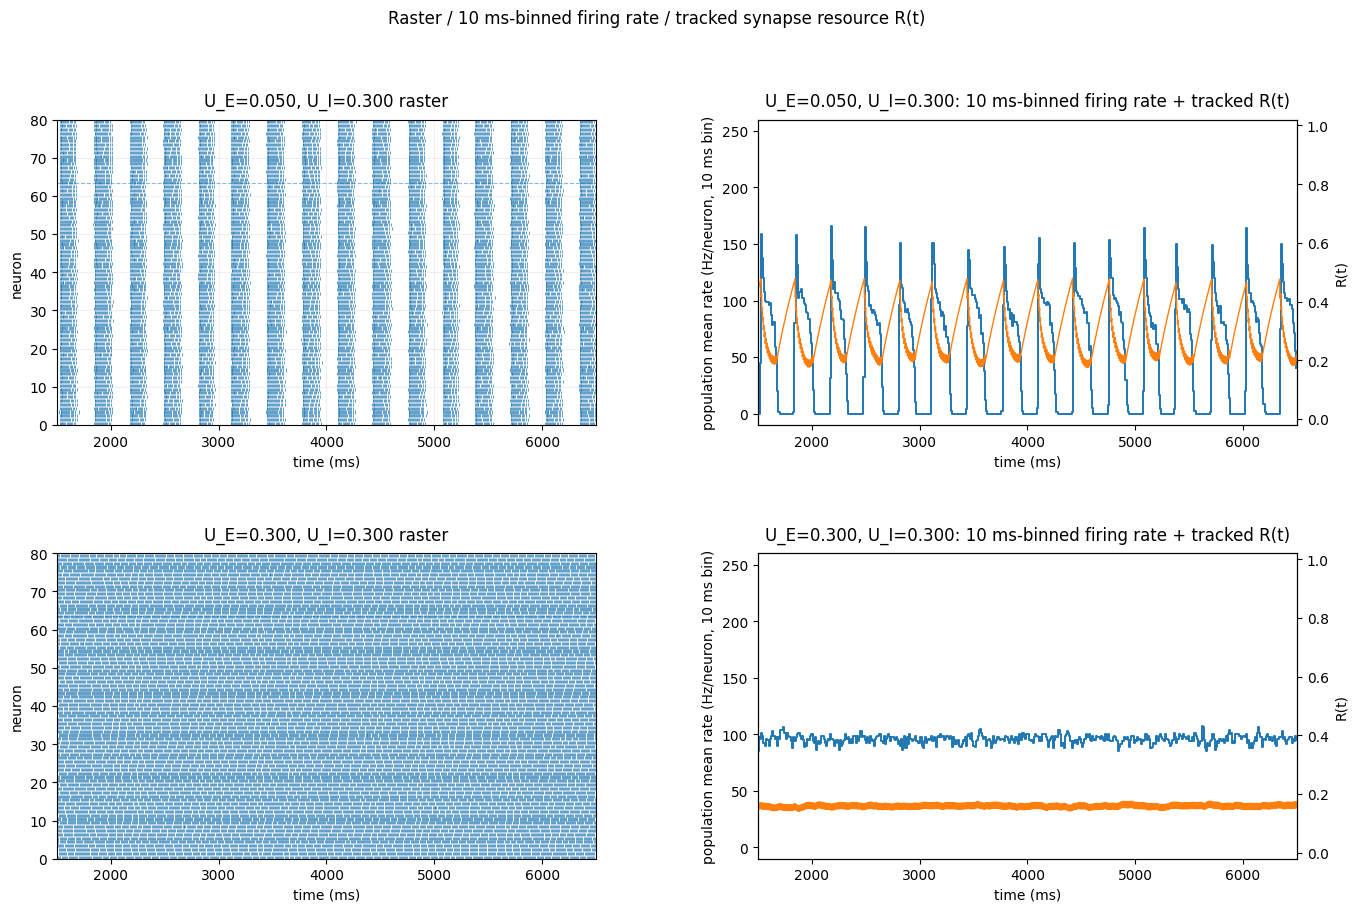

In [7]:
#close up   repre by U
import traceback
import pickle

U_list = [0.05, 0.3]
pnums = np.arange(0, 15, 1)

pickle_path_b = "results/U_TRANS_params/2026_3_10_NET_SAN_STP_ULIST_2_10_SAN_SAN_example_CV0_18_13_all/"
name1 = "repre_metrics_by_UE_only"
name2 = "repre_raster_by_UE_only"

U_I_fixed = 0.3
for pnum in pnums:
    if pnum != 4:
        continue
    try:
        pickle_path = pickle_path_b + f"U_TRANS_2026_3_10_core{pnum}.pickle"
        objs = load_pickle_objects(pickle_path)
        hits_df = extract_hits(objs)

        print("pickle_num:", pnum)
        print("hits:", len(hits_df))
        print("columns:", list(hits_df.columns))

        if len(hits_df) == 0:
            print(" -> no hits, skip")
            continue

#         print(hits_df)

        for hit_idx in range(len(hits_df)):
            if hit_idx != 0:
                continue
            
            hit_row = hits_df.iloc[hit_idx]
            print("==== hit_idx =", hit_idx, "====")
            print(hit_row)
            
#             vm_idx, metrics_df = plot_raster_for_U_list_cl(
#                 [5000, 5500],
#                 hits_df.iloc[hit_idx],
#                 U_list=U_list,
#                 T_ms=11500.0,
#                 dt_ms=0.1,
#                 record_every=10,
#                 thr=-20.0,

#                 eval_window_ms=(1500.0, 11500.0),
#                 cv_bin_ms=50.0,
#                 cv_mode="moving",
#                 cv_step_ms=5.0,

#                 sync_bin_ms=5.0,
#                 sync_binary=True,
#                 sync_on_population="E",

#                 n_vm_neurons=5,
#                 vm_seed=0,
#             )
              #mp
#             plot_raster_for_U_list(
#                 hits_df.iloc[hit_idx],
#                 U_list=U_list,
#                 T_ms=11500.0,
#                 dt_ms=0.1,
#                 record_every=1,
#                 thr=-20.0,
#                 eval_window_ms=(1500.0, 6500.0),
                
#                 cv_bin_ms=50.0,
#                 cv_mode="moving",
#                 cv_step_ms=5.0,
#                 n_vm_neurons=2,
#                 vm_seed=0,   # 固定すると毎回同じ候補が選ばれる
#                )
            
            # 追加解析
            results_by_U, metrics_df, tracked_synapses = analyze_hit_for_U_list(
                hits_df.iloc[hit_idx],
                U_list=U_list,
                T_ms=11500.0,
                dt_ms=0.1,
                record_every=1,
                thr=-20.0,
                eval_window_ms=(1500.0, 6500.0),
                cv_w_ms=50.0,
                moving_ms=5.0,
                sync_bin_ms=5.0,
                sync_binary=True,
                sync_on_population="ALL",
                sync_time_window_ms=200.0,
                sync_time_step_ms=50.0,
                burst_threshold=80,      # 必要なら調整
                n_track_synapses=1,
                synapse_seed=0,          # Uが変わっても同じ3本になる
                synapse_population="ALL" # "E" にすると興奮性シナプスのみ
            )

#             print(metrics_df)

            # U依存指標
            plot_metrics_vs_U(
                metrics_df,
                title=f"U sweep metrics (pnum={pnum}, hit_idx={hit_idx})",
                name = name1
            )


            plot_raster_sync_and_tracked_r_by_U(
            results_by_U,
            tracked_synapses,
            raster_tlim_ms=(1500.0, 6500.0),
            combined_tlim_ms=(1500.0, 6500.0),  # 右図も同じ時間範囲で見る場合
            rate_bin_ms=10.0,
            rate_normalize_by_neuron=True,
                name = name2
        )

    except Exception:
        traceback.print_exc()

In [11]:
print(hit_row["g_leak"])
hit_row["g_ampar"]

0.07941250416305401


0.875368140581566

In [5]:
# ============================================================
# sweep g_ampar
# 修正版:
#   mean_burst_frequency = burst occurrence frequency [Hz]
#   max_frequency        = max mean firing rate in 100 ms window [Hz/neuron]
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pathlib import Path
from typing import Any, Dict, List, Tuple, Optional

# networks.py 由来
# from networks import SANVesicleNetwork, UProfile

# すでに定義済みであることを想定:
#   split_paramskinos
#   SANVesicleNetwork
#   choose_tracked_synapses
#   analyze_one_U
#   detect_bursts
#   pop_total_rate_and_max
#   population_rate_series_binned
#   format_synapse_label

if "fig_dir" not in globals():
    fig_dir = "figures"

Path(fig_dir).mkdir(parents=True, exist_ok=True)


# ============================================================
# burst / max frequency 再計算用 helper
# ============================================================

def filter_bursts_by_window(
    bursts,
    t_start_ms: float,
    t_end_ms: float,
    mode: str = "center",
):
    """
    評価区間内の burst のみを抽出する。

    mode="center":
        burst 中心時刻が [t_start_ms, t_end_ms) に入るものを採用。

    mode="overlap":
        burst が評価区間と少しでも重なるものを採用。
    """
    if bursts is None or len(bursts) == 0:
        return []

    selected = []

    for b in bursts:
        s_ms, e_ms = float(b[0]), float(b[1])

        if mode == "center":
            c_ms = 0.5 * (s_ms + e_ms)
            if (c_ms >= t_start_ms) and (c_ms < t_end_ms):
                selected.append([s_ms, e_ms])

        elif mode == "overlap":
            if (e_ms > t_start_ms) and (s_ms < t_end_ms):
                selected.append([s_ms, e_ms])

        else:
            raise ValueError("mode must be 'center' or 'overlap'.")

    return selected


def burst_rate_frequency(
    bursts,
    t_start_ms: float,
    t_end_ms: float,
):
    """
    評価区間あたりの burst 発生頻度 [Hz]。

    frequency = number of bursts / evaluation duration [s]

    これを oscillation frequency 的な指標として使う。
    """
    dur_s = (float(t_end_ms) - float(t_start_ms)) * 1e-3

    if dur_s <= 0.0:
        return 0.0

    if bursts is None:
        return 0.0

    return float(len(bursts) / dur_s)


def mean_burst_duration_from_bursts(bursts):
    """
    burst の平均持続時間 [ms] を返す。
    """
    if bursts is None or len(bursts) == 0:
        return 0.0

    durs = []

    for b in bursts:
        s_ms, e_ms = float(b[0]), float(b[1])
        if e_ms > s_ms:
            durs.append(e_ms - s_ms)

    if len(durs) == 0:
        return 0.0

    return float(np.mean(durs))


def max_mean_rate_100ms_from_spts(
    spts,
    *,
    dt_ms: float,
    N_neurons: int,
    t_start_ms: float,
    t_end_ms: float,
    window_ms: float = 100.0,
    step_ms: float = 1.0,
):
    """
    100 ms window における最大1ニューロン平均発火率 [Hz/neuron] を返す。

    pop_total_rate_and_max() は population total rate [spikes/s] を返すので、
    ここで N_neurons で割る。
    """
    _, _, max_population_rate, _, _ = pop_total_rate_and_max(
        spts,
        dt_ms=dt_ms,
        Nn=N_neurons,
        window_ms=window_ms,
        step_ms=step_ms,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
    )

    if N_neurons <= 0:
        return np.nan

    return float(max_population_rate / float(N_neurons))


def recompute_burst_and_max_metrics_for_out(
    out: Dict[str, Any],
    *,
    spts_dt_ms: float,
    N_neurons: int,
    t_start_ms: float,
    t_end_ms: float,
    burst_window_ms: float = 10.0,
    burst_moving_ms: float = 5.0,
    burst_threshold: int = 80,
    burst_max_duration_ms: float | None = 250.0,
    burst_filter_mode: str = "center",
):
    """
    analyze_one_U() の出力 out から、
    mean_burst_frequency と max_frequency を指定定義で再計算する。

    これにより analyze_one_U() が旧定義でも、
    g_ampar sweep 側の metrics は必ず修正版になる。
    """
    spts = out["spts"]

    bursts_all = detect_bursts(
        spts,
        dt_ms=spts_dt_ms,
        window_ms=burst_window_ms,
        moving_ms=burst_moving_ms,
        threshold=burst_threshold,
        max_duration_ms=burst_max_duration_ms,
    )

    bursts_eval = filter_bursts_by_window(
        bursts_all,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        mode=burst_filter_mode,
    )

    mean_burst_duration = mean_burst_duration_from_bursts(bursts_eval)

    mean_burst_frequency = burst_rate_frequency(
        bursts_eval,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
    )

    max_frequency = max_mean_rate_100ms_from_spts(
        spts,
        dt_ms=spts_dt_ms,
        N_neurons=N_neurons,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        window_ms=100.0,
        step_ms=1.0,
    )

    out["bursts_all"] = bursts_all
    out["bursts"] = bursts_eval
    out["n_bursts"] = int(len(bursts_eval))

    # 評価区間内 burst の平均持続時間 [ms]
    out["mean_burst_duration"] = float(mean_burst_duration)

    # 重要:
    # burst 中の発火率ではなく、評価区間内 burst 発生頻度 [Hz]
    out["mean_burst_frequency"] = float(mean_burst_frequency)

    # 重要:
    # population total rate ではなく、N で割った 1ニューロン平均最大発火率 [Hz/neuron]
    out["max_frequency"] = float(max_frequency)

    return out


# ============================================================
# hit_row から network を再構築
# ============================================================

def build_san_network_from_hit(
    hit_row,
    default_NE: int = 64,
    default_NI: int = 16,
    default_seed: int = 0,
    default_p_ee: float = 0.2,
    default_p_ei: float = 0.4,
    default_p_ie: float = 0.5,
    default_p_ii: float = 0.5,
    default_allow_self: bool = False,
):
    """
    hit_row から SANVesicleNetwork を再構築する。

    注意:
    hit_row に NE, NI, seed, p_ee, p_ei, p_ie, p_ii, allow_self が
    保存されていない場合は default_* が使われる。
    search 時と同じ設定にそろえること。
    """
    row_dict = dict(hit_row)
    intrinsic, syn = split_params(row_dict)

    NE = int(syn.get("NE", default_NE))
    NI = int(syn.get("NI", default_NI))
    seed = int(syn.get("seed", default_seed))

    p_ee = float(syn.get("p_ee", default_p_ee))
    p_ei = float(syn.get("p_ei", default_p_ei))
    p_ie = float(syn.get("p_ie", default_p_ie))
    p_ii = float(syn.get("p_ii", default_p_ii))

    allow_self = bool(syn.get("allow_self", default_allow_self))

    net = SANVesicleNetwork(
        NE=NE,
        NI=NI,
        seed=seed,
        p_ee=p_ee,
        p_ei=p_ei,
        p_ie=p_ie,
        p_ii=p_ii,
        allow_self=allow_self,
    )

    net.set_intrinsic_params(intrinsic)
    net.set_network_params(syn)

    return net, intrinsic, syn


# ============================================================
# g_ampar sweep 値を作る
# ============================================================

def make_g_ampar_list_from_hit(
    hit_row,
    scale_min: float = 1.0,
    scale_max: float = 2.0,
    n_steps: int = 5,
) -> Tuple[float, np.ndarray, np.ndarray]:
    """
    hit_row 内の g_ampar を基準に、
    scale_min 〜 scale_max 倍の値を n_steps 段階で作る。

    Returns
    -------
    base_g_ampar : float
    scales : np.ndarray
    g_values : np.ndarray
    """
    row_dict = dict(hit_row)
    _, syn = split_params(row_dict)

    if "g_ampar" in syn:
        base_g_ampar = float(syn["g_ampar"])
    elif "g_ampar" in row_dict and pd.notna(row_dict["g_ampar"]):
        base_g_ampar = float(row_dict["g_ampar"])
    else:
        raise KeyError("hit_row から g_ampar を取得できませんでした。")

    if base_g_ampar <= 0:
        raise ValueError(f"base_g_ampar must be > 0. got {base_g_ampar}")

    if n_steps < 2:
        raise ValueError("n_steps must be >= 2")

    scales = np.linspace(float(scale_min), float(scale_max), int(n_steps))
    g_values = base_g_ampar * scales

    return base_g_ampar, scales, g_values


# ============================================================
# 1つの g_ampar 条件を解析
# ============================================================

def analyze_one_g_ampar(
    net,
    g_ampar: float,
    U_fixed: float,
    tracked_synapses: List[Dict[str, Any]],
    base_g_ampar: float,
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    thr: float = -20.0,
    eval_window_ms: Tuple[float, float] = (1500.0, 11500.0),
    cv_w_ms: float = 50.0,
    moving_ms: float = 5.0,
    sync_bin_ms: float = 5.0,
    sync_binary: bool = True,
    sync_on_population: str = "ALL",
    sync_time_window_ms: float = 200.0,
    sync_time_step_ms: float = 50.0,
    burst_threshold: int = 80,
    burst_filter_mode: str = "center",
):
    """
    U を固定し、g_ampar を指定値にして 1 条件解析する。

    この関数内で metrics を再計算し、
    mean_burst_frequency と max_frequency を修正版定義にする。
    """
    net.set_network_params({"g_ampar": float(g_ampar)})

    res = analyze_one_U(
        net=net,
        U=float(U_fixed),
        tracked_synapses=tracked_synapses,
        T_ms=T_ms,
        dt_ms=dt_ms,
        record_every=record_every,
        thr=thr,
        eval_window_ms=eval_window_ms,
        cv_w_ms=cv_w_ms,
        moving_ms=moving_ms,
        sync_bin_ms=sync_bin_ms,
        sync_binary=sync_binary,
        sync_on_population=sync_on_population,
        sync_time_window_ms=sync_time_window_ms,
        sync_time_step_ms=sync_time_step_ms,
        burst_threshold=burst_threshold,
    )

    res["g_ampar"] = float(g_ampar)
    res["base_g_ampar"] = float(base_g_ampar)
    res["g_ampar_scale"] = (
        float(g_ampar / base_g_ampar)
        if base_g_ampar > 0
        else np.nan
    )
    res["U_fixed"] = float(U_fixed)

    # ------------------------------------------------------------
    # ここで必ず指定定義に再計算する
    # ------------------------------------------------------------
    t_start_ms = max(0.0, float(eval_window_ms[0]))
    t_end_ms = min(float(T_ms), float(eval_window_ms[1]))

    if t_end_ms <= t_start_ms:
        raise ValueError("eval_window_ms must satisfy end > start.")

    spts_dt_ms = float(dt_ms) * int(record_every)

    N_neurons = int(res["N"]) if "N" in res else int(res["spts"].shape[0])

    res = recompute_burst_and_max_metrics_for_out(
        res,
        spts_dt_ms=spts_dt_ms,
        N_neurons=N_neurons,
        t_start_ms=t_start_ms,
        t_end_ms=t_end_ms,
        burst_window_ms=10.0,
        burst_moving_ms=5.0,
        burst_threshold=burst_threshold,
        burst_max_duration_ms=250.0,
        burst_filter_mode=burst_filter_mode,
    )

    return res


# ============================================================
# hit_row に対する g_ampar sweep 全体
# ============================================================

def analyze_hit_for_g_ampar_sweep(
    hit_row,
    U_fixed: float = 0.05,

    # g_ampar sweep
    g_ampar_scale_min: float = 1.0,
    g_ampar_scale_max: float = 2.0,
    n_g_ampar: int = 5,
    g_ampar_list: Optional[List[float]] = None,

    # simulation / analysis
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    thr: float = -20.0,
    eval_window_ms: Tuple[float, float] = (1500.0, 11500.0),
    cv_w_ms: float = 50.0,
    moving_ms: float = 5.0,
    sync_bin_ms: float = 5.0,
    sync_binary: bool = True,
    sync_on_population: str = "ALL",
    sync_time_window_ms: float = 200.0,
    sync_time_step_ms: float = 50.0,
    burst_threshold: int = 80,
    burst_filter_mode: str = "center",

    # tracked synapse
    n_track_synapses: int = 1,
    synapse_seed: int = 0,
    synapse_population: str = "ALL",

    # rebuild defaults
    default_NE: int = 64,
    default_NI: int = 16,
    default_seed: int = 0,
    default_p_ee: float = 0.2,
    default_p_ei: float = 0.4,
    default_p_ie: float = 0.5,
    default_p_ii: float = 0.5,
    default_allow_self: bool = False,
):
    """
    hit_row を再構築し、U を固定したまま g_ampar を掃引して解析する。

    metrics_df の定義:
        mean_burst_frequency:
            評価区間内の burst 発生頻度 [Hz]

        max_frequency:
            100 ms window における最大1ニューロン平均発火率 [Hz/neuron]
    """
    net, intrinsic, syn = build_san_network_from_hit(
        hit_row,
        default_NE=default_NE,
        default_NI=default_NI,
        default_seed=default_seed,
        default_p_ee=default_p_ee,
        default_p_ei=default_p_ei,
        default_p_ie=default_p_ie,
        default_p_ii=default_p_ii,
        default_allow_self=default_allow_self,
    )

    row_dict = dict(hit_row)

    if "g_ampar" in syn:
        base_g_ampar = float(syn["g_ampar"])
    elif "g_ampar" in row_dict and pd.notna(row_dict["g_ampar"]):
        base_g_ampar = float(row_dict["g_ampar"])
    else:
        raise KeyError("hit_row から g_ampar を取得できませんでした。")

    if base_g_ampar <= 0:
        raise ValueError(f"base_g_ampar must be > 0. got {base_g_ampar}")

    if g_ampar_list is None:
        g_scales = np.linspace(
            float(g_ampar_scale_min),
            float(g_ampar_scale_max),
            int(n_g_ampar),
        )
        g_values = base_g_ampar * g_scales
    else:
        g_values = np.asarray(g_ampar_list, dtype=float)

        if g_values.ndim != 1 or g_values.size == 0:
            raise ValueError("g_ampar_list must be a non-empty 1D array/list.")

        g_scales = g_values / base_g_ampar

    tracked_synapses = choose_tracked_synapses(
        net,
        n_track=int(n_track_synapses),
        seed=int(synapse_seed),
        synapse_population=synapse_population,
    )

    print(f"base g_ampar = {base_g_ampar:.6f}")
    print("g_ampar scales =", g_scales)
    print("g_ampar values =", g_values)

    results_by_g = []
    metrics_rows = []

    for g_val, g_scale in zip(g_values, g_scales):
        print(
            f"Running U={U_fixed:.4f}, "
            f"g_ampar={float(g_val):.6f} "
            f"(x{float(g_scale):.3f}) ..."
        )

        res = analyze_one_g_ampar(
            net=net,
            g_ampar=float(g_val),
            U_fixed=float(U_fixed),
            tracked_synapses=tracked_synapses,
            base_g_ampar=float(base_g_ampar),
            T_ms=T_ms,
            dt_ms=dt_ms,
            record_every=record_every,
            thr=thr,
            eval_window_ms=eval_window_ms,
            cv_w_ms=cv_w_ms,
            moving_ms=moving_ms,
            sync_bin_ms=sync_bin_ms,
            sync_binary=sync_binary,
            sync_on_population=sync_on_population,
            sync_time_window_ms=sync_time_window_ms,
            sync_time_step_ms=sync_time_step_ms,
            burst_threshold=burst_threshold,
            burst_filter_mode=burst_filter_mode,
        )

        results_by_g.append(res)

        metrics_rows.append(
            {
                "U_fixed": float(U_fixed),
                "base_g_ampar": float(base_g_ampar),
                "g_ampar": float(g_val),
                "g_ampar_scale": float(g_scale),

                # 評価区間内 burst 平均持続時間 [ms]
                "mean_burst_duration": res["mean_burst_duration"],

                # 評価区間内 burst 発生頻度 [Hz]
                # = oscillation frequency 的な指標
                "mean_burst_frequency": res["mean_burst_frequency"],

                # 100 ms window における最大1ニューロン平均発火率 [Hz/neuron]
                "max_frequency": res["max_frequency"],

                "CV": res["CV"],
                "mean_firing_rate": res["mean_firing_rate"],
                "sync_corr": res["sync_corr"],
                "n_bursts": res["n_bursts"],
                "sync_n_valid": res["sync_n_valid"],
                "sync_population": res["sync_population"],
            }
        )

    metrics_df = (
        pd.DataFrame(metrics_rows)
        .sort_values("g_ampar")
        .reset_index(drop=True)
    )

    return results_by_g, metrics_df, tracked_synapses


# ============================================================
# g_ampar に対する指標プロット
# ============================================================

def plot_metrics_vs_g_ampar(
    df: pd.DataFrame,
    title: str | None = None,
    x_col: str = "g_ampar",
    name=None,
):
    """
    g_ampar または g_ampar_scale に対して metrics をプロットする。

    x_col:
        "g_ampar" or "g_ampar_scale"
    """
    df = df.sort_values(x_col).reset_index(drop=True)

    fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True)
    axes = axes.ravel()

    metrics = [
        ("mean_burst_duration", "mean burst duration (ms)"),
        ("mean_burst_frequency", "burst occurrence frequency (Hz)"),
        ("max_frequency", "max firing rate in 100 ms window (Hz/neuron)"),
        ("CV", "CV"),
        ("mean_firing_rate", "mean firing rate (Hz/neuron)"),
        ("sync_corr", "sync_corr"),
    ]

    for ax, (col, ylabel) in zip(axes, metrics):
        ax.plot(df[x_col], df[col], marker="o")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)

    axes[-2].set_xlabel(x_col)
    axes[-1].set_xlabel(x_col)

    if title is not None:
        fig.suptitle(title, y=0.995)

    fig.tight_layout()

    if name is not None:
        out_path = Path(fig_dir) / f"{name}.SVG"
        fig.savefig(out_path)
        print(f"saved: {out_path}")

    plt.show()


# ============================================================
# g_ampar ごとの raster + rate + tracked R(t)
# ============================================================

def plot_raster_rate_and_tracked_r_by_g_ampar(
    results_by_g: List[Dict[str, Any]],
    tracked_synapses: List[Dict[str, Any]],
    raster_tlim_ms: Tuple[float, float] = (1500.0, 11500.0),
    combined_tlim_ms: Tuple[float, float] | None = None,
    rate_bin_ms: float = 50.0,
    rate_normalize_by_neuron: bool = True,
    only_first_tracked_synapse: bool = True,
    name=None,
):
    """
    各 g_ampar ごとに、

    左:
        raster

    右:
        bin 発火率 + tracked synapse R(t)

    を描画する。
    """
    if len(results_by_g) == 0:
        raise ValueError("results_by_g is empty.")

    results_sorted = sorted(results_by_g, key=lambda x: x["g_ampar"])
    nG = len(results_sorted)

    if combined_tlim_ms is None:
        t_min = (
            float(np.min(results_sorted[0]["r_times"]))
            if len(results_sorted[0]["r_times"])
            else 0.0
        )
        t_max = (
            float(np.max(results_sorted[0]["r_times"]))
            if len(results_sorted[0]["r_times"])
            else 0.0
        )
        combined_tlim_ms = (t_min, t_max)

    synapse_labels = [format_synapse_label(s) for s in tracked_synapses]

    fig = plt.figure(figsize=(16, 4.8 * nG))

    outer = gridspec.GridSpec(
        nG,
        2,
        width_ratios=[1.0, 1.0],
        wspace=0.30,
        hspace=0.42,
    )

    for i, res in enumerate(results_sorted):
        g_ampar = float(res["g_ampar"])
        g_scale = float(res["g_ampar_scale"])
        U_fixed = float(res["U_fixed"])

        spike_times = res["spike_times"]

        N = int(res["N"])
        NE = int(res["NE"])

        t_ms_r = np.asarray(res["r_times"], dtype=float)
        r_trace = np.asarray(res["r_trace"], dtype=float)

        CV = float(res["CV"]) if np.isfinite(res["CV"]) else np.nan
        mean_rate = (
            float(res["mean_firing_rate"])
            if np.isfinite(res["mean_firing_rate"])
            else np.nan
        )
        sync_corr = (
            float(res["sync_corr"])
            if np.isfinite(res["sync_corr"])
            else np.nan
        )
        burst_freq = (
            float(res["mean_burst_frequency"])
            if np.isfinite(res["mean_burst_frequency"])
            else np.nan
        )
        max_freq = (
            float(res["max_frequency"])
            if np.isfinite(res["max_frequency"])
            else np.nan
        )

        # --------------------------------------------------------
        # 左: raster
        # --------------------------------------------------------
        ax_raster = fig.add_subplot(outer[i, 0])

        t0_ras, t1_ras = raster_tlim_ms

        for n_idx in range(len(spike_times)):
            st = np.asarray(spike_times[n_idx], dtype=float)

            if st.size == 0:
                continue

            st = st[(st >= t0_ras) & (st <= t1_ras)]

            if st.size > 0:
                ax_raster.vlines(
                    st,
                    n_idx,
                    n_idx + 0.8,
                    lw=0.5,
                    rasterized=True,
                )

        ax_raster.axhline(NE - 0.5, ls="--", lw=0.8, alpha=0.5)

        ax_raster.set_xlim(t0_ras, t1_ras)
        ax_raster.set_ylim(0, N)
        ax_raster.set_ylabel("neuron")
        ax_raster.set_xlabel("time (ms)")

        ax_raster.set_title(
            f"U={U_fixed:.3f}, g_ampar={g_ampar:.5f} ({g_scale:.2f}x) | "
            f"CV={CV:.3f}, MFR={mean_rate:.3f} Hz/neuron, "
            f"burst={burst_freq:.3f} Hz, max100={max_freq:.3f} Hz/neuron, "
            f"sync={sync_corr:.3f}",
            pad=10,
        )

        # --------------------------------------------------------
        # 右: firing rate + R(t)
        # --------------------------------------------------------
        ax_rate = fig.add_subplot(outer[i, 1])
        ax_r = ax_rate.twinx()

        t0_c, t1_c = combined_tlim_ms

        t_rate, y_rate = population_rate_series_binned(
            spike_times=spike_times,
            N=N,
            t_start_ms=t0_c,
            t_end_ms=t1_c,
            bin_ms=rate_bin_ms,
            normalize_by_neuron=rate_normalize_by_neuron,
        )

        handles = []
        labels = []

        if y_rate.size > 0:
            ln_rate = ax_rate.step(
                t_rate,
                y_rate,
                where="mid",
                lw=1.4,
                label=(
                    f"pop mean rate ({rate_bin_ms:.0f} ms bin)"
                    if rate_normalize_by_neuron
                    else f"pop total rate ({rate_bin_ms:.0f} ms bin)"
                ),
            )[0]
            handles.append(ln_rate)
            labels.append(ln_rate.get_label())

        if r_trace.size > 0 and t_ms_r.size > 0:
            mask_r = (t_ms_r >= t0_c) & (t_ms_r <= t1_c)
            t_plot_r = t_ms_r[mask_r]

            n_plot_syn = r_trace.shape[0]
            if only_first_tracked_synapse:
                n_plot_syn = min(1, n_plot_syn)

            for k in range(n_plot_syn):
                y_plot_r = r_trace[k, mask_r]

                ln_r, = ax_r.plot(
                    t_plot_r,
                    y_plot_r,
                    lw=1.0,
                    label=synapse_labels[k],
                    c="tab:orange",
                )

                handles.append(ln_r)
                labels.append(ln_r.get_label())

        ax_rate.set_xlim(t0_c, t1_c)
        ax_rate.set_xlabel("time (ms)")
        ax_rate.set_ylim(-10, 260)

        if rate_normalize_by_neuron:
            ax_rate.set_ylabel(
                f"population mean rate (Hz/neuron, {rate_bin_ms:.0f} ms bin)"
            )
        else:
            ax_rate.set_ylabel(
                f"population total rate (spikes/s, {rate_bin_ms:.0f} ms bin)"
            )

        ax_r.set_ylabel("R(t)")
        ax_r.set_ylim(-0.02, 1.02)

        ax_rate.set_title(
            f"U={U_fixed:.3f}, g_ampar={g_ampar:.5f} ({g_scale:.2f}x): "
            f"{rate_bin_ms:.0f} ms-binned firing rate + tracked R(t)",
            pad=10,
        )

        # legend が必要なら有効化
        # if len(handles) > 0:
        #     ax_rate.legend(handles, labels, loc="best", fontsize=9)

    fig.suptitle("g_ampar sweep at fixed U", y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.985])

    if name is not None:
        out_path = Path(fig_dir) / f"{name}.SVG"
        fig.savefig(out_path)
        print(f"saved: {out_path}")

    plt.show()

pickle_num: 4
hits: 2
columns: ['g_leak', 'g_kvhh', 'g_cav', 'g_kca', 'g_nap', 't_ca', 'g_ampar', 'g_gabar', 'tau_rec_e', 'tau_rec_i', 'tau_noise', 'sigma_noise', 'intrinsic_id', 'core', 'start_idx', 'end_idx', 'drop', 'max_cv', 'min_cv', 'U_start', 'U_end', 'cv_u0p05', 'rate_u0p05', 'cv0_u0p05', 'cv_hi_thr_u0p05', 'cv_lo_thr_u0p05', 'hi_hit_u0p05', 'lo_hit_u0p05', 'valid_u0p05', 'cv_u0p1', 'rate_u0p1', 'cv0_u0p1', 'cv_hi_thr_u0p1', 'cv_lo_thr_u0p1', 'hi_hit_u0p1', 'lo_hit_u0p1', 'valid_u0p1', 'cv_u0p3', 'rate_u0p3', 'cv0_u0p3', 'cv_hi_thr_u0p3', 'cv_lo_thr_u0p3', 'hi_hit_u0p3', 'lo_hit_u0p3', 'valid_u0p3', 'cv_u0p5', 'rate_u0p5', 'cv0_u0p5', 'cv_hi_thr_u0p5', 'cv_lo_thr_u0p5', 'hi_hit_u0p5', 'lo_hit_u0p5', 'valid_u0p5', 'cv_u0p7', 'rate_u0p7', 'cv0_u0p7', 'cv_hi_thr_u0p7', 'cv_lo_thr_u0p7', 'hi_hit_u0p7', 'lo_hit_u0p7', 'valid_u0p7', 'cv_u0p9', 'rate_u0p9', 'cv0_u0p9', 'cv_hi_thr_u0p9', 'cv_lo_thr_u0p9', 'hi_hit_u0p9', 'lo_hit_u0p9', 'valid_u0p9']
     g_leak    g_kvhh     g_cav     g

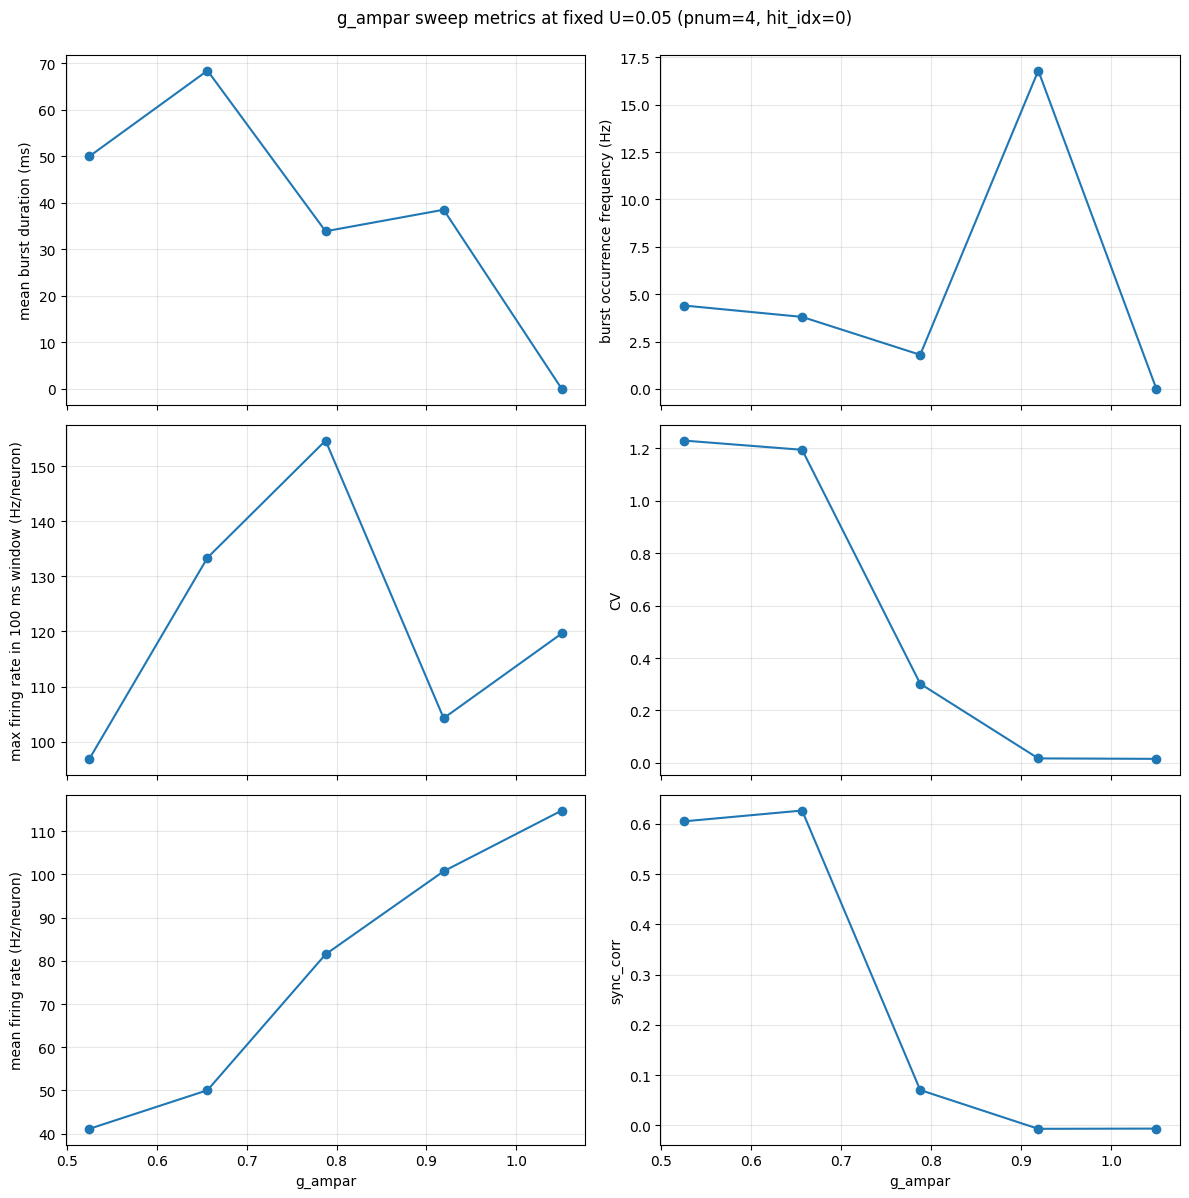

saved: figures/raster_sweep_by_g_ampar2.SVG


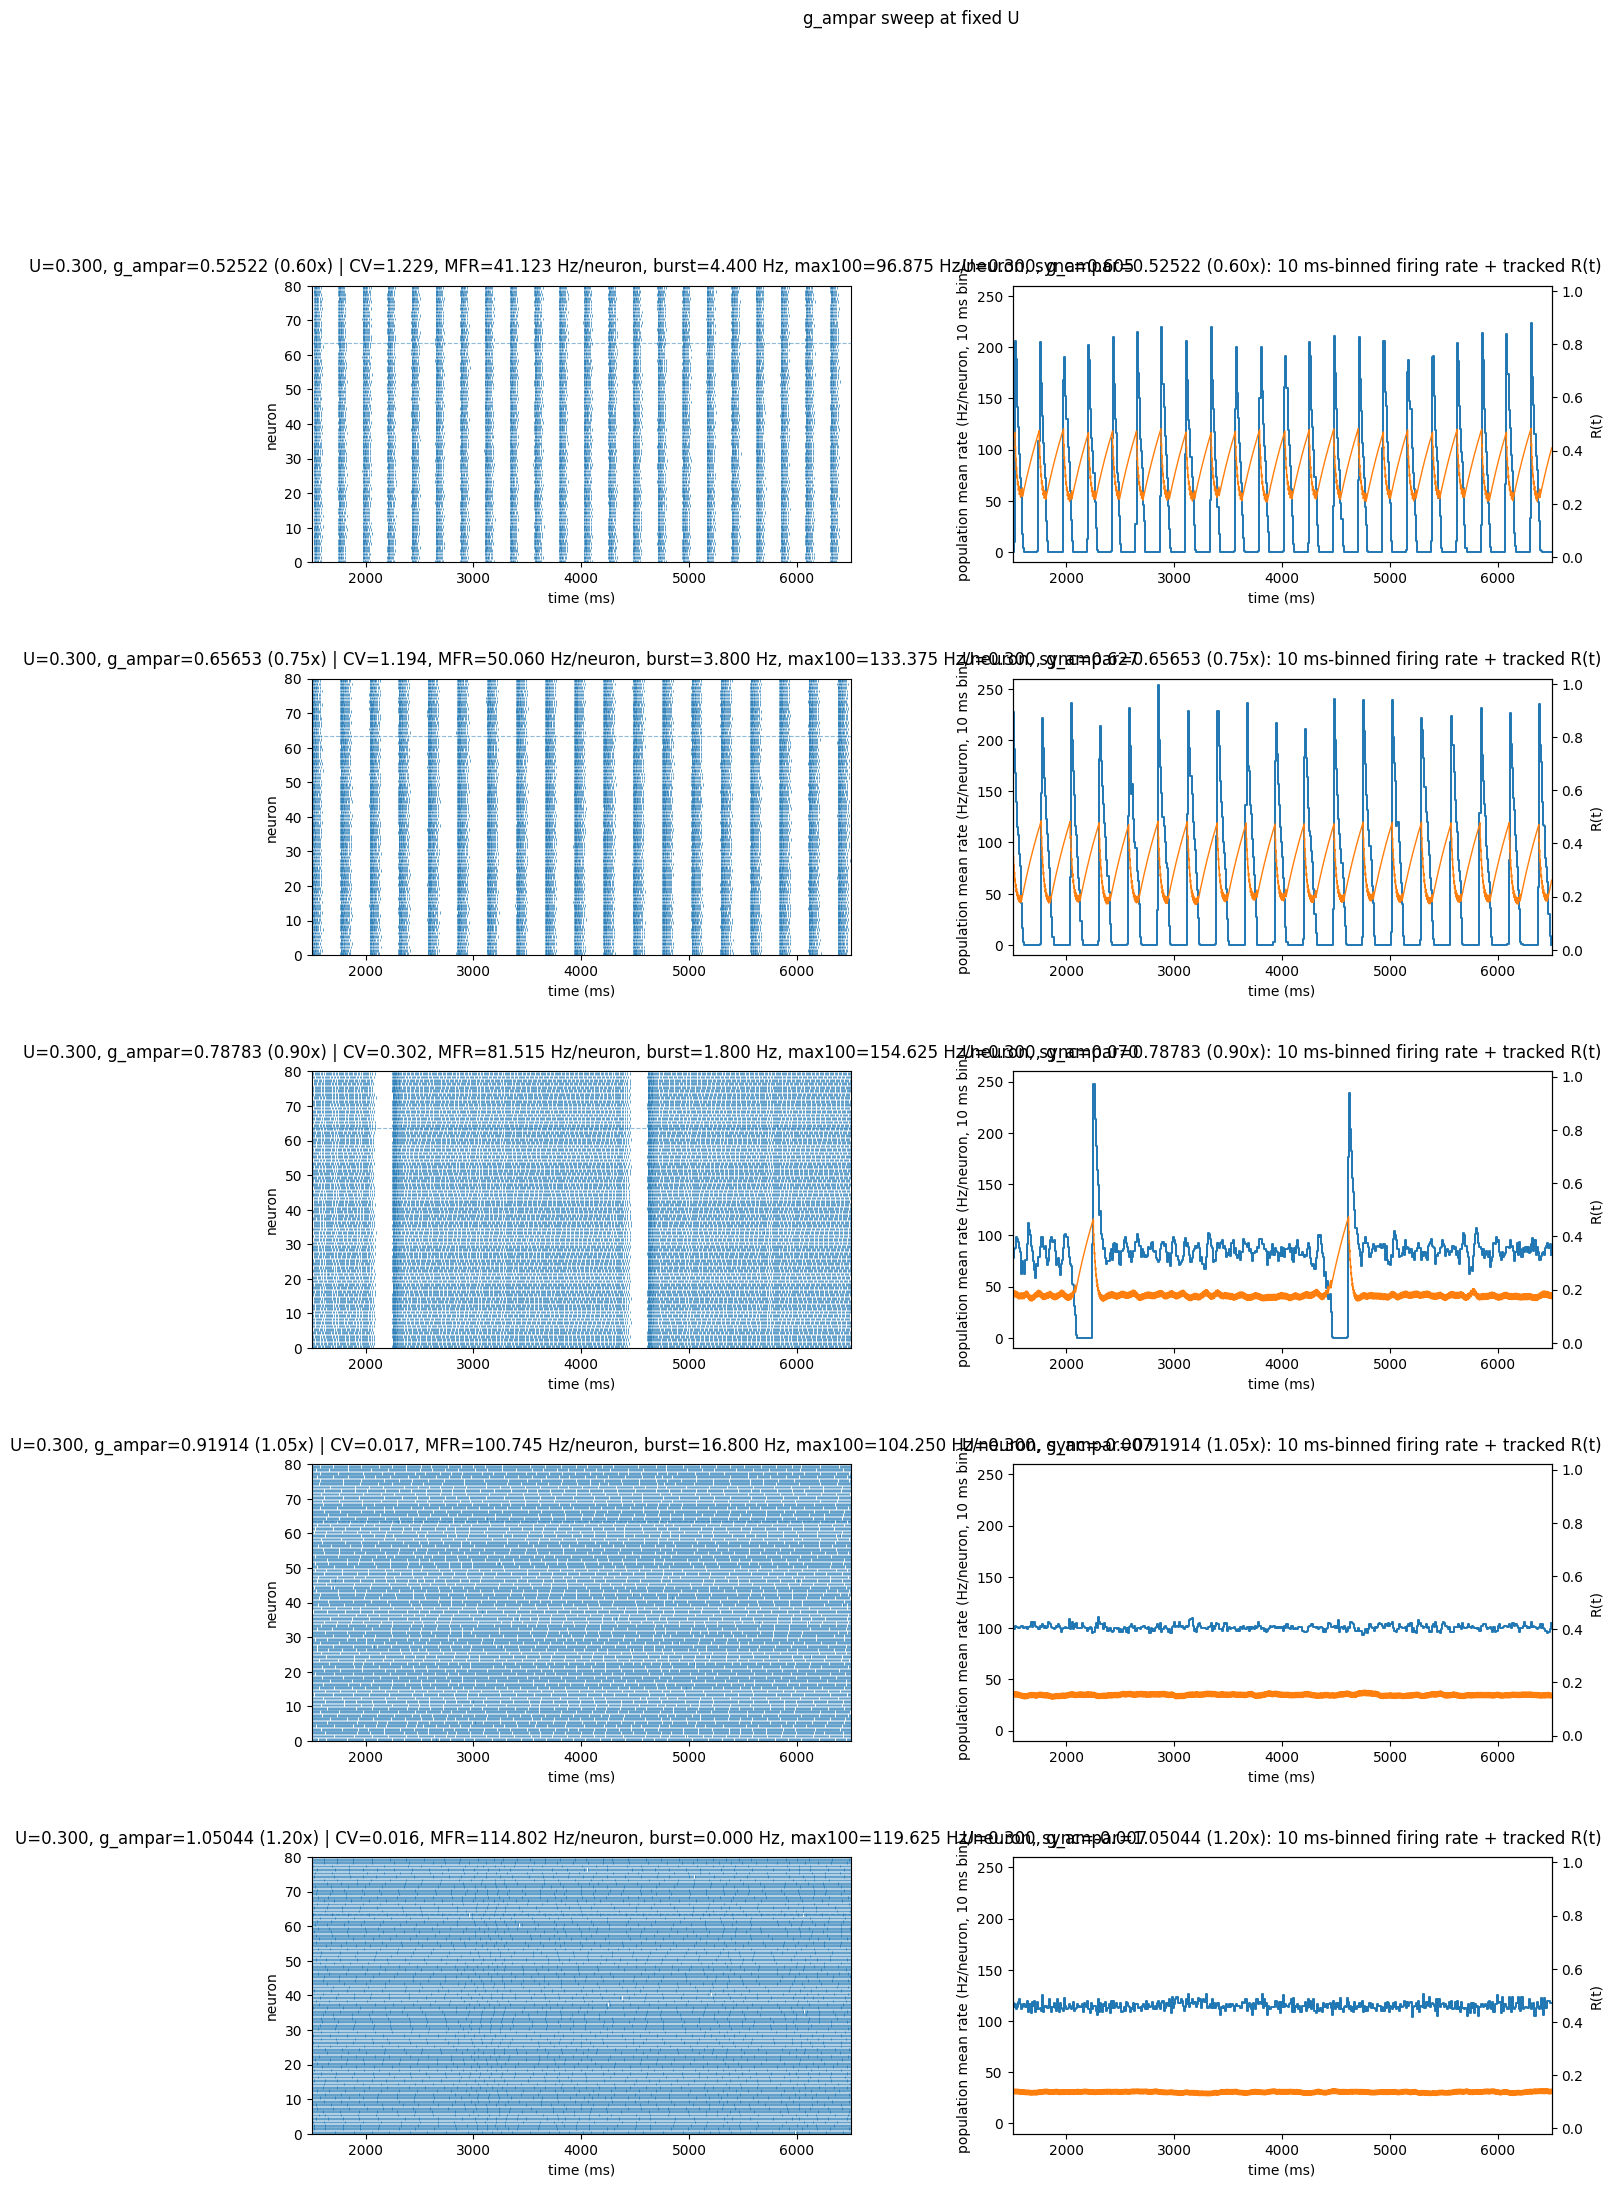

In [6]:
# close up   metrics sweep by w
import traceback
import pickle
import numpy as np


pnums = np.arange(0, 15, 1)
pickle_path_b = "results/U_TRANS_params/2026_3_10_NET_SAN_STP_ULIST_2_10_SAN_SAN_example_CV0_18_13_all/"

name1 = "metrics_sweep_by_g_ampar2"
name2 = "raster_sweep_by_g_ampar2"

for pnum in pnums:
    if pnum != 4:
        continue

    try:
        pickle_path = pickle_path_b + f"U_TRANS_2026_3_10_core{pnum}.pickle"
        objs = load_pickle_objects(pickle_path)
        hits_df = extract_hits(objs)

        print("pickle_num:", pnum)
        print("hits:", len(hits_df))
        print("columns:", list(hits_df.columns))

        if len(hits_df) == 0:
            print(" -> no hits, skip")
            continue

        print(hits_df)

        for hit_idx in range(len(hits_df)):
            if hit_idx != 0:
                continue

            hit_row = hits_df.iloc[hit_idx]
            print("==== hit_idx =", hit_idx, "====")

            results_by_g, metrics_g_df, tracked_synapses = analyze_hit_for_g_ampar_sweep(
                hit_row=hit_row,
                U_fixed=0.3,

                # g_ampar を現在値の x1 〜 x2 倍で 5 段階
                g_ampar_scale_min=0.6,
                g_ampar_scale_max=1.2,
                n_g_ampar=5,

                T_ms=11500.0,
                dt_ms=0.1,
                record_every=1,
                thr=-20.0,

                eval_window_ms=(1500.0, 6500.0),
                cv_w_ms=50.0,
                moving_ms=5.0,

                sync_bin_ms=5.0,
                sync_binary=True,
                sync_on_population="ALL",
                sync_time_window_ms=200.0,
                sync_time_step_ms=50.0,

                burst_threshold=80,

                n_track_synapses=1,
                synapse_seed=0,
                synapse_population="ALL",

                # search 時と同じ値に合わせること
                default_NE=64,
                default_NI=16,
                default_seed=0,
                default_p_ee=0.2,
                default_p_ei=0.4,
                default_p_ie=0.5,
                default_p_ii=0.5,
                default_allow_self=False,
            )

            print(metrics_g_df)

            plot_metrics_vs_g_ampar(
                metrics_g_df,
                title=f"g_ampar sweep metrics at fixed U=0.05 (pnum={pnum}, hit_idx={hit_idx})",
                x_col="g_ampar",  # "g_ampar_scale" でも可
                name = name1
            )

            plot_raster_rate_and_tracked_r_by_g_ampar(
                results_by_g,
                tracked_synapses,
                raster_tlim_ms=(1500.0, 6500.0),
                combined_tlim_ms=(1500.0, 6500.0),
                rate_bin_ms=10.0,
                rate_normalize_by_neuron=True,
                only_first_tracked_synapse=True,
                name = name2
            )

    except Exception:
        traceback.print_exc()

pickle_num: 4
hits: 2
columns: ['g_leak', 'g_kvhh', 'g_cav', 'g_kca', 'g_nap', 't_ca', 'g_ampar', 'g_gabar', 'tau_rec_e', 'tau_rec_i', 'tau_noise', 'sigma_noise', 'intrinsic_id', 'core', 'start_idx', 'end_idx', 'drop', 'max_cv', 'min_cv', 'U_start', 'U_end', 'cv_u0p05', 'rate_u0p05', 'cv0_u0p05', 'cv_hi_thr_u0p05', 'cv_lo_thr_u0p05', 'hi_hit_u0p05', 'lo_hit_u0p05', 'valid_u0p05', 'cv_u0p1', 'rate_u0p1', 'cv0_u0p1', 'cv_hi_thr_u0p1', 'cv_lo_thr_u0p1', 'hi_hit_u0p1', 'lo_hit_u0p1', 'valid_u0p1', 'cv_u0p3', 'rate_u0p3', 'cv0_u0p3', 'cv_hi_thr_u0p3', 'cv_lo_thr_u0p3', 'hi_hit_u0p3', 'lo_hit_u0p3', 'valid_u0p3', 'cv_u0p5', 'rate_u0p5', 'cv0_u0p5', 'cv_hi_thr_u0p5', 'cv_lo_thr_u0p5', 'hi_hit_u0p5', 'lo_hit_u0p5', 'valid_u0p5', 'cv_u0p7', 'rate_u0p7', 'cv0_u0p7', 'cv_hi_thr_u0p7', 'cv_lo_thr_u0p7', 'hi_hit_u0p7', 'lo_hit_u0p7', 'valid_u0p7', 'cv_u0p9', 'rate_u0p9', 'cv0_u0p9', 'cv_hi_thr_u0p9', 'cv_lo_thr_u0p9', 'hi_hit_u0p9', 'lo_hit_u0p9', 'valid_u0p9']
     g_leak    g_kvhh     g_cav     g

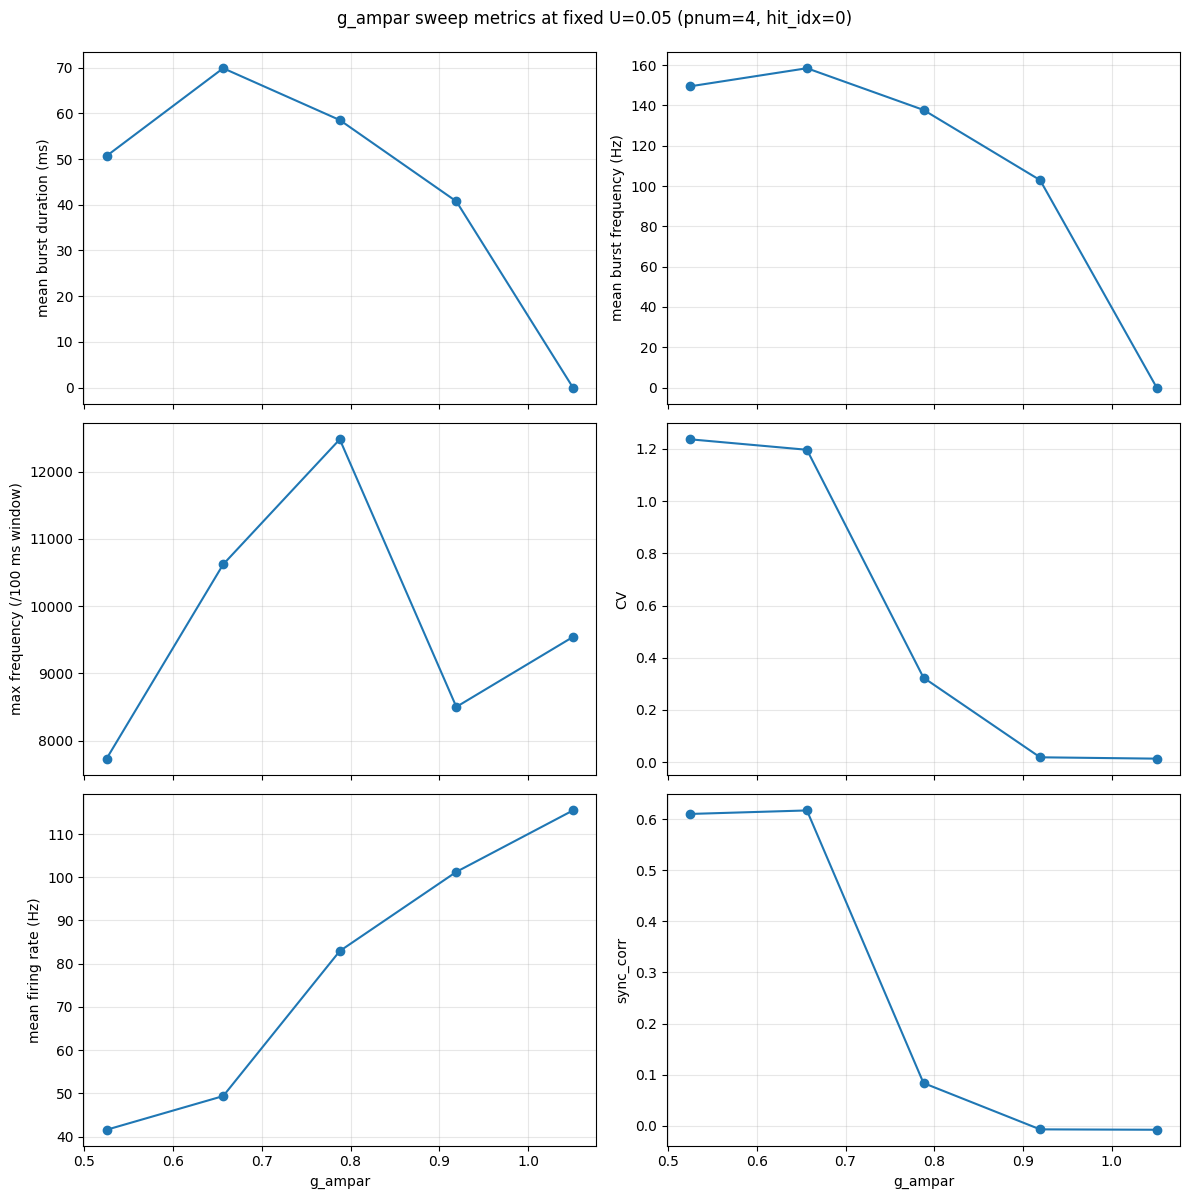

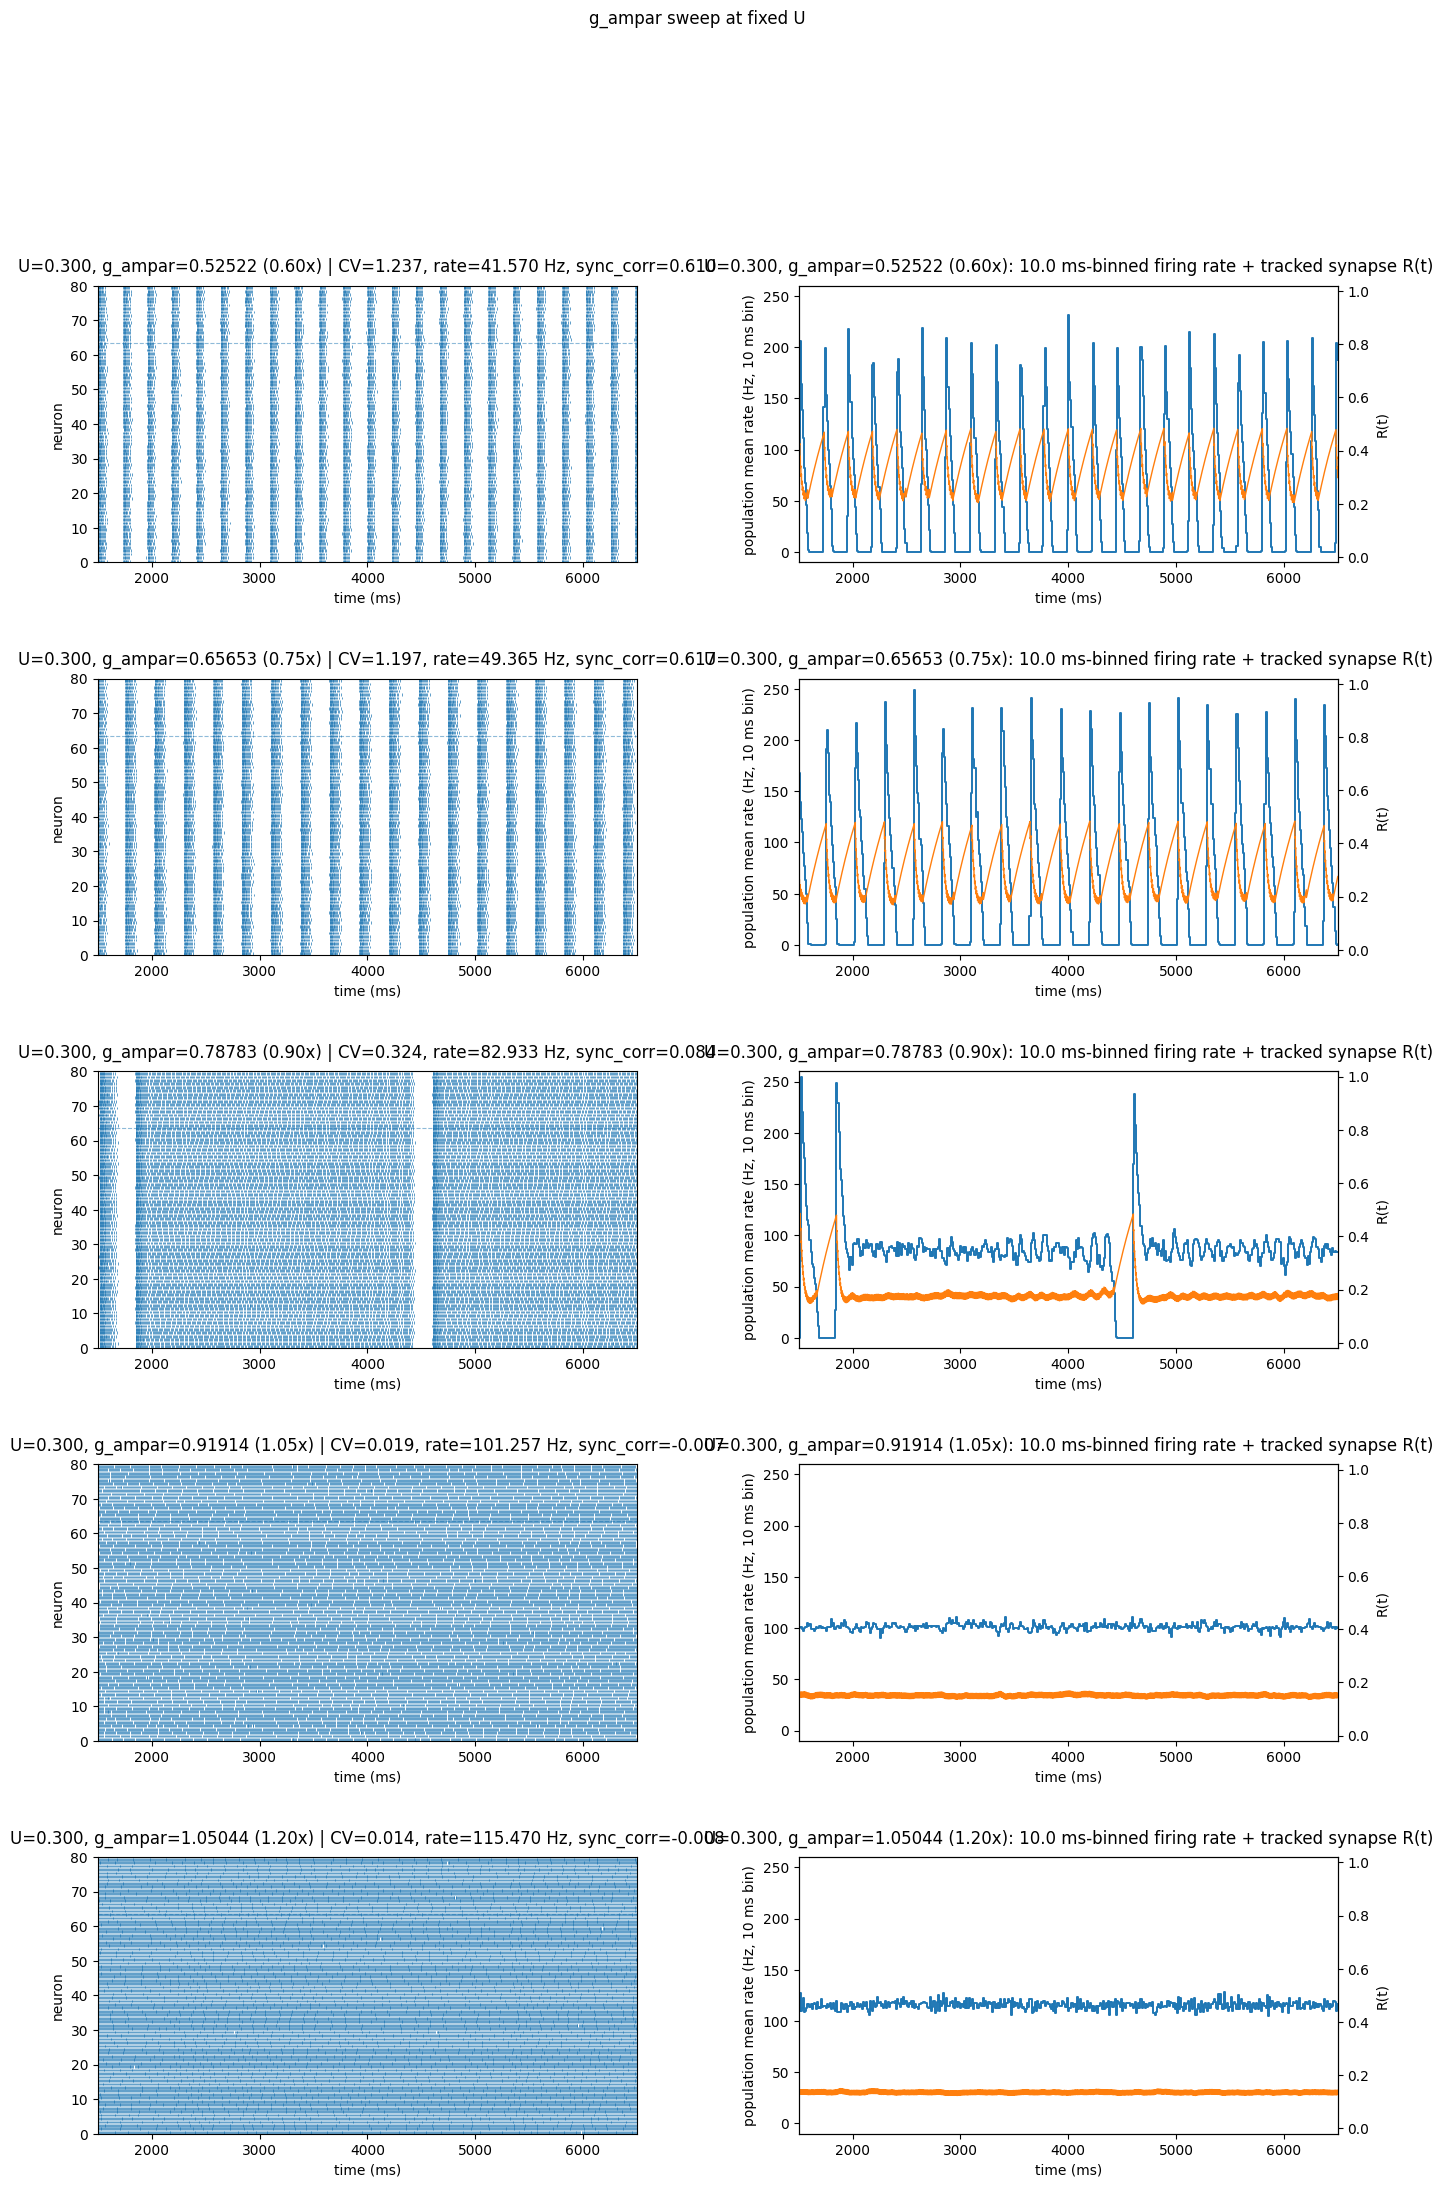

In [8]:
# close up   repre by w
import traceback
import pickle
import numpy as np

pnums = np.arange(0, 15, 1)
pickle_path_b = "results/U_TRANS_params/2026_3_10_NET_SAN_STP_ULIST_2_10_SAN_SAN_example_CV0_18_13_all/"

name1 = "repre_metrics_by_g_ampar_SAN"
name2 = "repre_raster_by_g_ampar_SAN"

for pnum in pnums:
    if pnum != 4:
        continue

    try:
        pickle_path = pickle_path_b + f"U_TRANS_2026_3_10_core{pnum}.pickle"
        objs = load_pickle_objects(pickle_path)
        hits_df = extract_hits(objs)

        print("pickle_num:", pnum)
        print("hits:", len(hits_df))
        print("columns:", list(hits_df.columns))

        if len(hits_df) == 0:
            print(" -> no hits, skip")
            continue

        print(hits_df)

        for hit_idx in range(len(hits_df)):
            if hit_idx != 0:
                continue

            hit_row = hits_df.iloc[hit_idx]
            print("==== hit_idx =", hit_idx, "====")

            results_by_g, metrics_g_df, tracked_synapses = analyze_hit_for_g_ampar_sweep(
                hit_row=hit_row,
                U_fixed=0.3,

                # g_ampar を現在値の x1 〜 x2 倍で 5 段階
                g_ampar_scale_min=0.6,
                g_ampar_scale_max=1.2,
                n_g_ampar=5,

                T_ms=11500.0,
                dt_ms=0.1,
                record_every=1,
                thr=-20.0,

                eval_window_ms=(1500.0, 6500.0),
                cv_w_ms=50.0,
                moving_ms=5.0,

                sync_bin_ms=5.0,
                sync_binary=True,
                sync_on_population="ALL",
                sync_time_window_ms=200.0,
                sync_time_step_ms=50.0,

                burst_threshold=80,

                n_track_synapses=1,
                synapse_seed=0,
                synapse_population="ALL",

                # search 時と同じ値に合わせること
                default_NE=64,
                default_NI=16,
                default_seed=0,
                default_p_ee=0.2,
                default_p_ei=0.2,
                default_p_ie=0.3,
                default_p_ii=0.3,
                default_allow_self=False,
            )

            print(metrics_g_df)

            plot_metrics_vs_g_ampar(
                metrics_g_df,
                title=f"g_ampar sweep metrics at fixed U=0.05 (pnum={pnum}, hit_idx={hit_idx})",
                x_col="g_ampar",  # "g_ampar_scale" でも可
                name = name1
            )

            plot_raster_rate_and_tracked_r_by_g_ampar(
                results_by_g,
                tracked_synapses,
                raster_tlim_ms=(1500.0, 6500.0),
                combined_tlim_ms=(1500.0, 6500.0),
                rate_bin_ms=10.0,
                rate_normalize_by_neuron=True,
                only_first_tracked_synapse=True,
                name = name2
            )

    except Exception:
        traceback.print_exc()

In [ ]:
#repre by g_ampar with mp
# ============================================================
# g_ampar sweep + raster/rate/R(t) + Vm plot
# ============================================================

import traceback
import pickle
from pathlib import Path
from typing import Any, Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec


# ============================================================
# optional save helper
# ============================================================

def _save_fig_if_needed(fig, name=None, fig_dir_path=None, ext=".SVG"):
    """
    name が指定された場合のみ保存する。
    fig_dir_path が None の場合、global fig_dir があれば使う。
    なければ current directory に保存する。
    """
    if name is None:
        return

    if fig_dir_path is None:
        fig_dir_path = globals().get("fig_dir", ".")

    out_dir = Path(fig_dir_path)
    out_dir.mkdir(parents=True, exist_ok=True)

    if not str(ext).startswith("."):
        ext = "." + str(ext)

    fig.savefig(out_dir / f"{name}{ext}")


def _format_synapse_label_safe(s):
    """
    format_synapse_label が既存環境にある場合はそれを使う。
    ない場合は dict/string をそのまま表示する。
    """
    try:
        return format_synapse_label(s)
    except Exception:
        return str(s)


def _as_bool(x):
    """
    bool("False") == True 問題を避けるための安全な bool 変換。
    """
    if isinstance(x, bool):
        return x
    if isinstance(x, str):
        return x.strip().lower() in ["true", "1", "yes", "y", "t"]
    return bool(x)


# ============================================================
# hit_row から network を再構築
# ============================================================

def build_san_network_from_hit(
    hit_row,
    default_NE: int = 64,
    default_NI: int = 16,
    default_seed: int = 0,
    default_p_ee: float = 0.2,
    default_p_ei: float = 0.4,
    default_p_ie: float = 0.5,
    default_p_ii: float = 0.5,
    default_allow_self: bool = False,
):
    """
    hit_row から SANVesicleNetwork を再構築する。

    注意:
    hit_row に NE, NI, seed, p_ee, p_ei, p_ie, p_ii, allow_self が
    保存されていない場合は default_* が使われる。
    search 時と同じ設定にそろえること。
    """
    row_dict = dict(hit_row)
    intrinsic, syn = split_params(row_dict)

    NE = int(syn.get("NE", row_dict.get("NE", default_NE)))
    NI = int(syn.get("NI", row_dict.get("NI", default_NI)))
    seed = int(syn.get("seed", row_dict.get("seed", default_seed)))

    p_ee = float(syn.get("p_ee", row_dict.get("p_ee", default_p_ee)))
    p_ei = float(syn.get("p_ei", row_dict.get("p_ei", default_p_ei)))
    p_ie = float(syn.get("p_ie", row_dict.get("p_ie", default_p_ie)))
    p_ii = float(syn.get("p_ii", row_dict.get("p_ii", default_p_ii)))

    allow_self = _as_bool(
        syn.get("allow_self", row_dict.get("allow_self", default_allow_self))
    )

    net = SANVesicleNetwork(
        NE=NE,
        NI=NI,
        seed=seed,
        p_ee=p_ee,
        p_ei=p_ei,
        p_ie=p_ie,
        p_ii=p_ii,
        allow_self=allow_self,
    )

    net.set_intrinsic_params(intrinsic)
    net.set_network_params(syn)

    return net, intrinsic, syn


# ============================================================
# g_ampar sweep 値を作る
# ============================================================

def make_g_ampar_list_from_hit(
    hit_row,
    scale_min: float = 1.0,
    scale_max: float = 2.0,
    n_steps: int = 5,
) -> Tuple[float, np.ndarray, np.ndarray]:
    """
    hit_row 内の g_ampar を基準に、
    x scale_min 〜 x scale_max を n_steps 段階で作る。

    Returns
    -------
    base_g_ampar : float
    scales : np.ndarray
    g_values : np.ndarray
    """
    row_dict = dict(hit_row)
    _, syn = split_params(row_dict)

    if "g_ampar" in syn and pd.notna(syn["g_ampar"]):
        base_g_ampar = float(syn["g_ampar"])
    elif "g_ampar" in row_dict and pd.notna(row_dict["g_ampar"]):
        base_g_ampar = float(row_dict["g_ampar"])
    else:
        raise KeyError("hit_row から g_ampar を取得できませんでした。")

    if base_g_ampar <= 0:
        raise ValueError(f"base_g_ampar must be > 0. got {base_g_ampar}")
    if n_steps < 2:
        raise ValueError("n_steps must be >= 2")

    scales = np.linspace(float(scale_min), float(scale_max), int(n_steps))
    g_values = base_g_ampar * scales

    return base_g_ampar, scales, g_values


# ============================================================
# Vm 表示用ニューロンを選ぶ
# ============================================================

def choose_vm_neurons_from_net(
    net,
    n_vm_neurons: int = 2,
    vm_seed: int = 0,
):
    """
    g_ampar sweep 全条件で同じ興奮性ニューロンを Vm 表示用に選ぶ。
    """
    n_vm_pick = min(int(n_vm_neurons), int(net.NE))

    if n_vm_pick <= 0:
        return np.array([], dtype=int)

    rng = np.random.default_rng(int(vm_seed))
    vm_neuron_idx = np.sort(
        rng.choice(np.arange(net.NE), size=n_vm_pick, replace=False)
    )

    return vm_neuron_idx.astype(int)


# ============================================================
# Vm 記録専用の 1 条件実行
# ============================================================

def record_vm_for_one_g_ampar_from_hit(
    hit_row,
    g_ampar: float,
    U_fixed: float,
    vm_neuron_idx,
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    thr: float = -20.0,

    # rebuild defaults
    default_NE: int = 64,
    default_NI: int = 16,
    default_seed: int = 0,
    default_p_ee: float = 0.2,
    default_p_ei: float = 0.2,
    default_p_ie: float = 0.3,
    default_p_ii: float = 0.3,
    default_allow_self: bool = False,
):
    """
    Vm 表示用に fresh network を作り、指定 g_ampar, U_fixed で run_and_raster_oneU を実行する。

    Returns
    -------
    vm_t_ms : np.ndarray
        記録時刻 [ms]
    vm_traces : np.ndarray
        shape = (n_vm_neurons, n_time)
    """
    net_vm, intrinsic, syn = build_san_network_from_hit(
        hit_row,
        default_NE=default_NE,
        default_NI=default_NI,
        default_seed=default_seed,
        default_p_ee=default_p_ee,
        default_p_ei=default_p_ei,
        default_p_ie=default_p_ie,
        default_p_ii=default_p_ii,
        default_allow_self=default_allow_self,
    )

    net_vm.set_network_params({"g_ampar": float(g_ampar)})

    t_ms, v_mat, spk_times = run_and_raster_oneU(
        net_vm,
        float(U_fixed),
        T_ms=T_ms,
        dt_ms=dt_ms,
        record_every=record_every,
        thr=thr,
    )

    vm_neuron_idx = np.asarray(vm_neuron_idx, dtype=int)

    if vm_neuron_idx.size == 0:
        vm_traces = np.empty((0, len(t_ms)), dtype=float)
    else:
        vm_traces = np.asarray(v_mat[:, vm_neuron_idx], dtype=float).T

    return np.asarray(t_ms, dtype=float), vm_traces


# ============================================================
# 1つの g_ampar 条件を解析
# ============================================================

def analyze_one_g_ampar(
    net,
    g_ampar: float,
    U_fixed: float,
    tracked_synapses: List[Dict[str, Any]],
    base_g_ampar: float,
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    thr: float = -20.0,
    eval_window_ms: Tuple[float, float] = (1500.0, 11500.0),
    cv_w_ms: float = 50.0,
    moving_ms: float = 5.0,
    sync_bin_ms: float = 5.0,
    sync_binary: bool = True,
    sync_on_population: str = "ALL",
    sync_time_window_ms: float = 200.0,
    sync_time_step_ms: float = 50.0,
    burst_threshold: int = 80,
):
    """
    U を固定し、g_ampar を指定値にして 1 条件解析する。
    """
    net.set_network_params({"g_ampar": float(g_ampar)})

    res = analyze_one_U(
        net=net,
        U=float(U_fixed),
        tracked_synapses=tracked_synapses,
        T_ms=T_ms,
        dt_ms=dt_ms,
        record_every=record_every,
        thr=thr,
        eval_window_ms=eval_window_ms,
        cv_w_ms=cv_w_ms,
        moving_ms=moving_ms,
        sync_bin_ms=sync_bin_ms,
        sync_binary=sync_binary,
        sync_on_population=sync_on_population,
        sync_time_window_ms=sync_time_window_ms,
        sync_time_step_ms=sync_time_step_ms,
        burst_threshold=burst_threshold,
    )

    res["g_ampar"] = float(g_ampar)
    res["base_g_ampar"] = float(base_g_ampar)
    res["g_ampar_scale"] = float(g_ampar / base_g_ampar) if base_g_ampar > 0 else np.nan
    res["U_fixed"] = float(U_fixed)

    return res


# ============================================================
# hit_row に対する g_ampar sweep 全体
# Vm 記録込み
# ============================================================

def analyze_hit_for_g_ampar_sweep(
    hit_row,
    U_fixed: float = 0.05,

    # g_ampar sweep
    g_ampar_scale_min: float = 1.0,
    g_ampar_scale_max: float = 2.0,
    n_g_ampar: int = 5,
    g_ampar_list: Optional[List[float]] = None,

    # simulation / analysis
    T_ms: float = 20000.0,
    dt_ms: float = 0.1,
    record_every: int = 10,
    thr: float = -20.0,
    eval_window_ms: Tuple[float, float] = (1500.0, 11500.0),
    cv_w_ms: float = 50.0,
    moving_ms: float = 5.0,
    sync_bin_ms: float = 5.0,
    sync_binary: bool = True,
    sync_on_population: str = "ALL",
    sync_time_window_ms: float = 200.0,
    sync_time_step_ms: float = 50.0,
    burst_threshold: int = 80,

    # tracked synapse
    n_track_synapses: int = 1,
    synapse_seed: int = 0,
    synapse_population: str = "ALL",

    # Vm plot
    record_vm: bool = True,
    n_vm_neurons: int = 2,
    vm_seed: int = 0,

    # rebuild defaults
    default_NE: int = 64,
    default_NI: int = 16,
    default_seed: int = 0,
    default_p_ee: float = 0.2,
    default_p_ei: float = 0.2,
    default_p_ie: float = 0.3,
    default_p_ii: float = 0.3,
    default_allow_self: bool = False,
):
    """
    hit_row を再構築し、U を固定したまま g_ampar を掃引して解析する。
    さらに、各 g_ampar 条件で固定した興奮性ニューロンの Vm を保存する。
    """
    net, intrinsic, syn = build_san_network_from_hit(
        hit_row,
        default_NE=default_NE,
        default_NI=default_NI,
        default_seed=default_seed,
        default_p_ee=default_p_ee,
        default_p_ei=default_p_ei,
        default_p_ie=default_p_ie,
        default_p_ii=default_p_ii,
        default_allow_self=default_allow_self,
    )

    row_dict = dict(hit_row)

    if "g_ampar" in syn and pd.notna(syn["g_ampar"]):
        base_g_ampar = float(syn["g_ampar"])
    elif "g_ampar" in row_dict and pd.notna(row_dict["g_ampar"]):
        base_g_ampar = float(row_dict["g_ampar"])
    else:
        raise KeyError("hit_row から g_ampar を取得できませんでした。")

    if base_g_ampar <= 0:
        raise ValueError(f"base_g_ampar must be > 0. got {base_g_ampar}")

    if g_ampar_list is None:
        g_scales = np.linspace(
            float(g_ampar_scale_min),
            float(g_ampar_scale_max),
            int(n_g_ampar),
        )
        g_values = base_g_ampar * g_scales
    else:
        g_values = np.asarray(g_ampar_list, dtype=float)
        if g_values.ndim != 1 or g_values.size == 0:
            raise ValueError("g_ampar_list must be a non-empty 1D array/list.")
        g_scales = g_values / base_g_ampar

    tracked_synapses = choose_tracked_synapses(
        net,
        n_track=int(n_track_synapses),
        seed=int(synapse_seed),
        synapse_population=synapse_population,
    )

    vm_neuron_idx = choose_vm_neurons_from_net(
        net,
        n_vm_neurons=int(n_vm_neurons),
        vm_seed=int(vm_seed),
    )

    print(f"base g_ampar = {base_g_ampar:.6f}")
    print("g_ampar scales =", g_scales)
    print("g_ampar values =", g_values)

    if record_vm:
        print("Selected excitatory neurons for Vm plot:", vm_neuron_idx.tolist())

    results_by_g = []
    metrics_rows = []

    for g_val, g_scale in zip(g_values, g_scales):
        print(f"running g_ampar={float(g_val):.6f} ({float(g_scale):.3f}x)")

        res = analyze_one_g_ampar(
            net=net,
            g_ampar=float(g_val),
            U_fixed=float(U_fixed),
            tracked_synapses=tracked_synapses,
            base_g_ampar=float(base_g_ampar),
            T_ms=T_ms,
            dt_ms=dt_ms,
            record_every=record_every,
            thr=thr,
            eval_window_ms=eval_window_ms,
            cv_w_ms=cv_w_ms,
            moving_ms=moving_ms,
            sync_bin_ms=sync_bin_ms,
            sync_binary=sync_binary,
            sync_on_population=sync_on_population,
            sync_time_window_ms=sync_time_window_ms,
            sync_time_step_ms=sync_time_step_ms,
            burst_threshold=burst_threshold,
        )

        # ----------------------------------------------------
        # Vm 記録
        # ----------------------------------------------------
        if record_vm:
            vm_t_ms, vm_traces = record_vm_for_one_g_ampar_from_hit(
                hit_row=hit_row,
                g_ampar=float(g_val),
                U_fixed=float(U_fixed),
                vm_neuron_idx=vm_neuron_idx,
                T_ms=T_ms,
                dt_ms=dt_ms,
                record_every=record_every,
                thr=thr,
                default_NE=default_NE,
                default_NI=default_NI,
                default_seed=default_seed,
                default_p_ee=default_p_ee,
                default_p_ei=default_p_ei,
                default_p_ie=default_p_ie,
                default_p_ii=default_p_ii,
                default_allow_self=default_allow_self,
            )

            res["vm_t_ms"] = vm_t_ms
            res["vm_traces"] = vm_traces
            res["vm_neuron_idx"] = vm_neuron_idx.copy()
        else:
            res["vm_t_ms"] = np.array([], dtype=float)
            res["vm_traces"] = np.empty((0, 0), dtype=float)
            res["vm_neuron_idx"] = np.array([], dtype=int)

        results_by_g.append(res)

        metrics_rows.append({
            "U_fixed": float(U_fixed),
            "base_g_ampar": float(base_g_ampar),
            "g_ampar": float(g_val),
            "g_ampar_scale": float(g_scale),
            "mean_burst_duration": res.get("mean_burst_duration", np.nan),
            "mean_burst_frequency": res.get("mean_burst_frequency", np.nan),
            "max_frequency": res.get("max_frequency", np.nan),
            "CV": res.get("CV", np.nan),
            "mean_firing_rate": res.get("mean_firing_rate", np.nan),
            "sync_corr": res.get("sync_corr", np.nan),
            "n_bursts": res.get("n_bursts", np.nan),
            "sync_n_valid": res.get("sync_n_valid", np.nan),
            "sync_population": res.get("sync_population", sync_on_population),
        })

    metrics_df = (
        pd.DataFrame(metrics_rows)
        .sort_values("g_ampar")
        .reset_index(drop=True)
    )

    return results_by_g, metrics_df, tracked_synapses


# ============================================================
# g_ampar に対する指標プロット
# ============================================================

def plot_metrics_vs_g_ampar(
    df: pd.DataFrame,
    title: str = None,
    x_col: str = "g_ampar",   # or "g_ampar_scale"
    name=None,
    fig_dir_path=None,
):
    df = df.sort_values(x_col).reset_index(drop=True)

    fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True)
    axes = axes.ravel()

    metrics = [
        ("mean_burst_duration", "mean burst duration (ms)"),
        ("mean_burst_frequency", "mean burst frequency (Hz)"),
        ("max_frequency", "max frequency (/100 ms window)"),
        ("CV", "CV"),
        ("mean_firing_rate", "mean firing rate (Hz)"),
        ("sync_corr", "sync_corr"),
    ]

    for ax, (col, ylabel) in zip(axes, metrics):
        if col in df.columns:
            ax.plot(df[x_col], df[col], marker="o")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)

    axes[-2].set_xlabel(x_col)
    axes[-1].set_xlabel(x_col)

    if title is not None:
        fig.suptitle(title, y=0.995)

    fig.tight_layout()

    _save_fig_if_needed(fig, name=name, fig_dir_path=fig_dir_path, ext=".SVG")

    plt.show()


# ============================================================
# g_ampar ごとの raster + rate + tracked R(t) + Vm
# ============================================================

def plot_raster_rate_and_tracked_r_by_g_ampar(
    results_by_g: List[Dict[str, Any]],
    tracked_synapses: List[Dict[str, Any]],
    raster_tlim_ms: Tuple[float, float] = (1500.0, 11500.0),
    combined_tlim_ms: Tuple[float, float] = None,
    rate_bin_ms: float = 50.0,
    rate_normalize_by_neuron: bool = True,
    only_first_tracked_synapse: bool = True,

    # Vm plot
    plot_vm: bool = True,
    vm_tlim_ms: Tuple[float, float] = None,
    vm_lw: float = 0.8,
    vm_ylim: Tuple[float, float] = (-85.0, 40.0),
    vm_thr_line: Optional[float] = -20.0,

    raster_height: float = 4.2,
    vm_height: float = 2.0,

    name=None,
    fig_dir_path=None,
):
    """
    各 g_ampar ごとに
      上段左  : raster
      上段右  : firing rate + tracked synapse R(t)
      下段    : selected excitatory neurons の Vm
    を描画する。
    """
    if len(results_by_g) == 0:
        raise ValueError("results_by_g is empty.")

    results_sorted = sorted(results_by_g, key=lambda x: x["g_ampar"])
    nG = len(results_sorted)

    if combined_tlim_ms is None:
        if len(results_sorted[0].get("r_times", [])) > 0:
            t_min = float(np.min(results_sorted[0]["r_times"]))
            t_max = float(np.max(results_sorted[0]["r_times"]))
        else:
            t_min, t_max = 0.0, 0.0
        combined_tlim_ms = (t_min, t_max)

    if vm_tlim_ms is None:
        vm_tlim_ms = combined_tlim_ms

    synapse_labels = [_format_synapse_label_safe(s) for s in tracked_synapses]

    # Vm パネル数を決める
    n_vm = 0
    if plot_vm:
        for res in results_sorted:
            vm_traces = np.asarray(res.get("vm_traces", np.empty((0, 0))))
            if vm_traces.ndim == 2:
                n_vm = max(n_vm, vm_traces.shape[0])

    n_rows_per_g = 1 + n_vm
    height_one_g = raster_height + vm_height * n_vm
    fig_height = max(4.5, nG * height_one_g * 1.4)

    fig = plt.figure(figsize=(16, fig_height))
    outer = gridspec.GridSpec(
        nG,
        1,
        hspace=0.42,
    )

    for i, res in enumerate(results_sorted):
        g_ampar = float(res["g_ampar"])
        g_scale = float(res["g_ampar_scale"])
        U_fixed = float(res["U_fixed"])

        spike_times = res["spike_times"]
        N = int(res["N"])
        NE = int(res["NE"])

        t_ms_r = np.asarray(res.get("r_times", np.array([])), dtype=float)
        r_trace = np.asarray(res.get("r_trace", np.empty((0, 0))), dtype=float)

        if r_trace.ndim == 1:
            r_trace = r_trace[None, :]

        CV = float(res["CV"]) if np.isfinite(res.get("CV", np.nan)) else np.nan
        mean_rate = float(res["mean_firing_rate"]) if np.isfinite(res.get("mean_firing_rate", np.nan)) else np.nan
        sync_corr = float(res["sync_corr"]) if np.isfinite(res.get("sync_corr", np.nan)) else np.nan

        height_ratios = [raster_height] + [vm_height] * n_vm

        inner = gridspec.GridSpecFromSubplotSpec(
            n_rows_per_g,
            2,
            subplot_spec=outer[i],
            width_ratios=[1.0, 1.0],
            height_ratios=height_ratios,
            wspace=0.30,
            hspace=0.28,
        )

        # ----------------------------------------------------
        # 上段左: raster
        # ----------------------------------------------------
        ax_raster = fig.add_subplot(inner[0, 0])
        t0_ras, t1_ras = raster_tlim_ms

        for n_idx in range(len(spike_times)):
            st = np.asarray(spike_times[n_idx], dtype=float)
            if st.size == 0:
                continue

            st = st[(st >= t0_ras) & (st <= t1_ras)]

            if st.size > 0:
                ax_raster.vlines(
                    st,
                    n_idx,
                    n_idx + 0.8,
                    lw=0.5,
                    rasterized=True,
                )

        ax_raster.axhline(NE - 0.5, ls="--", lw=0.8, alpha=0.5)
        ax_raster.set_xlim(t0_ras, t1_ras)
        ax_raster.set_ylim(0, N)
        ax_raster.set_ylabel("neuron")
        ax_raster.set_xlabel("time (ms)")

        ax_raster.set_title(
            f"Raster | U={U_fixed:.3f}, "
            f"g_ampar={g_ampar:.5f} ({g_scale:.2f}x) | "
            f"CV={CV:.3f}, rate={mean_rate:.3f} Hz, sync_corr={sync_corr:.3f}",
            pad=10,
        )

        # ----------------------------------------------------
        # 上段右: firing rate + R(t)
        # ----------------------------------------------------
        ax_rate = fig.add_subplot(inner[0, 1])
        ax_r = ax_rate.twinx()

        t0_c, t1_c = combined_tlim_ms

        t_rate, y_rate = population_rate_series_binned(
            spike_times=spike_times,
            N=N,
            t_start_ms=t0_c,
            t_end_ms=t1_c,
            bin_ms=rate_bin_ms,
            normalize_by_neuron=rate_normalize_by_neuron,
        )

        handles = []
        labels = []

        if y_rate.size > 0:
            ln_rate = ax_rate.step(
                t_rate,
                y_rate,
                where="mid",
                lw=1.4,
                label=(
                    f"pop mean rate ({rate_bin_ms:.0f} ms bin)"
                    if rate_normalize_by_neuron
                    else f"pop total rate ({rate_bin_ms:.0f} ms bin)"
                ),
            )[0]
            handles.append(ln_rate)
            labels.append(ln_rate.get_label())

        if r_trace.size > 0 and t_ms_r.size > 0:
            mask_r = (t_ms_r >= t0_c) & (t_ms_r <= t1_c)
            t_plot_r = t_ms_r[mask_r]

            n_plot_syn = r_trace.shape[0]

            if only_first_tracked_synapse:
                n_plot_syn = min(1, n_plot_syn)

            for k in range(n_plot_syn):
                if k >= len(synapse_labels):
                    label_k = f"synapse {k}"
                else:
                    label_k = synapse_labels[k]

                y_plot_r = r_trace[k, mask_r]

                ln_r, = ax_r.plot(
                    t_plot_r,
                    y_plot_r,
                    lw=1.0,
                    label=label_k,
                    c="tab:orange",
                )
                handles.append(ln_r)
                labels.append(ln_r.get_label())

        ax_rate.set_xlim(t0_c, t1_c)
        ax_rate.set_xlabel("time (ms)")
        ax_rate.set_ylim(-10, 260)

        if rate_normalize_by_neuron:
            ax_rate.set_ylabel(f"population mean rate (Hz, {rate_bin_ms:.0f} ms bin)")
        else:
            ax_rate.set_ylabel(f"population total rate (spikes/s, {rate_bin_ms:.0f} ms bin)")

        ax_r.set_ylabel("R(t)")
        ax_r.set_ylim(-0.02, 1.02)

        ax_rate.set_title(
            f"Rate + tracked R(t) | "
            f"U={U_fixed:.3f}, g_ampar={g_ampar:.5f} ({g_scale:.2f}x)",
            pad=10,
        )

        # ----------------------------------------------------
        # 下段: Vm
        # ----------------------------------------------------
        if plot_vm and n_vm > 0:
            vm_t_ms = np.asarray(res.get("vm_t_ms", np.array([])), dtype=float)
            vm_traces = np.asarray(res.get("vm_traces", np.empty((0, 0))), dtype=float)
            vm_neuron_idx = np.asarray(
                res.get("vm_neuron_idx", np.array([], dtype=int)),
                dtype=int,
            )

            t0_vm, t1_vm = vm_tlim_ms

            for k in range(n_vm):
                ax_vm = fig.add_subplot(inner[1 + k, :])

                if (
                    vm_t_ms.size > 0
                    and vm_traces.ndim == 2
                    and k < vm_traces.shape[0]
                ):
                    mask_vm = (vm_t_ms >= t0_vm) & (vm_t_ms <= t1_vm)

                    if k < len(vm_neuron_idx):
                        vm_label = f"E{int(vm_neuron_idx[k])}"
                    else:
                        vm_label = f"E neuron {k}"

                    ax_vm.plot(
                        vm_t_ms[mask_vm],
                        vm_traces[k, mask_vm],
                        lw=vm_lw,
                    )
                    ax_vm.set_ylabel(f"{vm_label}\nVm")

                else:
                    ax_vm.text(
                        0.5,
                        0.5,
                        "Vm not recorded",
                        transform=ax_vm.transAxes,
                        ha="center",
                        va="center",
                    )
                    ax_vm.set_ylabel("Vm")

                ax_vm.set_xlim(t0_vm, t1_vm)
                ax_vm.set_ylim(vm_ylim)

                if vm_thr_line is not None:
                    ax_vm.axhline(
                        float(vm_thr_line),
                        ls="--",
                        lw=0.6,
                        alpha=0.5,
                    )

                ax_vm.axvspan(t0_vm, t1_vm, color="k", alpha=0.03, lw=0)

                if k == 0:
                    ax_vm.set_title(
                        f"Membrane potentials of fixed excitatory neurons "
                        f"| g_ampar={g_ampar:.5f} ({g_scale:.2f}x)"
                    )

                if k == n_vm - 1:
                    ax_vm.set_xlabel("time (ms)")
                else:
                    ax_vm.set_xlabel("")

    fig.suptitle(
        "g_ampar sweep at fixed U: raster, firing rate, synaptic R(t), and Vm",
        y=0.995,
    )

    fig.tight_layout(rect=[0, 0, 1, 0.985])

    _save_fig_if_needed(fig, name=name, fig_dir_path=fig_dir_path, ext=".SVG")

    plt.show()


# ============================================================
# 実行例
# ============================================================

pnums = np.arange(0, 15, 1)

pickle_path_b = "results/U_TRANS_params/2026_3_10_NET_SAN_STP_ULIST_2_10_SAN_SAN_example_CV0_18_13_all/"

name1 = "repre_metrics_by_g_ampar_SAN"
name2 = "repre_raster_rate_R_vm_by_g_ampar_SAN"

for pnum in pnums:
    if pnum != 4:
        continue

    try:
        pickle_path = pickle_path_b + f"U_TRANS_2026_3_10_core{pnum}.pickle"

        objs = load_pickle_objects(pickle_path)
        hits_df = extract_hits(objs)

        print("pickle_num:", pnum)
        print("hits:", len(hits_df))
        print("columns:", list(hits_df.columns))

        if len(hits_df) == 0:
            print(" -> no hits, skip")
            continue

        print(hits_df)

        for hit_idx in range(len(hits_df)):
            if hit_idx != 0:
                continue

            hit_row = hits_df.iloc[hit_idx]

            print("==== hit_idx =", hit_idx, "====")

            results_by_g, metrics_g_df, tracked_synapses = analyze_hit_for_g_ampar_sweep(
                hit_row=hit_row,
                U_fixed=0.3,

                # g_ampar を現在値の x0.6 〜 x1.2 倍で 5 段階
                g_ampar_scale_min=0.6,
                g_ampar_scale_max=1.2,
                n_g_ampar=5,

                T_ms=11500.0,
                dt_ms=0.1,
                record_every=1,
                thr=-20.0,

                eval_window_ms=(1500.0, 6500.0),
                cv_w_ms=50.0,
                moving_ms=5.0,

                sync_bin_ms=5.0,
                sync_binary=True,
                sync_on_population="ALL",
                sync_time_window_ms=200.0,
                sync_time_step_ms=50.0,

                burst_threshold=80,

                n_track_synapses=1,
                synapse_seed=0,
                synapse_population="ALL",

                # Vm plot
                record_vm=True,
                n_vm_neurons=2,
                vm_seed=0,

                # search 時と同じ値に合わせる
                default_NE=64,
                default_NI=16,
                default_seed=0,
                default_p_ee=0.2,
                default_p_ei=0.2,
                default_p_ie=0.3,
                default_p_ii=0.3,
                default_allow_self=False,
            )

            print(metrics_g_df)

            plot_metrics_vs_g_ampar(
                metrics_g_df,
                title=f"g_ampar sweep metrics at fixed U=0.3 (pnum={pnum}, hit_idx={hit_idx})",
                x_col="g_ampar",
                name=name1,
            )

            plot_raster_rate_and_tracked_r_by_g_ampar(
                results_by_g,
                tracked_synapses,

                raster_tlim_ms=(1500.0, 6500.0),
                combined_tlim_ms=(1500.0, 6500.0),

                rate_bin_ms=10.0,
                rate_normalize_by_neuron=True,
                only_first_tracked_synapse=True,

                # Vm 表示
                plot_vm=True,
                vm_tlim_ms=(1500.0, 6500.0),
                vm_lw=0.8,
                vm_ylim=(-85, 40),
                vm_thr_line=-20.0,

                name=name2,
            )

    except Exception:
        traceback.print_exc()

pickle_num: 4
hits: 2
columns: ['g_leak', 'g_kvhh', 'g_cav', 'g_kca', 'g_nap', 't_ca', 'g_ampar', 'g_gabar', 'tau_rec_e', 'tau_rec_i', 'tau_noise', 'sigma_noise', 'intrinsic_id', 'core', 'start_idx', 'end_idx', 'drop', 'max_cv', 'min_cv', 'U_start', 'U_end', 'cv_u0p05', 'rate_u0p05', 'cv0_u0p05', 'cv_hi_thr_u0p05', 'cv_lo_thr_u0p05', 'hi_hit_u0p05', 'lo_hit_u0p05', 'valid_u0p05', 'cv_u0p1', 'rate_u0p1', 'cv0_u0p1', 'cv_hi_thr_u0p1', 'cv_lo_thr_u0p1', 'hi_hit_u0p1', 'lo_hit_u0p1', 'valid_u0p1', 'cv_u0p3', 'rate_u0p3', 'cv0_u0p3', 'cv_hi_thr_u0p3', 'cv_lo_thr_u0p3', 'hi_hit_u0p3', 'lo_hit_u0p3', 'valid_u0p3', 'cv_u0p5', 'rate_u0p5', 'cv0_u0p5', 'cv_hi_thr_u0p5', 'cv_lo_thr_u0p5', 'hi_hit_u0p5', 'lo_hit_u0p5', 'valid_u0p5', 'cv_u0p7', 'rate_u0p7', 'cv0_u0p7', 'cv_hi_thr_u0p7', 'cv_lo_thr_u0p7', 'hi_hit_u0p7', 'lo_hit_u0p7', 'valid_u0p7', 'cv_u0p9', 'rate_u0p9', 'cv0_u0p9', 'cv_hi_thr_u0p9', 'cv_lo_thr_u0p9', 'hi_hit_u0p9', 'lo_hit_u0p9', 'valid_u0p9']
     g_leak    g_kvhh     g_cav     g

In [13]:
#collect all hits
import os
import re
import pandas as pd
import traceback
from pathlib import Path

# すでに定義済みの想定
# - load_pickle_objects(path)
# - extract_hits(objs)

base_dir = Path(os.getcwd()) / "results" / "U_TRANS_params"

all_hits = []
read_logs = []

for fol in sorted(base_dir.iterdir()):
    if not fol.is_dir():
        continue
    if "CV0_synccorr" not in fol.name:
        continue

    # フォルダ内の .pickle を列挙
    pickle_files = sorted(fol.glob("*.pickle"))
    
    if len(pickle_files) == 0:
        print(f"[skip] no pickle files in: {fol}")
        continue

    print(f"\n=== folder: {fol.name} ===")
    print(f"pickle files: {len(pickle_files)}")

    for pickle_path in pickle_files:
        try:
            objs = load_pickle_objects(str(pickle_path))
            hits_df = extract_hits(objs)

            if hits_df is None or len(hits_df) == 0:
                print(f"  [skip] no hits: {pickle_path.name}")
                read_logs.append({
                    "folder": fol.name,
                    "pickle_file": pickle_path.name,
                    "n_hits": 0,
                    "status": "no_hits"
                })
                continue

            hits_df = hits_df.copy()

            # どのファイル由来か分かるようにメタ情報を追加
            hits_df["source_folder"] = fol.name
            hits_df["source_pickle"] = pickle_path.name

            m = re.search(r"core(\d+)\.pickle$", pickle_path.name)
            if m:
                hits_df["source_core"] = int(m.group(1))
            else:
                hits_df["source_core"] = pd.NA

            all_hits.append(hits_df)

            print(f"  [ok] {pickle_path.name}: hits = {len(hits_df)}")
            read_logs.append({
                "folder": fol.name,
                "pickle_file": pickle_path.name,
                "n_hits": len(hits_df),
                "status": "ok"
            })

        except Exception as e:
            print(f"  [error] {pickle_path.name}: {e}")
            traceback.print_exc()
            read_logs.append({
                "folder": fol.name,
                "pickle_file": pickle_path.name,
                "n_hits": None,
                "status": f"error: {e}"
            })

# すべて結合
if len(all_hits) > 0:
    combined_hits_df = pd.concat(all_hits, ignore_index=True, sort=False)
else:
    combined_hits_df = pd.DataFrame()

read_log_df = pd.DataFrame(read_logs)

print("\n==============================")
print("combined_hits_df shape:", combined_hits_df.shape)
print("read_log_df shape:", read_log_df.shape)
print("==============================")

display(combined_hits_df.head())
display(read_log_df.head())

len(combined_hits_df)


=== folder: 2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_example2_CV0_synccorr ===
pickle files: 15
  [skip] no hits: U_TRANS_2026_3_16_core0.pickle
  [skip] no hits: U_TRANS_2026_3_16_core1.pickle
  [skip] no hits: U_TRANS_2026_3_16_core10.pickle
  [skip] no hits: U_TRANS_2026_3_16_core11.pickle
  [skip] no hits: U_TRANS_2026_3_16_core12.pickle
  [skip] no hits: U_TRANS_2026_3_16_core13.pickle
  [skip] no hits: U_TRANS_2026_3_16_core14.pickle
  [ok] U_TRANS_2026_3_16_core2.pickle: hits = 1
  [skip] no hits: U_TRANS_2026_3_16_core3.pickle
  [ok] U_TRANS_2026_3_16_core4.pickle: hits = 1
  [skip] no hits: U_TRANS_2026_3_16_core5.pickle
  [skip] no hits: U_TRANS_2026_3_16_core6.pickle
  [ok] U_TRANS_2026_3_16_core7.pickle: hits = 1
  [skip] no hits: U_TRANS_2026_3_16_core8.pickle
  [skip] no hits: U_TRANS_2026_3_16_core9.pickle

=== folder: 2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_example_CV0_synccorr ===
pickle files: 15
  [ok] U_TRANS_2026_3_16_core0.pickle: hits = 1
  [ok] U_TRA

  [skip] no hits: U_TRANS_2026_3_24_core0.pickle
  [skip] no hits: U_TRANS_2026_3_24_core1.pickle
  [skip] no hits: U_TRANS_2026_3_24_core10.pickle
  [skip] no hits: U_TRANS_2026_3_24_core11.pickle
  [skip] no hits: U_TRANS_2026_3_24_core12.pickle
  [skip] no hits: U_TRANS_2026_3_24_core13.pickle
  [skip] no hits: U_TRANS_2026_3_24_core14.pickle
  [skip] no hits: U_TRANS_2026_3_24_core2.pickle
  [skip] no hits: U_TRANS_2026_3_24_core3.pickle
  [skip] no hits: U_TRANS_2026_3_24_core4.pickle
  [skip] no hits: U_TRANS_2026_3_24_core5.pickle
  [skip] no hits: U_TRANS_2026_3_24_core6.pickle
  [skip] no hits: U_TRANS_2026_3_24_core7.pickle
  [ok] U_TRANS_2026_3_24_core8.pickle: hits = 1
  [skip] no hits: U_TRANS_2026_3_24_core9.pickle

=== folder: 2026_3_25_NET_SAN_STP_ULIST_2026_3_22_SAN_ex_CV0_synccorr ===
pickle files: 15
  [ok] U_TRANS_2026_3_25_core0.pickle: hits = 1
  [ok] U_TRANS_2026_3_25_core1.pickle: hits = 1
  [skip] no hits: U_TRANS_2026_3_25_core10.pickle
  [skip] no hits: U_TRA

  [skip] no hits: U_TRANS_2026_4_10_core3.pickle
  [skip] no hits: U_TRANS_2026_4_10_core4.pickle
  [skip] no hits: U_TRANS_2026_4_10_core5.pickle
  [skip] no hits: U_TRANS_2026_4_10_core6.pickle
  [skip] no hits: U_TRANS_2026_4_10_core7.pickle
  [skip] no hits: U_TRANS_2026_4_10_core8.pickle
  [skip] no hits: U_TRANS_2026_4_10_core9.pickle

=== folder: 2026_4_10_NET_SAN_STP_ULIST_2026_4_5_SAN_ex_CV0_synccorr ===
pickle files: 15
  [skip] no hits: U_TRANS_2026_4_10_core0.pickle
  [skip] no hits: U_TRANS_2026_4_10_core1.pickle
  [skip] no hits: U_TRANS_2026_4_10_core10.pickle
  [skip] no hits: U_TRANS_2026_4_10_core11.pickle
  [skip] no hits: U_TRANS_2026_4_10_core12.pickle
  [skip] no hits: U_TRANS_2026_4_10_core13.pickle
  [skip] no hits: U_TRANS_2026_4_10_core14.pickle
  [skip] no hits: U_TRANS_2026_4_10_core2.pickle
  [skip] no hits: U_TRANS_2026_4_10_core3.pickle
  [skip] no hits: U_TRANS_2026_4_10_core4.pickle
  [skip] no hits: U_TRANS_2026_4_10_core5.pickle
  [skip] no hits: U_TR

  [skip] no hits: U_TRANS_2026_4_17_core9.pickle

=== folder: 2026_4_17_NET_SAN_STP_ULIST_2026_4_14_SAN_ex_CV0_synccorr ===
pickle files: 15
  [skip] no hits: U_TRANS_2026_4_17_core0.pickle
  [skip] no hits: U_TRANS_2026_4_17_core1.pickle
  [ok] U_TRANS_2026_4_17_core10.pickle: hits = 1
  [ok] U_TRANS_2026_4_17_core11.pickle: hits = 1
  [skip] no hits: U_TRANS_2026_4_17_core12.pickle
  [skip] no hits: U_TRANS_2026_4_17_core13.pickle
  [skip] no hits: U_TRANS_2026_4_17_core14.pickle
  [skip] no hits: U_TRANS_2026_4_17_core2.pickle
  [skip] no hits: U_TRANS_2026_4_17_core3.pickle
  [ok] U_TRANS_2026_4_17_core4.pickle: hits = 2
  [ok] U_TRANS_2026_4_17_core5.pickle: hits = 2
  [skip] no hits: U_TRANS_2026_4_17_core6.pickle
  [ok] U_TRANS_2026_4_17_core7.pickle: hits = 1
  [ok] U_TRANS_2026_4_17_core8.pickle: hits = 1
  [skip] no hits: U_TRANS_2026_4_17_core9.pickle

=== folder: 2026_4_18_NET_SAN_STP_ULIST_2026_4_14_SAN_ex_CV0_synccorr ===
pickle files: 15
  [skip] no hits: U_TRANS_2026_4_

  [skip] no hits: U_TRANS_2026_4_7_core14.pickle
  [skip] no hits: U_TRANS_2026_4_7_core2.pickle
  [ok] U_TRANS_2026_4_7_core3.pickle: hits = 1
  [skip] no hits: U_TRANS_2026_4_7_core4.pickle
  [skip] no hits: U_TRANS_2026_4_7_core5.pickle
  [skip] no hits: U_TRANS_2026_4_7_core6.pickle
  [skip] no hits: U_TRANS_2026_4_7_core7.pickle
  [skip] no hits: U_TRANS_2026_4_7_core8.pickle
  [skip] no hits: U_TRANS_2026_4_7_core9.pickle

=== folder: 2026_4_7_NET_SAN_STP_ULIST_2026_4_3_SAN_ex_CV0_synccorr ===
pickle files: 15
  [skip] no hits: U_TRANS_2026_4_7_core0.pickle
  [skip] no hits: U_TRANS_2026_4_7_core1.pickle
  [skip] no hits: U_TRANS_2026_4_7_core10.pickle
  [skip] no hits: U_TRANS_2026_4_7_core11.pickle
  [skip] no hits: U_TRANS_2026_4_7_core12.pickle
  [skip] no hits: U_TRANS_2026_4_7_core13.pickle
  [skip] no hits: U_TRANS_2026_4_7_core14.pickle
  [skip] no hits: U_TRANS_2026_4_7_core2.pickle
  [skip] no hits: U_TRANS_2026_4_7_core3.pickle
  [skip] no hits: U_TRANS_2026_4_7_core4.

,g_leak,g_kvhh,g_cav,g_kca,g_nap,t_ca,g_ampar,g_gabar,tau_rec_e,tau_rec_i,...,cv_lo_hit_u0p7,corr_hi_hit_u0p7,corr_lo_hit_u0p7,hi_hit_u0p7,lo_hit_u0p7,valid_u0p7,source_folder,source_pickle,source_core,cv_on_population
0,0.180967,2.570898,0.920871,0.056881,0.376895,377.323880,10.441424,0.368255,800.0,400.0,...,True,False,False,False,False,True,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core2.pickle,2,NaN
1,0.020460,1.779163,0.622130,0.248286,0.292035,394.850402,12.777129,1.035802,800.0,400.0,...,False,False,False,False,False,False,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core4.pickle,4,NaN
2,0.016959,3.609762,0.712503,0.089089,0.574716,337.248403,34.642504,6.349307,800.0,400.0,...,False,True,False,True,False,True,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core7.pickle,7,NaN
3,0.016743,2.789649,1.540394,0.064259,0.513967,28.905263,2.344809,2.255276,800.0,400.0,...,True,False,True,False,True,True,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core0.pickle,0,NaN
4,0.010861,5.931738,0.807670,0.018241,0.469722,613.020430,11.316362,0.415414,800.0,400.0,...,True,False,False,False,False,True,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core1.pickle,1,NaN


,folder,pickle_file,n_hits,status
0,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core0.pickle,0,no_hits
1,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core1.pickle,0,no_hits
2,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core10.pickle,0,no_hits
3,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core11.pickle,0,no_hits
4,2026_3_16_NET_SAN_STP_ULIST_2026_2_10_SAN_SAN_...,U_TRANS_2026_3_16_core12.pickle,0,no_hits


129

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def run_pca_clustering_hits(
    df,
    n_clusters=3,
    random_state=42,
    save_prefix=None,
):
    """
    combined_hits_df の以下の列を使って
      1) 欠損除去
      2) 標準化
      3) PCA
      4) PCA空間(PC1, PC2)で KMeans clustering
      5) 寄与率・scatter・loadings を可視化
    を行う

    Parameters
    ----------
    df : pd.DataFrame
    n_clusters : int
        KMeans のクラスタ数
    random_state : int
    save_prefix : str or None
        例: "pca_hits"
        指定した場合、図を save_prefix + "_xxx.png" で保存

    Returns
    -------
    result : dict
        - df_result
        - explained_variance_ratio
        - cumulative_explained_variance_ratio
        - loadings
        - cluster_summary_mean
        - cluster_summary_median
        - scaler
        - pca
        - kmeans
        - silhouette_score_pc12
    """

    # ------------------------------------------------------------
    # 使用する特徴量
    # ------------------------------------------------------------
    feature_cols = [
        "g_leak",
        "g_kvhh",
        "g_cav",
        "g_kca",
        "g_nap",
        "t_ca",
        "g_ampar",
        "g_gabar",
        "tau_noise",
        "sigma_noise",
    ]

    # 必要列の確認
    missing_cols = [c for c in feature_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"必要な列が不足しています: {missing_cols}")

    # ------------------------------------------------------------
    # 欠損除去
    # ------------------------------------------------------------
    work = df[feature_cols].copy()
    valid_mask = work.notna().all(axis=1)
    work = work.loc[valid_mask].copy()

    if len(work) < 2:
        raise ValueError("有効な行数が少なすぎます。欠損を確認してください。")

    print(f"[INFO] PCA/cluster に使用する行数: {len(work)}")

    # ------------------------------------------------------------
    # 標準化
    # ------------------------------------------------------------
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(work)

    # ------------------------------------------------------------
    # PCA
    # ------------------------------------------------------------
    n_components = min(len(feature_cols), len(work))
    pca = PCA(n_components=n_components)
    X_pca = pca.fit_transform(X_scaled)

    explained_ratio = pca.explained_variance_ratio_
    cumulative_ratio = np.cumsum(explained_ratio)

    pca_cols = [f"PC{i+1}" for i in range(X_pca.shape[1])]
    df_pca = pd.DataFrame(X_pca, index=work.index, columns=pca_cols)

    # ------------------------------------------------------------
    # KMeans clustering（PC1, PC2 を使用）
    # ------------------------------------------------------------
    if len(df_pca) < n_clusters:
        raise ValueError(
            f"行数 {len(df_pca)} に対して n_clusters={n_clusters} は大きすぎます。"
        )

    km = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=20)
    cluster_labels = km.fit_predict(df_pca[["PC1", "PC2"]])

    df_result = df.loc[work.index].copy()
    for c in pca_cols:
        df_result[c] = df_pca[c]
    df_result["cluster"] = cluster_labels

    # silhouette score
    if n_clusters >= 2 and len(df_result) > n_clusters:
        sil = silhouette_score(df_pca[["PC1", "PC2"]], cluster_labels)
        print(f"[INFO] silhouette score (PC1-PC2): {sil:.4f}")
    else:
        sil = np.nan

    # ------------------------------------------------------------
    # PCA loadings
    # ------------------------------------------------------------
    loadings = pd.DataFrame(
        pca.components_.T,
        index=feature_cols,
        columns=pca_cols
    )

    print("\n=== Explained variance ratio ===")
    for i, r in enumerate(explained_ratio, start=1):
        print(f"PC{i}: {r:.4f} ({r*100:.2f}%)")

    print("\n=== Cumulative explained variance ratio ===")
    for i, r in enumerate(cumulative_ratio, start=1):
        print(f"PC1-PC{i}: {r:.4f} ({r*100:.2f}%)")

    print("\n=== Loadings ===")
    print(loadings.round(4))

    # ------------------------------------------------------------
    # クラスタごとの要約
    # ------------------------------------------------------------
    cluster_summary_mean = (
        df_result.groupby("cluster")[feature_cols + ["PC1", "PC2"]]
        .mean()
        .round(4)
    )

    cluster_summary_median = (
        df_result.groupby("cluster")[feature_cols + ["PC1", "PC2"]]
        .median()
        .round(4)
    )

    print("\n=== Cluster summary (mean) ===")
    print(cluster_summary_mean)

    print("\n=== Cluster summary (median) ===")
    print(cluster_summary_median)

    # ------------------------------------------------------------
    # 図1: 寄与率
    # ------------------------------------------------------------
    fig1 = plt.figure(figsize=(8, 5))
    x = np.arange(1, len(explained_ratio) + 1)

    plt.bar(x, explained_ratio, alpha=0.8, label="Explained variance ratio")
    plt.plot(x, cumulative_ratio, marker="o", label="Cumulative explained variance ratio")
    plt.xticks(x, [f"PC{i}" for i in x])
    plt.ylim(0, 1.05)
    plt.xlabel("Principal components")
    plt.ylabel("Explained variance ratio")
    plt.title("PCA explained variance")
    plt.legend()
    plt.tight_layout()

    if save_prefix is not None:
        fig1.savefig(f"{save_prefix}_explained_variance.png", dpi=300, bbox_inches="tight")

    # ------------------------------------------------------------
    # 図2: PCA scatter + cluster
    # ------------------------------------------------------------
    fig2 = plt.figure(figsize=(7, 6))
    scatter = plt.scatter(
        df_result["PC1"],
        df_result["PC2"],
        c=df_result["cluster"],
        s=45,
        alpha=0.85
    )
    plt.xlabel(f"PC1 ({explained_ratio[0]*100:.1f}%)")
    plt.ylabel(f"PC2 ({explained_ratio[1]*100:.1f}%)")
    plt.title(f"PCA scatter with KMeans clusters (k={n_clusters})")
    plt.colorbar(scatter, label="cluster")

    centers = km.cluster_centers_
    plt.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="X",
        s=200,
        linewidths=1.5,
        edgecolors="black",
        label="cluster centers"
    )
    plt.legend()
    plt.tight_layout()

    if save_prefix is not None:
        fig2.savefig(f"{save_prefix}_pca_cluster.png", dpi=300, bbox_inches="tight")

    # ------------------------------------------------------------
    # 図3: loadings heatmap
    # ------------------------------------------------------------
    fig3 = plt.figure(figsize=(8, 5))
    plt.imshow(loadings.values, aspect="auto")
    plt.colorbar(label="loading")
    plt.xticks(
        np.arange(loadings.shape[1]),
        loadings.columns,
        rotation=45
    )
    plt.yticks(
        np.arange(loadings.shape[0]),
        loadings.index
    )
    plt.title("PCA loadings")
    plt.tight_layout()

    if save_prefix is not None:
        fig3.savefig(f"{save_prefix}_loadings.png", dpi=300, bbox_inches="tight")

    plt.show()

    return {
        "df_result": df_result,
        "explained_variance_ratio": explained_ratio,
        "cumulative_explained_variance_ratio": cumulative_ratio,
        "loadings": loadings,
        "cluster_summary_mean": cluster_summary_mean,
        "cluster_summary_median": cluster_summary_median,
        "scaler": scaler,
        "pca": pca,
        "kmeans": km,
        "silhouette_score_pc12": sil,
    }

[INFO] PCA/cluster に使用する行数: 80
[INFO] silhouette score (PC1-PC2): 0.4999

=== Explained variance ratio ===
PC1: 0.2564 (25.64%)
PC2: 0.1887 (18.87%)
PC3: 0.1331 (13.31%)
PC4: 0.1160 (11.60%)
PC5: 0.0870 (8.70%)
PC6: 0.0693 (6.93%)
PC7: 0.0575 (5.75%)
PC8: 0.0398 (3.98%)
PC9: 0.0341 (3.41%)
PC10: 0.0181 (1.81%)

=== Cumulative explained variance ratio ===
PC1-PC1: 0.2564 (25.64%)
PC1-PC2: 0.4451 (44.51%)
PC1-PC3: 0.5781 (57.81%)
PC1-PC4: 0.6942 (69.42%)
PC1-PC5: 0.7812 (78.12%)
PC1-PC6: 0.8505 (85.05%)
PC1-PC7: 0.9080 (90.80%)
PC1-PC8: 0.9478 (94.78%)
PC1-PC9: 0.9819 (98.19%)
PC1-PC10: 1.0000 (100.00%)

=== Loadings ===
                PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8  \
g_leak      -0.0938  0.5307  0.2061  0.3500  0.0811  0.3386  0.1226  0.5670   
g_kvhh       0.5249 -0.1062  0.0175  0.2976 -0.0084  0.1298 -0.1931 -0.3242   
g_cav       -0.2080  0.1359 -0.3955  0.3325  0.6863 -0.2530 -0.2767 -0.1488   
g_kca        0.4969  0.1121 -0.1277 -0.1486  0.1686  0.07

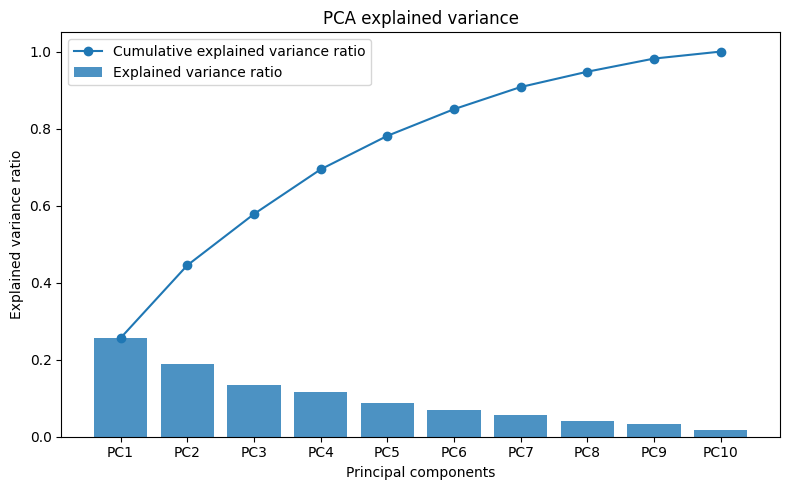

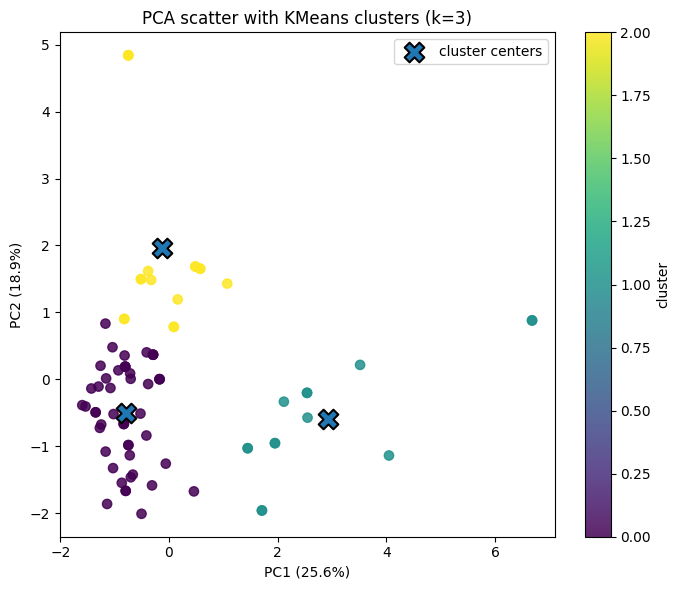

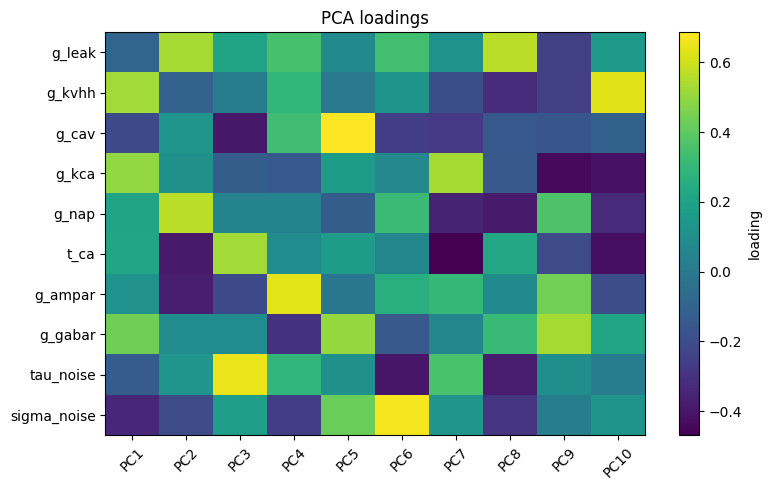

In [12]:
res = run_pca_clustering_hits(
    combined_hits_df,
    n_clusters=3,
    random_state=42,
    save_prefix="combined_hits_pca"
)

df_result = res["df_result"]
loadings = res["loadings"]
cluster_summary_mean = res["cluster_summary_mean"]
cluster_summary_median = res["cluster_summary_median"]

In [ ]:
#U_ramp

rps = anmodel.search.RandomParamSearch(
    model="NET_SAN_STP",
    pattern="TRANSITION",
    ncore=8,
    hr=24,                 # 例：2時間探索
    samp_freq=1000,       # 記録を1ms刻み相当
    samp_len=20000,       # NETでは「ms」として扱われる（>200 のため）
    model_name="NET_SAN_STP_demo",

    # NETの固定設定（必要なら調整）
    NE=16, NI=4,
    net_seed=1,
    p_ee=0.2, p_ei=0.2, p_ie=0.3, p_ii=0.3,
    dt_ms=0.1,            # 内部刻み
    early_ms=(3000, 8000),
    late_ms=(14000, 19000),
    R_sync=0.70,
    R_desync=0.45,
)

rps.multi_singleprocess()


Random search: model=NET_SAN_STP pattern=TRANSITION ncore=8 start_method=spawn


In [ ]:
intrinsic_pickle = "results/SWS_params/2026_2_8_SAN_SAN_example/SWS_2026_2_9_0.pickle"  # 例

sps = anmodel.search.SynOnlySearchFromSANIntrinsic(
    intrinsic_pickle=intrinsic_pickle,
    ncore=8,
    hr=24,
    NE=16,
    NI=4,
    dt_ms=0.1,
    T_ms=20000.0,
    syn_trials_per_intrinsic=200,
    max_intrinsic=1000,      # 必要なら上限
    shuffle_intrinsic=True,
    net_seed_base=123,
    p_ee=0.2, p_ei=0.2, p_ie=0.3, p_ii=0.3,
)

sps.multi_singleprocess()

In [3]:
net_params = {
    # synaptic conductances
    "g_ampar": 0.04,
    "g_gabar": 0.12,

    # vesicle recovery
    "tau_rec_e": 800.0,  # ms
    "tau_rec_i": 500.0,  # ms

    # U ramp
    "U0": 0.02,
    "U1": 0.98,
    "t0_ms": 5000.0,
    "t1_ms": 25000.0,

    # OU noise
    "tau_noise": 5.0,     # ms
    "sigma_noise": 0.03,  # 強すぎると常に脱同期になるので注意
}


R_mean = 0.20836546186412744


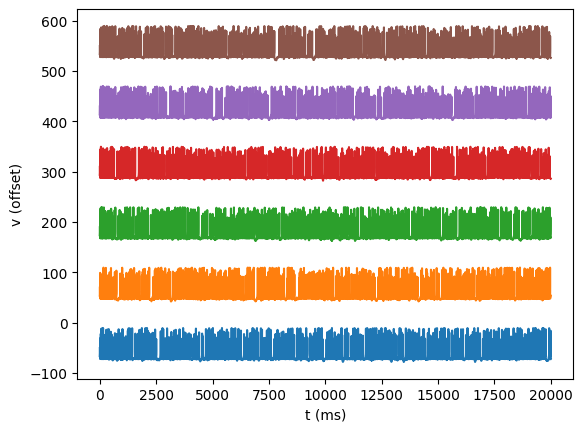

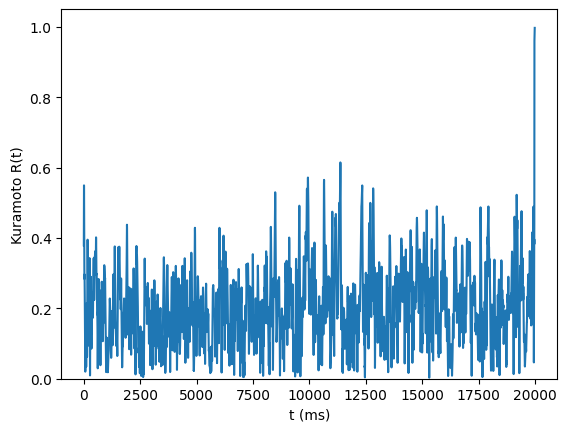

In [4]:

from anmodel.analysis import kuramoto_order_from_v

net = anmodel.SANVesicleNetwork(
    NE=16, NI=4, seed=1,
    p_ee=0.2, p_ei=0.2, p_ie=0.3, p_ii=0.3
)

net.set_network_params(net_params)

# 安定性のため dt=0.1 ms 推奨（記録は 1 ms ごと）
T_ms = 30000.0
dt_ms = 0.1
record_every = int(1.0 / dt_ms)  # 1 msごとに保存

t_ms, v_rec = net.run_fixed_step(T_ms=T_ms, dt_ms=dt_ms, record_every=record_every, reset=True)

# 同期度（Kuramoto order）
sync = kuramoto_order_from_v(v_rec, t_ms, thresh=-20.0)
print("R_mean =", sync["R_mean"])

# 可視化：数ニューロンの膜電位
plt.figure()
for i in range(6):
    plt.plot(t_ms, v_rec[:, i] + i*120)  # 見やすくオフセット
plt.xlabel("t (ms)")
plt.ylabel("v (offset)")
plt.show()

plt.figure()
plt.plot(t_ms, sync["R_t"])
plt.ylim(0, 1.05)
plt.xlabel("t (ms)")
plt.ylabel("Kuramoto R(t)")
plt.show()


In [ ]:

dt = 1000
T = 5000  #ms
an_bool = [
    1,  # leak channel
    1,  # voltage-gated sodium channel
    1,  # HH-type delayed rectifier potassium channel
    1,  # fast A-type potassium channel
    1,  # slowly inactivating potassium channel
    1,  # voltage-gated calcium channel
    1,  # calcium-dependent potassium channel
    1,  # persistent sodium channel
    1,  # inwardly rectifier potassium channel
    1,  # AMPA receptor
    1,  # NMDA receptor
    1,  # GABA receptor
    1,  # calcium pump
]
model_name = "tau900_vec"
rps = anmodel.search.RandomParamSearch(
    model="SAN_NET_TM",
    pattern="SWS",
    ncore=7,
    hr=24,
    samp_freq=1000, # run_fixed_step の dt と単位を合わせるなら後述
    samp_len=T,
    model_name = model_name
    )

rps.multi_singleprocess()

Random search: using 7 cores to explore SWS
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)






core6_iter1       U  sync  mean rate
0  0.08   NaN        0.0
1  0.12   NaN        0.0
2  0.18   NaN        0.0
3  0.28   NaN        0.0
4  0.40   NaN        0.0
5  0.55   NaN        0.0
6  0.70   NaN        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core2_iter1       U      sync  mean rate
0  0.08       NaN   0.000000
1  0.12 -0.003385  13.751375
2  0.18 -0.005226  13.636364
3  0.28  0.006012  13.656366
4  0.40  0.002263  13.666367
5  0.55 -0.008994  13.616362
6  0.70  

6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core6_iter8       U      sync  mean rate
0  0.08  0.006112   2.835284
1  0.12  0.006112   2.835284
2  0.18  0.006112   2.835284
3  0.28  0.006112   2.835284
4  0.40  0.006112   2.835284
5  0.55  0.006112   2.835284
6  0.70  0.006112   2.835284
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core2_iter8       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core4_iter11       U      sync  mean rate
0  0.08  0.772123   5.725573
1  0.12  0.743248   5.795580
2  0.18  0.764618   5.800580
3  0.28  0.788292   5.800580
4  0.40  0.795186   5.800580
5  0.55  0.789460   5.800580
6  0.70  0.797050   5.800580
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core5_iter10  

6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core6_iter12       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core2_iter12       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core5_iter14       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core3_iter14       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0

6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core5_iter19       U  sync  mean rate
0  0.08   NaN        0.0
1  0.12   NaN        0.0
2  0.18   NaN        0.0
3  0.28   NaN        0.0
4  0.40   NaN        0.0
5  0.55   NaN        0.0
6  0.70   NaN        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core4_iter18       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core1_iter15       U      sync  mean rate
0  0.08  0.161684   1.380138
1  0.12  0.161230   1.375138
2  0.18  0.161589   1.375138
3  0.28  0.160815   1.375138
4  0.40  0.160457   1.375138
5  0.55  0.161617   1.375138
6  0.70  0.162500   1.380138
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core6_iter16       U  sync  mean rate
0  0.0

6  0.70   NaN        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core3_iter21       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core5_iter24       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core4_iter22       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core4_iter23       U  sync  mean rate
0  0.08   NaN        0.0
1  0.12   NaN

6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core2_iter25       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core2_iter26       U  sync  mean rate
0  0.08   NaN        0.0
1  0.12   NaN        0.0
2  0.18   NaN        0.0
3  0.28   NaN        0.0
4  0.40   NaN        0.0
5  0.55   NaN        0.0
6  0.70   NaN        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core0_iter25       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core3_iter25       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0

... (10 outputs left out)

6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core2_iter74       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core4_iter78       U      sync   mean rate
0  0.08  0.000271  467.436744
1  0.12 -0.002205  467.271727
2  0.18  0.000198  467.656766
3  0.28  0.006516  467.191719
4  0.40 -0.001509  467.326733
5  0.55 -0.002151  467.541754
6  0.70 -0.004294  467.441744
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core5_iter77       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core1_iter69       U  sync  mean rat

6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core5_iter82       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core1_iter75       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core0_iter79       U      sync   mean rate
0  0.08  0.007324  473.672367
1  0.12 -0.004458  473.737374
2  0.18  0.001938  473.707371
3  0.28 -0.001196  473.857386
4  0.40 -0.000489  473.422342
5  0.55 -0.000101  473.657366
6  0.70  0.013364  473.612361
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core6_iter76       U  sync  mean rat

6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core2_iter82       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core4_iter85       U      sync   mean rate
0  0.08  0.001574  446.229623
1  0.12 -0.000079  446.109611
2  0.18  0.002304  445.924592
3  0.28 -0.004345  446.329633
4  0.40 -0.003094  446.154615
5  0.55 -0.001981  446.454645
6  0.70  0.000756  446.284628
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core5_iter86       U      sync   mean rate
0  0.08 -0.001710  207.975798
1  0.12 -0.006134  208.080808
2  0.18 -0.003624  209.755976
3  0.28 -0.014284  208.450845
4  0.40  0.002972  203.230323
5  0.55  0.007045  211.571157
6  0.70  0.026837  207.525753
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neur

6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core4_iter89       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core5_iter90       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core6_iter84       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0        0.0
2  0.18   0.0        0.0
3  0.28   0.0        0.0
4  0.40   0.0        0.0
5  0.55   0.0        0.0
6  0.70   0.0        0.0
U	SyncIndex(mean pairwise corr, bin=20ms)	MeanRate(spk/s/neuron)
core1_iter84       U  sync  mean rate
0  0.08   0.0        0.0
1  0.12   0.0

In [6]:
an = anmodel_kd.models.SANmodel()

In [8]:
an.params.kd_ca

1.0

In [4]:
v = s[0:, 0]
Pattern = anmodel.analysis.WaveCheck().pattern(v, T)
Pattern         

<WavePattern.AWAKE: 4>

In [5]:
s, info = an.run_odeint()

Text(0, 0.5, 'Membrane Potential (mV)')

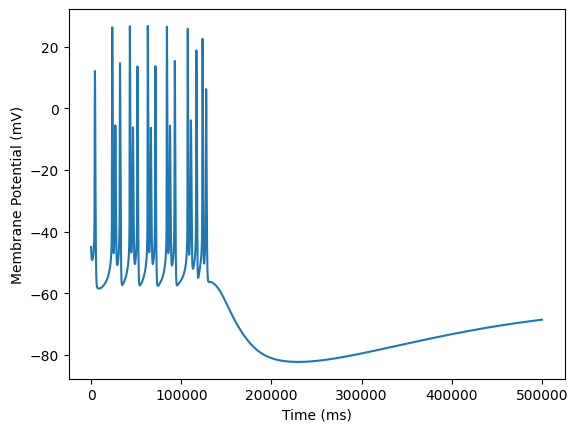

In [14]:
plt.plot(s[0:, 0])
plt.xlabel('Time (ms)')
plt.ylabel('Membrane Potential (mV)')

In [ ]:
als = anmodel.analysis.WaveCheck()

In [ ]:
als.pattern(s[4999:, 0]).name

'SWS'

In [ ]:
san = anmodel.models.SANmodel()

In [ ]:
san.set_sws_params()

In [ ]:
s, info = san.run_odeint()

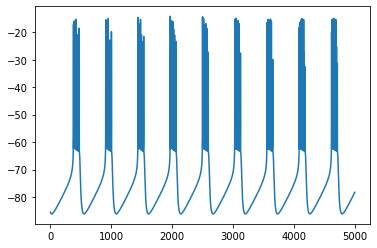

In [ ]:
plt.plot(s[4999:, 0])

In [ ]:
an_bool = [1] * 13
an_x = anmodel.models.Xmodel(channel_bool=an_bool)

In [ ]:
an_x.set_params(anmodel.params.TypicalParam().an_sws)

In [ ]:
s, info = an_x.run_odeint()

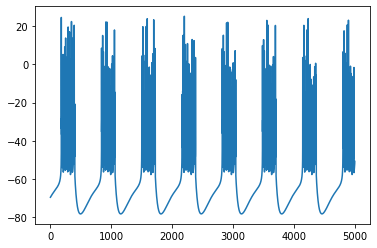

In [ ]:
plt.plot(s[4999:, 0])

In [ ]:
san_bool = [
    1,  # leak channel
    0,  # voltage-gated sodium channel
    1,  # HH-type delayed rectifier potassium channel
    0,  # fast A-type potassium channel
    0,  # slowly inactivating potassium channel
    1,  # voltage-gated calcium channel
    1,  # calcium-dependent potassium channel
    1,  # persistent sodium channel
    0,  # inwardly rectifier potassium channel
    0,  # AMPA receptor
    0,  # NMDA receptor
    0,  # GABA receptor
    1,  # calcium pump
]

In [ ]:
san_x = anmodel.models.Xmodel(channel_bool=san_bool)

In [ ]:
san_x.set_params(anmodel.params.TypicalParam().san_sws)

In [ ]:
s, info = san_x.run_odeint()

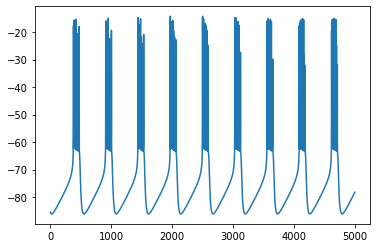

In [ ]:
plt.plot(s[4999:, 0])